In [1]:
# Step 1.1 — Verify Python environment and locate the dataset

from pathlib import Path
import sys
import importlib.util

print("=== PYTHON ENVIRONMENT ===")
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())

print("\n=== REQUIRED PACKAGE CHECK ===")
for package in ["pandas", "numpy", "ipykernel"]:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if available else 'Not installed'}")

print("\n=== DATASET FILE CHECK ===")

filename = "plant_disease_corrected.csv"
search_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
dataset_path = None

for folder in search_locations:
    candidates = [
        folder / "AI" / "Datasets" / filename,
        folder / "Datasets" / filename,
    ]

    for candidate in candidates:
        if candidate.is_file():
            dataset_path = candidate
            break

    if dataset_path is not None:
        break

if dataset_path is not None:
    print("Dataset found:", dataset_path)
    print("File size:", round(dataset_path.stat().st_size / 1024, 2), "KB")
else:
    print("Dataset not found automatically.")
    print("Expected file: AI/Datasets/plant_disease_corrected.csv")

=== PYTHON ENVIRONMENT ===
Python version: 3.13.7
Python executable: c:\Python313\python.exe
Working directory: d:\PlantGuardian\AI\Notebooks

=== REQUIRED PACKAGE CHECK ===
pandas: Installed
numpy: Installed
ipykernel: Installed

=== DATASET FILE CHECK ===
Dataset found: D:\PlantGuardian\AI\Datasets\plant_disease_corrected.csv
File size: 170.87 KB


In [2]:
from IPython.display import display
# Step 1.2 — Load and inspect the corrected dataset

import pandas as pd
from pathlib import Path

DATASET_PATH = Path(
    r"D:\PlantGuardian\AI\Datasets\plant_disease_corrected.csv"
)

# Load the CSV
df = pd.read_csv(DATASET_PATH)

# Inspect the dataset
print("=== DATASET LOADED SUCCESSFULLY ===")
print("File:", DATASET_PATH.name)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== FIRST 5 ROWS ===")
display(df.head())

print("\n=== DATASET MEMORY USAGE ===")
print(f"{df.memory_usage(deep=True).sum() / 1024:.2f} KB")

=== DATASET LOADED SUCCESSFULLY ===
File: plant_disease_corrected.csv
Number of rows: 616
Number of columns: 6

=== COLUMN NAMES ===
['source_row_number', 'crop', 'diagnosis', 'details', 'country', 'state']

=== DATA TYPES ===
source_row_number    int64
crop                   str
diagnosis              str
details                str
country                str
state                  str
dtype: object

=== FIRST 5 ROWS ===


,source_row_number,crop,diagnosis,details,country,state
0,3,Chilli,Thrips,Upward curling and deformation of leaves. Stun...,India,Andhra Pradesh
1,4,Mustard,Aphids,Colonies of aphids on the leaves and pods,India,Bihar
2,5,Cauliflower,Boron Deficiency,Smaller curds in cauliflower due to imbalance ...,India,Bihar
3,6,Chilli,Leaf Curl Virus,The symptoms are of typical Chilli Leaf Curl V...,India,Bihar
4,7,Brinjal,Shoot and Fruit Borer,"Holes in the leaves, seems like shoot borer ca...",India,Bihar



=== DATASET MEMORY USAGE ===
193.01 KB


In [3]:
# Step 1.3 — Verify dataset integrity

print("=== DATASET INTEGRITY CHECK ===")

# 1. Confirm the DataFrame exists and is not empty
print("\n1. Dataset loaded:", isinstance(df, pd.DataFrame))
print("2. Dataset is not empty:", not df.empty)

# 2. Check expected columns
expected_columns = [
    "source_row_number",
    "crop",
    "diagnosis",
    "details",
    "country",
    "state",
]

print("\n3. Expected columns present:",
      all(col in df.columns for col in expected_columns))
print("   Missing expected columns:",
      [col for col in expected_columns if col not in df.columns])

# 3. Check missing values
print("\n4. Missing values per column:")
print(df.isna().sum())

# 4. Check exact duplicate rows
print("\n5. Exact duplicate rows:", df.duplicated().sum())

# 5. Check blank text values
text_columns = ["crop", "diagnosis", "details", "country", "state"]

print("\n6. Blank or whitespace-only values:")
for col in text_columns:
    blank_count = df[col].astype("string").str.strip().eq("").sum()
    print(f"   {col}: {blank_count}")

# 6. Check data types
print("\n7. Data types:")
print(df.dtypes)

# 7. Check source-row references
print("\n8. Source-row references:")
print("   Missing references:", df["source_row_number"].isna().sum())
print("   Duplicate references:", df["source_row_number"].duplicated().sum())

print("\n=== END OF INTEGRITY CHECK ===")

=== DATASET INTEGRITY CHECK ===

1. Dataset loaded: True
2. Dataset is not empty: True

3. Expected columns present: True
   Missing expected columns: []

4. Missing values per column:
source_row_number    0
crop                 0
diagnosis            0
details              0
country              0
state                0
dtype: int64

5. Exact duplicate rows: 0

6. Blank or whitespace-only values:
   crop: 0
   diagnosis: 0
   details: 0
   country: 0
   state: 0

7. Data types:
source_row_number    int64
crop                   str
diagnosis              str
details                str
country                str
state                  str
dtype: object

8. Source-row references:
   Missing references: 0
   Duplicate references: 0

=== END OF INTEGRITY CHECK ===


In [4]:
# Step 2.1 — Dataset overview

print("=== DATASET OVERVIEW ===")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Unique crops: {df['crop'].nunique()}")
print(f"Unique diagnosis labels: {df['diagnosis'].nunique()}")
print(f"Unique countries: {df['country'].nunique()}")
print(f"Unique states: {df['state'].nunique()}")

print("\n=== COLUMN INFORMATION ===")
df.info()

print("\n=== NUMERIC SUMMARY ===")
display(df[["source_row_number"]].describe())

print("\n=== SAMPLE RECORDS ===")
display(df.sample(min(5, len(df)), random_state=42))

=== DATASET OVERVIEW ===
Rows: 616
Columns: 6
Unique crops: 62
Unique diagnosis labels: 73
Unique countries: 1
Unique states: 13

=== COLUMN INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   source_row_number  616 non-null    int64
 1   crop               616 non-null    str  
 2   diagnosis          616 non-null    str  
 3   details            616 non-null    str  
 4   country            616 non-null    str  
 5   state              616 non-null    str  
dtypes: int64(1), str(5)
memory usage: 193.0 KB

=== NUMERIC SUMMARY ===


,source_row_number
count,616.000000
mean,509.637987
std,331.116717
min,3.000000
25%,186.750000
50%,493.500000
75%,849.250000
max,1027.000000



=== SAMPLE RECORDS ===


,source_row_number,crop,diagnosis,details,country,state
78,98,Guava,Phosphorus Deficiency,A purplish or reddish discoloration of older G...,India,Bihar
208,290,Chilli,Mites,Chilli mites – symptoms and control measures\n...,India,Telangana
570,972,Mustard,Healthy,no symptoms observed,India,Bihar
181,227,Lemon,Leaf Miner,The citrus plants affected with leaf miner and...,India,Bihar
101,123,Brinjal,Shoot and Fruit Borer,Leaves with holes and irregular feeding damage...,India,Bihar


In [5]:
# Step 2.2 — Analyze crop-label frequencies

crop_counts = (
    df["crop"]
    .value_counts()
    .rename_axis("crop")
    .reset_index(name="record_count")
)

print("=== CROP FREQUENCY SUMMARY ===")
print("Unique crops:", len(crop_counts))
print("Crops with only 1 record:", (crop_counts["record_count"] == 1).sum())
print("Crops with fewer than 5 records:", (crop_counts["record_count"] < 5).sum())

print("\n=== 20 MOST COMMON CROPS ===")
display(crop_counts.head(20))

print("\n=== CROPS WITH FEWER THAN 5 RECORDS ===")
display(
    crop_counts[crop_counts["record_count"] < 5]
    .sort_values(["record_count", "crop"])
    .reset_index(drop=True)
)

=== CROP FREQUENCY SUMMARY ===
Unique crops: 62
Crops with only 1 record: 20
Crops with fewer than 5 records: 33

=== 20 MOST COMMON CROPS ===


,crop,record_count
0,Chilli,67
1,Maize,64
2,Potato,60
3,Brinjal,41
4,Mango,36
5,Tomato,29
6,Mustard,27
7,Wheat,27
8,Papaya,23
9,Bean,20



=== CROPS WITH FEWER THAN 5 RECORDS ===


,crop,record_count
0,Barley,1
1,Broad bean,1
2,Capsicum,1
3,Carrot,1
4,Chikoo,1
5,Crossandra,1
6,Custard apple,1
7,Fruit trees,1
8,Gram,1
9,Gum,1


In [6]:
# Step 2.3 — Analyze diagnosis-label frequencies

diagnosis_counts = (
    df["diagnosis"]
    .value_counts()
    .rename_axis("diagnosis")
    .reset_index(name="record_count")
)

print("=== DIAGNOSIS FREQUENCY SUMMARY ===")
print("Unique diagnosis labels:", len(diagnosis_counts))
print(
    "Diagnoses with only 1 record:",
    (diagnosis_counts["record_count"] == 1).sum()
)
print(
    "Diagnoses with fewer than 5 records:",
    (diagnosis_counts["record_count"] < 5).sum()
)

print("\n=== 25 MOST COMMON DIAGNOSES ===")
display(diagnosis_counts.head(25))

print("\n=== DIAGNOSES WITH FEWER THAN 5 RECORDS ===")
display(
    diagnosis_counts[diagnosis_counts["record_count"] < 5]
    .sort_values(["record_count", "diagnosis"])
    .reset_index(drop=True)
)

=== DIAGNOSIS FREQUENCY SUMMARY ===
Unique diagnosis labels: 73
Diagnoses with only 1 record: 28
Diagnoses with fewer than 5 records: 49

=== 25 MOST COMMON DIAGNOSES ===


,diagnosis,record_count
0,Healthy,190
1,Fall Armyworm,46
2,Powdery Mildew,37
3,Thrips,31
4,Leaf Curl Virus,31
5,Mites,23
6,Aphids,22
7,Shoot and Fruit Borer,20
8,Anthracnose,18
9,Nitrogen Deficiency,15



=== DIAGNOSES WITH FEWER THAN 5 RECORDS ===


,diagnosis,record_count
0,Alternaria Blight,1
1,Armyworm,1
2,Ascochyta Blight,1
3,Bacterial Blight,1
4,Banana Weevil,1
5,Bark Eating Caterpillar,1
6,Bollworm,1
7,Cabbage Looper,1
8,Cercospora Leaf Spot,1
9,Citrus Canker,1


In [7]:
# Step 2.4 — Identify combined diagnosis labels

diagnosis_text = df["diagnosis"].astype("string").str.strip()

# Detect semicolon-separated labels
combined_mask = diagnosis_text.str.contains(";", regex=False, na=False)

combined_diagnoses = df.loc[
    combined_mask,
    ["source_row_number", "crop", "diagnosis", "details"]
].copy()

print("=== COMBINED DIAGNOSIS CHECK ===")
print("Records with semicolon-separated diagnoses:", len(combined_diagnoses))

if combined_diagnoses.empty:
    print("No semicolon-separated diagnosis labels remain.")
else:
    display(combined_diagnoses)

print("\n=== OTHER POSSIBLE SEPARATORS ===")
for separator, label in [
    ("|", "pipe"),
    ("/", "slash"),
    (" and ", "'and'"),
]:
    count = diagnosis_text.str.contains(
        separator, regex=False, case=False, na=False
    ).sum()
    print(f"Labels containing {label}: {count}")

=== COMBINED DIAGNOSIS CHECK ===
Records with semicolon-separated diagnoses: 0
No semicolon-separated diagnosis labels remain.

=== OTHER POSSIBLE SEPARATORS ===
Labels containing pipe: 0
Labels containing slash: 0
Labels containing 'and': 22


In [8]:
# Step 2.5 — Screen description quality

details = df["details"].astype("string").str.strip()
diagnosis = df["diagnosis"].astype("string").str.strip()

# Basic quality checks
placeholder_mask = details.str.contains(
    r"#NAME\?|^test$|^n/?a$|^unknown$",
    case=False,
    regex=True,
    na=False
)

short_mask = details.str.len() < 30

# Broad warning terms, not proof of a wrong diagnosis
warning_pattern = (
    r"\b(deficiency|deficient|mildew|blight|rot|wilt|virus|"
    r"bacterial|fungal|pest|insect|curl|mosaic|anthracnose)\b"
)

healthy_problem_mask = (
    diagnosis.str.casefold().eq("healthy")
    & details.str.contains(
        warning_pattern,
        case=False,
        regex=True,
        na=False
    )
)

print("=== DESCRIPTION QUALITY SCREEN ===")
print("Placeholder-like descriptions:", int(placeholder_mask.sum()))
print("Descriptions shorter than 30 characters:", int(short_mask.sum()))
print(
    "Healthy labels with potential problem-related wording:",
    int(healthy_problem_mask.sum())
)

review_mask = placeholder_mask | short_mask | healthy_problem_mask

review_columns = [
    "source_row_number", "crop", "diagnosis", "details"
]

print("\n=== RECORDS FLAGGED FOR REVIEW ===")
print("Total flagged rows:", int(review_mask.sum()))

display(
    df.loc[review_mask, review_columns]
    .sort_values(["diagnosis", "crop"])
    .head(30)
)

print("\nShowing at most 30 flagged rows. Original df is unchanged.")

=== DESCRIPTION QUALITY SCREEN ===
Placeholder-like descriptions: 0
Descriptions shorter than 30 characters: 32
Healthy labels with potential problem-related wording: 79

=== RECORDS FLAGGED FOR REVIEW ===
Total flagged rows: 110


C:\Users\SUPRIYO\AppData\Local\Temp\ipykernel_1552\1982966241.py:24: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  & details.str.contains(


,source_row_number,crop,diagnosis,details
482,871,Banana,Healthy,The spots appearing on the leaves are common a...
611,1023,Banana,Healthy,banana seedling is heathy and pigmentation is ...
492,883,Bean,Healthy,Crop: Dolichos bean \nno signs of pest and dis...
503,894,Bitter gourd,Healthy,"Healthy Bitter gourd plants, no disease or pes..."
514,909,Bitter gourd,Healthy,Healthy Bitter gourd plants at growing stage. ...
533,930,Bitter gourd,Healthy,"Healthy bitter gourd plants, at flowering and ..."
454,840,Bottle gourd,Healthy,so signs of pest or disease
487,877,Bottle gourd,Healthy,no symptoms are observed
582,989,Bottle gourd,Healthy,plant is looking healthy
472,860,Brinjal,Healthy,its looks like brinjal plant and no clear dise...



Showing at most 30 flagged rows. Original df is unchanged.


In [9]:
# Step 2.5.1 — Refine review of Healthy descriptions

healthy_df = df[
    df["diagnosis"].str.strip().str.casefold() == "healthy"
].copy()

details_lower = healthy_df["details"].str.lower()

# Terms that may indicate an actual problem
problem_terms = (
    r"\b(deficiency|deficient|mildew|blight|rot|wilt|virus|"
    r"bacterial|fungal|pest|insect|curl|mosaic|anthracnose)\b"
)

# Common wording that often indicates absence of a problem
negation_terms = (
    r"\b(no signs|no symptoms|no disease|no pest|without any symptoms|"
    r"no visible issue|nothing|healthy plant|looks healthy|looking healthy)\b"
)

has_problem_term = details_lower.str.contains(
    problem_terms, regex=True, na=False
)

has_negation = details_lower.str.contains(
    negation_terms, regex=True, na=False
)

suspicious_healthy = healthy_df[has_problem_term & ~has_negation]

print("Healthy records:", len(healthy_df))
print("Healthy records with problem terms:", int(has_problem_term.sum()))
print("Potentially suspicious after basic negation screening:",
      len(suspicious_healthy))

display(
    suspicious_healthy[
        ["source_row_number", "crop", "diagnosis", "details"]
    ].head(40)
)

Healthy records: 190
Healthy records with problem terms: 79
Potentially suspicious after basic negation screening: 21


C:\Users\SUPRIYO\AppData\Local\Temp\ipykernel_1552\2933081256.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_problem_term = details_lower.str.contains(
C:\Users\SUPRIYO\AppData\Local\Temp\ipykernel_1552\2933081256.py:25: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_negation = details_lower.str.contains(


,source_row_number,crop,diagnosis,details
192,252,Onion,Healthy,Leaf Symptoms:\nOlder leaves show marginal chl...
427,767,Broad bean,Healthy,mosaic viruses:Mosaic viruses in which the lea...
446,832,Moringa,Healthy,"No mildew symptoms were identified; however, d..."
454,840,Bottle gourd,Healthy,so signs of pest or disease
459,846,Tobacco,Healthy,the leaves slightly swollen may related to env...
472,860,Brinjal,Healthy,its looks like brinjal plant and no clear dise...
482,871,Banana,Healthy,The spots appearing on the leaves are common a...
483,872,Potato,Healthy,no symptom of pest or disease is observed
498,889,Rice,Healthy,in the given image rice crop is seen but pest ...
511,906,Mustard,Healthy,"No visible signs of powdery mildew, white rust..."


In [10]:
# Step 2.5.2 — Display complete suspicious Healthy descriptions

review_ids = suspicious_healthy["source_row_number"].tolist()

for _, row in suspicious_healthy.iterrows():
    print("=" * 80)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Full details:")
    print(row["details"])
    print()

Source row: 252
Crop: Onion
Diagnosis: Healthy
Full details:
Leaf Symptoms:
Older leaves show marginal chlorosis (yellowing at leaf edges).
Leaves develop necrotic spots or die back from the tip.
Leaf tips may curl or scorch.
Stunted leaf growth, pale green color.
measures:
Apply potassium fertilizers such as:
Muriate of Potash (KCl) – commonly used.
Sulfate of Potash (K2SO4) – preferred if sulfur is also needed.
Dosage: Typically, 30–60 kg K₂O/ha depending on soil test results.

Source row: 767
Crop: Broad bean
Diagnosis: Healthy
Full details:
mosaic viruses:Mosaic viruses in which the leaves show sharply defined patches of unusual coloration may occur in beans.
control measures:There are no recommended chemical controls for these problems.

Source row: 832
Crop: Moringa
Diagnosis: Healthy
Full details:
No mildew symptoms were identified; however, dust deposition was present on the leaf surfaces

Source row: 840
Crop: Bottle gourd
Diagnosis: Healthy
Full details:
so signs of pest or d

In [11]:
# Step 2.5.2 — Display the first 5 suspicious Healthy records

for _, row in suspicious_healthy.iloc[:5].iterrows():
    print("=" * 70)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Full details:")
    print(row["details"])
    print()

Source row: 252
Crop: Onion
Diagnosis: Healthy
Full details:
Leaf Symptoms:
Older leaves show marginal chlorosis (yellowing at leaf edges).
Leaves develop necrotic spots or die back from the tip.
Leaf tips may curl or scorch.
Stunted leaf growth, pale green color.
measures:
Apply potassium fertilizers such as:
Muriate of Potash (KCl) – commonly used.
Sulfate of Potash (K2SO4) – preferred if sulfur is also needed.
Dosage: Typically, 30–60 kg K₂O/ha depending on soil test results.

Source row: 767
Crop: Broad bean
Diagnosis: Healthy
Full details:
mosaic viruses:Mosaic viruses in which the leaves show sharply defined patches of unusual coloration may occur in beans.
control measures:There are no recommended chemical controls for these problems.

Source row: 832
Crop: Moringa
Diagnosis: Healthy
Full details:
No mildew symptoms were identified; however, dust deposition was present on the leaf surfaces

Source row: 840
Crop: Bottle gourd
Diagnosis: Healthy
Full details:
so signs of pest or d

In [12]:
# Step 2.5.2 — Display suspicious Healthy records 6–10

for _, row in suspicious_healthy.iloc[5:10].iterrows():
    print("=" * 70)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Full details:")
    print(row["details"])
    print()

Source row: 860
Crop: Brinjal
Diagnosis: Healthy
Full details:
its looks like brinjal plant and no clear disease of nutrient deficiency is visible

Source row: 871
Crop: Banana
Diagnosis: Healthy
Full details:
The spots appearing on the leaves are common and are not caused by any pest or disease.

Source row: 872
Crop: Potato
Diagnosis: Healthy
Full details:
no symptom of pest or disease is observed

Source row: 889
Crop: Rice
Diagnosis: Healthy
Full details:
in the given image rice crop is seen but pest and disease symptoms are not able to found

Source row: 906
Crop: Mustard
Diagnosis: Healthy
Full details:
No visible signs of powdery mildew, white rust, or insect damage on the flowers.

The plant appears healthy in its flowering stage.



In [13]:
# Step 2.5 — Review suspicious Healthy records 11–15

batch = suspicious_healthy.iloc[10:15]

for _, row in batch.iterrows():
    print("=" * 70)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Full details:")
    print(row["details"])
    print()

Source row: 926
Crop: Wheat
Diagnosis: Healthy
Full details:
Healthy wheat crops ,requires balanced fertiliser dose along with irrigation at critical stages.. Monitoring the crop for early detection of pest and diseases.

Source row: 927
Crop: Canola
Diagnosis: Healthy
Full details:
Healthy canola plants at flowering stage, requires balanced fertiliser dose. Monitoring the crop for early detection of pest and diseases.

Source row: 942
Crop: Tomato
Diagnosis: Healthy
Full details:
soft watery lesions on ripe tomato fruit 

Reasons
Mechanical injury during harvesting, packing, or transport

Post-harvest bacterial soft rot entering through wounds

Over-mature fruits with weak skin

High humidity and poor ventilation after harvest

Symptoms
Water-soaked, soft patches on fruits

Tissue becomes mushy and collapses

Foul smell in advanced stages

Rapid spread to nearby fruits

Control / management
Harvest at breaker–pink stage, avoid over-ripening

Handle fruits gently; avoid bruising

Remov

In [14]:
# Step 2.5 — Review the final suspicious Healthy records

for _, row in suspicious_healthy.iloc[15:21].iterrows():
    print("=" * 70)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Full details:")
    print(row["details"])
    print()

Source row: 959
Crop: Tomato
Diagnosis: Healthy
Full details:
Tomato leaves whitish and curling . Heat and low moisture can cause the edges of the tomato leaves to die back, then twist and curl. Hot dry weather may also cause a symptom called physiological leaf roll.
Irrigate regularly and do not allow the soil to dry completely to a wilting point.

Source row: 981
Crop: Mustard
Diagnosis: Healthy
Full details:
Mustard flowers are healthy without any pest or disease symptoms

Source row: 1002
Crop: Tomato
Diagnosis: Healthy
Full details:
Tomato fruit rot is primarily controlled by maintaining dry conditions, using staking to prevent soil contact, and applying fungicides like Dithane M-45, Bordeaux mixture, or copper-based sprays.

Source row: 1006
Crop: Potato
Diagnosis: Healthy
Full details:
only beneficial insect lady bird beetle is seen in the image

Source row: 1012
Crop: Red Gram
Diagnosis: Healthy
Full details:
crop is looking  healthy and pest and disease symptoms are not visibl

In [15]:
# Step 2.6 — Dataset quality summary

print("=" * 60)
print("PLANTGUARDIAN DATASET QUALITY SUMMARY")
print("=" * 60)

print(f"Total records: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"Unique crops: {df['crop'].nunique()}")
print(f"Unique diagnosis labels: {df['diagnosis'].nunique()}")
print(f"Unique countries: {df['country'].nunique()}")
print(f"Unique states: {df['state'].nunique()}")

print("\n--- Data integrity ---")
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print(
    "Duplicate source row numbers:",
    int(df["source_row_number"].duplicated().sum())
)

print("\n--- Description quality ---")
print(
    "Descriptions shorter than 30 characters:",
    int(df["details"].astype("string").str.strip().str.len().lt(30).sum())
)

print("\n--- Healthy-label review ---")
print(
    "Records labelled Healthy:",
    int(df["diagnosis"].astype("string").str.strip().str.casefold().eq("healthy").sum())
)
print(
    "Suspicious Healthy records flagged for review:",
    len(suspicious_healthy)
)

print("\n--- Rare categories ---")
print("Crop labels appearing fewer than 5 times:",
      int((df["crop"].value_counts() < 5).sum()))
print("Diagnosis labels appearing fewer than 5 times:",
      int((df["diagnosis"].value_counts() < 5).sum()))

print("\n--- Cleaning decision ---")
print("Preserve source_row_number for traceability.")
print("Do not automatically delete rare categories.")
print("Do not automatically change diagnosis labels.")
print("Keep the original CSV unchanged.")
print("Review flagged records manually before using them as evidence.")

PLANTGUARDIAN DATASET QUALITY SUMMARY
Total records: 616
Total columns: 6
Unique crops: 62
Unique diagnosis labels: 73
Unique countries: 1
Unique states: 13

--- Data integrity ---
Missing values: 0
Exact duplicate rows: 0
Duplicate source row numbers: 0

--- Description quality ---
Descriptions shorter than 30 characters: 32

--- Healthy-label review ---
Records labelled Healthy: 190
Suspicious Healthy records flagged for review: 21

--- Rare categories ---
Crop labels appearing fewer than 5 times: 33
Diagnosis labels appearing fewer than 5 times: 49

--- Cleaning decision ---
Preserve source_row_number for traceability.
Do not automatically delete rare categories.
Do not automatically change diagnosis labels.
Keep the original CSV unchanged.
Review flagged records manually before using them as evidence.


In [16]:
# Step 3.1 — Inspect crop names and diagnosis labels

print("=" * 60)
print("CROP LABELS")
print("=" * 60)

crop_labels = sorted(df["crop"].dropna().unique())

for crop in crop_labels:
    print(crop)

print("\nTotal unique crop labels:", len(crop_labels))

print("\n" + "=" * 60)
print("DIAGNOSIS LABELS")
print("=" * 60)

diagnosis_labels = sorted(df["diagnosis"].dropna().unique())

for diagnosis in diagnosis_labels:
    print(diagnosis)

print("\nTotal unique diagnosis labels:", len(diagnosis_labels))

CROP LABELS
Banana
Barley
Bean
Bitter gourd
Bottle gourd
Brinjal
Broad bean
Cabbage
Canola
Capsicum
Carrot
Cauliflower
Chickpea
Chikoo
Chilli
Citrus
Coriander
Cotton
Cowpea
Crossandra
Cucumber
Custard apple
Fruit trees
Garlic
Gram
Green Gram
Groundnut
Guava
Gum
Kidney bean
Lady's Finger
Lemon
Lemongrass
Maize
Mango
Marigold
Medicinal plants
Moringa
Mustard
Onion
Paddy
Papaya
Pea
Pearl millet
Peas
Pepper
Potato
Pumpkin
Radish
Red Gram
Rice
Ridge gourd
Rose
Spinach
Sponge gourd
Squash
Strawberry
Tobacco
Tomato
Turmeric
Watermelon
Wheat

Total unique crop labels: 62

DIAGNOSIS LABELS
Alternaria Blight
Anthracnose
Aphids
Armyworm
Ascochyta Blight
Bacterial Blight
Bacterial Canker
Bacterial Wilt
Banana Weevil
Banded Leaf and Sheath Blight
Bark Eating Caterpillar
Black Rot
Blast
Bollworm
Boron Deficiency
Cabbage Looper
Calcium Deficiency
Cercospora Leaf Spot
Citrus Canker
Citrus Psyllid
Collar Rot
Common Scab
Cucumber Beetle
Cutworms
Diamondback Moth
Downy Mildew
Early Blight
Fall Armyworm
F

In [17]:
# Step 3.1 — Compare candidate crop-name variants

candidate_groups = [
    ["Pea", "Peas"],
    ["Paddy", "Rice"],
    ["Chickpea", "Gram"],
    ["Bean", "Kidney bean", "Broad bean", "Green Gram"],
]

for group in candidate_groups:
    print("\n" + "=" * 60)
    print("Candidate group:", " / ".join(group))

    subset = df[df["crop"].isin(group)]

    if subset.empty:
        print("No matching records found.")
        continue

    summary = (
        subset.groupby(["crop", "diagnosis"], dropna=False)
        .size()
        .rename("record_count")
        .reset_index()
        .sort_values(["crop", "record_count"], ascending=[True, False])
    )

    print(summary.to_string(index=False))


Candidate group: Pea / Peas
crop      diagnosis  record_count
 Pea Powdery Mildew             2
 Pea           Rust             1
Peas        Healthy             3

Candidate group: Paddy / Rice
 crop            diagnosis  record_count
Paddy                Blast             4
Paddy              Healthy             2
Paddy           Stem Borer             2
Paddy Potassium Deficiency             1
 Rice              Healthy             8
 Rice                Blast             2
 Rice  Nitrogen Deficiency             1
 Rice             Rice Bug             1
 Rice           Stem Borer             1

Candidate group: Chickpea / Gram
    crop           diagnosis  record_count
Chickpea             Healthy             6
Chickpea       Fusarium Wilt             2
Chickpea    Ascochyta Blight             1
Chickpea Nitrogen Deficiency             1
Chickpea              Thrips             1
    Gram      Powdery Mildew             1

Candidate group: Bean / Kidney bean / Broad bean / Green G

In [18]:
# Step 3.1 — Check crop and diagnosis label formatting

for column in ["crop", "diagnosis"]:
    values = df[column].astype("string")

    print("\n" + "=" * 60)
    print(f"Formatting check: {column}")
    print("=" * 60)

    print(
        "Values with leading/trailing whitespace:",
        int(values.ne(values.str.strip()).sum())
    )

    print(
        "Values containing uppercase/lowercase variants "
        "of an otherwise identical label:"
    )

    normalized = values.str.strip().str.casefold()
    variant_counts = (
        df.assign(_normalized=normalized)
        .groupby("_normalized")[column]
        .nunique()
    )

    variants = variant_counts[variant_counts > 1].index.tolist()

    if variants:
        for key in variants:
            print(df.loc[normalized == key, column].unique().tolist())
    else:
        print("None found.")


Formatting check: crop
Values with leading/trailing whitespace: 0
Values containing uppercase/lowercase variants of an otherwise identical label:
None found.

Formatting check: diagnosis
Values with leading/trailing whitespace: 0
Values containing uppercase/lowercase variants of an otherwise identical label:
None found.


In [19]:
# Step 3.2 — Create normalized crop and diagnosis columns

df["crop_normalized"] = (
    df["crop"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

df["diagnosis_normalized"] = (
    df["diagnosis"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Verify original columns remain unchanged and inspect the results
print("Original crop column preserved:", "crop" in df.columns)
print("Original diagnosis column preserved:", "diagnosis" in df.columns)

print("\nNew columns created:")
print(df[[
    "crop",
    "crop_normalized",
    "diagnosis",
    "diagnosis_normalized"
]].head(10).to_string(index=False))

print("\nUnique original crop labels:", df["crop"].nunique())
print("Unique normalized crop labels:", df["crop_normalized"].nunique())

print("\nUnique original diagnosis labels:", df["diagnosis"].nunique())
print("Unique normalized diagnosis labels:", df["diagnosis_normalized"].nunique())

Original crop column preserved: True
Original diagnosis column preserved: True

New columns created:
       crop crop_normalized             diagnosis  diagnosis_normalized
     Chilli          chilli                Thrips                thrips
    Mustard         mustard                Aphids                aphids
Cauliflower     cauliflower      Boron Deficiency      boron deficiency
     Chilli          chilli       Leaf Curl Virus       leaf curl virus
    Brinjal         brinjal Shoot and Fruit Borer shoot and fruit borer
     Potato          potato    Calcium Deficiency    calcium deficiency
     Chilli          chilli           Anthracnose           anthracnose
      Wheat           wheat   Nitrogen Deficiency   nitrogen deficiency
    Pumpkin         pumpkin   Nitrogen Deficiency   nitrogen deficiency
     Tomato          tomato       Leaf Curl Virus       leaf curl virus

Unique original crop labels: 62
Unique normalized crop labels: 62

Unique original diagnosis labels: 73
Un

In [20]:
# Step 3.2 — Validate normalized columns (corrected)

print("Total rows:", len(df))

print("\nMissing values in normalized columns:")
print(df[["crop_normalized", "diagnosis_normalized"]].isna().sum())

crop_mismatches = (
    df["crop_normalized"]
    != df["crop"].astype("string").str.strip().str.casefold()
).sum()

diagnosis_mismatches = (
    df["diagnosis_normalized"]
    != df["diagnosis"].astype("string").str.strip().str.casefold()
).sum()

print("\nCrop normalization mismatches:", int(crop_mismatches))
print("Diagnosis normalization mismatches:", int(diagnosis_mismatches))

print(
    "\nOriginal columns preserved:",
    "crop" in df.columns and "diagnosis" in df.columns
)

Total rows: 616

Missing values in normalized columns:
crop_normalized         0
diagnosis_normalized    0
dtype: int64

Crop normalization mismatches: 0
Diagnosis normalization mismatches: 0

Original columns preserved: True


In [21]:
# Step 3.3 — Inspect description text quality

print("Total descriptions:", len(df))
print("Missing descriptions:", int(df["details"].isna().sum()))

details_text = df["details"].astype("string")

print(
    "Empty descriptions:",
    int(details_text.str.strip().eq("").sum())
)

print(
    "Descriptions with leading/trailing whitespace:",
    int(details_text.ne(details_text.str.strip()).sum())
)

print("\nDescription length statistics:")
print(details_text.str.len().describe())

print("\nSample descriptions:")
for _, row in df[["source_row_number", "crop", "diagnosis", "details"]].head(5).iterrows():
    print("-" * 60)
    print("Source row:", row["source_row_number"])
    print("Crop:", row["crop"])
    print("Diagnosis:", row["diagnosis"])
    print("Details:", row["details"])

Total descriptions: 616
Missing descriptions: 0
Empty descriptions: 0
Descriptions with leading/trailing whitespace: 0

Description length statistics:
count         616.0
mean     241.415584
std      196.620486
min            17.0
25%            79.0
50%           195.0
75%           355.5
max          1081.0
Name: details, dtype: Float64

Sample descriptions:
------------------------------------------------------------
Source row: 3
Crop: Chilli
Diagnosis: Thrips
Details: Upward curling and deformation of leaves. Stunted growth.
------------------------------------------------------------
Source row: 4
Crop: Mustard
Diagnosis: Aphids
Details: Colonies of aphids on the leaves and pods
------------------------------------------------------------
Source row: 5
Crop: Cauliflower
Diagnosis: Boron Deficiency
Details: Smaller curds in cauliflower due to imbalance nutrient supply and deficiency of Boron can aggravate the condition.
------------------------------------------------------------


In [22]:
# Step 3.3 — Create cleaned description text

df["details_clean"] = (
    df["details"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Original details column preserved:", "details" in df.columns)
print("Cleaned details column created:", "details_clean" in df.columns)
print("Missing cleaned descriptions:", int(df["details_clean"].isna().sum()))
print("Empty cleaned descriptions:", int(df["details_clean"].eq("").sum()))

print("\nOriginal vs cleaned examples:")
for _, row in df[["source_row_number", "details", "details_clean"]].head(5).iterrows():
    print("-" * 60)
    print("Source row:", row["source_row_number"])
    print("Original:", row["details"])
    print("Cleaned: ", row["details_clean"])

Original details column preserved: True
Cleaned details column created: True
Missing cleaned descriptions: 0
Empty cleaned descriptions: 0

Original vs cleaned examples:
------------------------------------------------------------
Source row: 3
Original: Upward curling and deformation of leaves. Stunted growth.
Cleaned:  Upward curling and deformation of leaves. Stunted growth.
------------------------------------------------------------
Source row: 4
Original: Colonies of aphids on the leaves and pods
Cleaned:  Colonies of aphids on the leaves and pods
------------------------------------------------------------
Source row: 5
Original: Smaller curds in cauliflower due to imbalance nutrient supply and deficiency of Boron can aggravate the condition.
Cleaned:  Smaller curds in cauliflower due to imbalance nutrient supply and deficiency of Boron can aggravate the condition.
------------------------------------------------------------
Source row: 6
Original: The symptoms are of typical Ch

In [23]:
# Step 3.3 — Validate cleaned descriptions

changed_descriptions = (
    df["details"].astype("string") != df["details_clean"]
)

print("Total records:", len(df))
print("Descriptions changed by whitespace cleaning:", int(changed_descriptions.sum()))
print("Missing cleaned descriptions:", int(df["details_clean"].isna().sum()))
print("Empty cleaned descriptions:", int(df["details_clean"].str.strip().eq("").sum()))
print("Original details column preserved:", "details" in df.columns)

print("\nColumns currently available:")
print(df.columns.tolist())

Total records: 616
Descriptions changed by whitespace cleaning: 256
Missing cleaned descriptions: 0
Empty cleaned descriptions: 0
Original details column preserved: True

Columns currently available:
['source_row_number', 'crop', 'diagnosis', 'details', 'country', 'state', 'crop_normalized', 'diagnosis_normalized', 'details_clean']


In [24]:
# Step 3.4 — Build the evidence database

evidence_db = df[
    [
        "source_row_number",
        "crop",
        "crop_normalized",
        "diagnosis",
        "diagnosis_normalized",
        "details_clean",
        "country",
        "state",
    ]
].copy()

# Give the cleaned description a clear name for downstream matching
evidence_db = evidence_db.rename(
    columns={"details_clean": "evidence_text"}
)

# Validate the evidence database
print("Evidence database created successfully.")
print("Rows:", len(evidence_db))
print("Columns:", evidence_db.columns.tolist())

print("\nMissing values:")
print(evidence_db.isna().sum())

print("\nDuplicate source references:",
      int(evidence_db["source_row_number"].duplicated().sum()))

print("\nSample evidence records:")
print(evidence_db.head(5).to_string(index=False))

print("\nOriginal dataset unchanged in row count:", len(df) == 616)

Evidence database created successfully.
Rows: 616
Columns: ['source_row_number', 'crop', 'crop_normalized', 'diagnosis', 'diagnosis_normalized', 'evidence_text', 'country', 'state']

Missing values:
source_row_number       0
crop                    0
crop_normalized         0
diagnosis               0
diagnosis_normalized    0
evidence_text           0
country                 0
state                   0
dtype: int64

Duplicate source references: 0

Sample evidence records:
 source_row_number        crop crop_normalized             diagnosis  diagnosis_normalized                                                                                                      evidence_text country          state
                 3      Chilli          chilli                Thrips                thrips                                                          Upward curling and deformation of leaves. Stunted growth.   India Andhra Pradesh
                 4     Mustard         mustard                Ap

In [25]:
%pip install python-dotenv requests

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
# Step 4.1 — Check API dependency

import requests

print("Requests version:", requests.__version__)
print("OpenRouter API endpoint configured:",
      "https://openrouter.ai/api/v1/chat/completions")

Requests version: 2.32.5
OpenRouter API endpoint configured: https://openrouter.ai/api/v1/chat/completions


In [27]:
# Step 4.2 — Load OpenRouter API key securely

from pathlib import Path
from dotenv import load_dotenv
import os

current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if p.name == "PlantGuardian"),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "PlantGuardian folder not found from the notebook's working directory."
    )

env_file = project_root / ".env"

if not env_file.is_file():
    raise FileNotFoundError(f".env file not found: {env_file}")

load_dotenv(env_file, override=True)

api_key = os.getenv("OR_API_KEY")

if not api_key:
    raise ValueError(
        "OR_API_KEY is missing. Check the variable name in .env."
    )

print("Project root found:", project_root)
print(".env file found:", env_file.is_file())
print("API key loaded successfully:", bool(api_key))
print("API key value hidden for security.")

Project root found: D:\PlantGuardian
.env file found: True
API key loaded successfully: True
API key value hidden for security.


In [28]:
# Step 4.3 — Test OpenRouter API access

import requests

url = "https://openrouter.ai/api/v1/models"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {api_key}"},
    timeout=30
)

print("HTTP status code:", response.status_code)

if response.status_code == 200:
    print("OpenRouter API authentication successful.")
    models_data = response.json().get("data", [])
    print("Number of models returned:", len(models_data))
else:
    print("OpenRouter API request failed.")
    print("Response:", response.text[:500])

HTTP status code: 200
OpenRouter API authentication successful.
Number of models returned: 467


In [29]:
# Step 4.4 — Find vision-capable OpenRouter models

models_response = requests.get(
    "https://openrouter.ai/api/v1/models",
    headers={"Authorization": f"Bearer {api_key}"},
    timeout=30
)
models_response.raise_for_status()

all_models = models_response.json().get("data", [])

vision_models = [
    model for model in all_models
    if "image" in model.get("architecture", {}).get("input_modalities", [])
]

print("Total vision-capable models:", len(vision_models))
print("\nFirst 20 vision models (ID and input pricing):\n")

for model in vision_models[:20]:
    pricing = model.get("pricing", {})
    print(
        f"Model: {model.get('id', 'unknown')} | "
        f"Input price per 1M tokens: "
        f"{float(pricing.get('prompt', 0) or 0) * 1_000_000:.4f}"
    )

Total vision-capable models: 308

First 20 vision models (ID and input pricing):

Model: moonshotai/kimi-k3.1-pro | Input price per 1M tokens: 2.0000
Model: minimax/minimax-m3.1-flash | Input price per 1M tokens: 0.1500
Model: deepseek/deepseek-v4.1-flash-1017 | Input price per 1M tokens: 0.1500
Model: elorian/glimpse | Input price per 1M tokens: 0.6000
Model: moondream/moondream3-preview | Input price per 1M tokens: 0.3000
Model: moondream/moondream3.1-9b-a2b | Input price per 1M tokens: 0.3000
Model: meta/muse-spark-open | Input price per 1M tokens: 1.2500
Model: nvidia/nemotron-3.5-super-vl | Input price per 1M tokens: 0.1500
Model: nvidia/nemotron-3.5-super-vl:free | Input price per 1M tokens: 0.0000
Model: unbiased/pareto-26.10 | Input price per 1M tokens: 0.8000
Model: ~unbiased/pareto-latest | Input price per 1M tokens: 0.8000
Model: unbiased/pareto-26.9 | Input price per 1M tokens: 2.5000
Model: google/gemini-4-argon | Input price per 1M tokens: 2.0000
Model: google/gemini-4-ar

In [30]:
# Step 4.4 — Test a vision model with a plant image

import base64
import mimetypes
from pathlib import Path
import requests

MODEL_ID = "nvidia/nemotron-3.5-super-vl:free"
IMAGE_PATH = Path(r"D:\PlantGuardian\AI\Datasets\plant_test.jpg")

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Plant test image not found: {IMAGE_PATH}\n"
        "Save the generated image at this path, or update IMAGE_PATH."
    )

mime_type = mimetypes.guess_type(IMAGE_PATH.name)[0] or "image/jpeg"

with IMAGE_PATH.open("rb") as image_file:
    image_base64 = base64.b64encode(image_file.read()).decode("utf-8")

payload = {
    "model": MODEL_ID,
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": (
                        "Analyze this plant image for a plant-health screening tool. "
                        "Describe only visible features: likely plant type, leaf color "
                        "changes, spots, lesions, curling, and damage. Give possible "
                        "causes only as uncertain candidates. Do not claim a confirmed "
                        "disease from the image alone. If plant identity is uncertain, "
                        "say so."
                    ),
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:{mime_type};base64,{image_base64}"
                    },
                },
            ],
        }
    ],
    "max_tokens": 400,
}

response = requests.post(
    "https://openrouter.ai/api/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json",
    },
    json=payload,
    timeout=90,
)

print("HTTP status:", response.status_code)

if response.ok:
    result = response.json()
    print("Model:", result.get("model", MODEL_ID))
    print("\nVision model response:\n")
    print(result["choices"][0]["message"]["content"])
else:
    print("Request failed:")
    print(response.text[:1000])

HTTP status: 200
Model: nvidia/nemotron-3.5-super-vl:free

Vision model response:

None


In [31]:
# Step 4.4 — Inspect the model response structure

result = response.json()

print("Response ID:", result.get("id"))
print("Model returned:", result.get("model"))

choices = result.get("choices", [])
print("Number of choices:", len(choices))

if choices:
    choice = choices[0]
    message = choice.get("message", {})

    print("\nFinish reason:", choice.get("finish_reason"))
    print("Message role:", message.get("role"))
    print("Message content type:", type(message.get("content")).__name__)
    print("Message content:", repr(message.get("content")))
    print("Refusal:", message.get("refusal"))
    print("Reasoning present:", bool(message.get("reasoning")))
else:
    print("\nNo choices returned.")
    print("Response keys:", list(result.keys()))
    print("Error details:", result.get("error"))

Response ID: gen-1792944739-QCFIWYcu7xpkZRiPamIy
Model returned: nvidia/nemotron-3.5-super-vl:free
Number of choices: 1

Finish reason: length
Message role: assistant
Message content type: NoneType
Message content: None
Refusal: None
Reasoning present: True


In [32]:
# Step 4.4 — Retry vision test with a larger output budget

payload["max_tokens"] = 1000
payload["messages"][0]["content"][0]["text"] = (
    "Describe this plant image in 4 short bullet points: "
    "1. likely plant, 2. visible leaf symptoms, "
    "3. possible causes, 4. uncertainty. "
    "Do not claim a confirmed diagnosis."
)

response = requests.post(
    "https://openrouter.ai/api/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json",
    },
    json=payload,
    timeout=90,
)

print("HTTP status:", response.status_code)

if response.ok:
    result = response.json()
    choice = result.get("choices", [{}])[0]
    message = choice.get("message", {})
    content = message.get("content")

    print("Finish reason:", choice.get("finish_reason"))
    print("Model:", result.get("model"))
    print("\nModel response:")
    print(content if content else "No text returned.")
else:
    print("Request failed:", response.text[:1000])

HTTP status: 200
Finish reason: stop
Model: nvidia/nemotron-3.5-super-vl:free

Model response:
* **Likely plant:** Appears to be a tomato plant, based on the compound leaf structure and hairy stems.
*   **Visible leaf symptoms:** Significant yellowing (chlorosis) with dark brown to black necrotic spots and tissue decay, especially along the leaf edges and center.
*   **Possible causes:** Symptoms may suggest a fungal disease (such as Early Blight), bacterial infection, or nutrient deficiency, but this is speculative.
*   **Uncertainty:** No confirmed diagnosis can be made from the image alone; further inspection or testing would be needed.


In [33]:
MODEL_ID = "nvidia/nemotron-3.5-super-vl:free"

print("Vision model configured:", MODEL_ID)

Vision model configured: nvidia/nemotron-3.5-super-vl:free


In [34]:
assert MODEL_ID == "nvidia/nemotron-3.5-super-vl:free"
assert api_key, "OR_API_KEY is not loaded"

print("Model configuration: OK")
print("API key availability: OK")

Model configuration: OK
API key availability: OK


In [35]:
PLANT_ANALYSIS_PROMPT = """
You are a plant-health screening assistant.

Analyze the supplied plant image and report only observations supported
by the visible image.

Return the following information:

1. Likely plant or crop:
   - Give the likely crop name.
   - If uncertain, say "unknown".

2. Visible symptoms:
   - Leaf color changes.
   - Spots, lesions, or unusual markings.
   - Curling, wilting, drying, or deformation.
   - Any visible damage to stems, fruits, or other plant parts.

3. Possible causes:
   - List plausible disease, pest, nutrient, or environmental causes
     only when supported by visible symptoms.
   - Treat these as possibilities, not confirmed diagnoses.
   - Do not invent symptoms or evidence.

4. Confidence and limitations:
   - State whether the plant identification is uncertain.
   - Explain if the image quality or viewing angle limits analysis.
   - Do not claim a confirmed diagnosis from an image alone.

5. Summary:
   - Provide a concise summary of the visible plant-health concerns.

Do not recommend pesticides or treatments.
Do not assume that a crop or disease exists in the supplied dataset.
Do not force a diagnosis when the evidence is insufficient.
"""
print(PLANT_ANALYSIS_PROMPT)


You are a plant-health screening assistant.

Analyze the supplied plant image and report only observations supported
by the visible image.

Return the following information:

1. Likely plant or crop:
   - Give the likely crop name.
   - If uncertain, say "unknown".

2. Visible symptoms:
   - Leaf color changes.
   - Spots, lesions, or unusual markings.
   - Curling, wilting, drying, or deformation.
   - Any visible damage to stems, fruits, or other plant parts.

3. Possible causes:
   - List plausible disease, pest, nutrient, or environmental causes
     only when supported by visible symptoms.
   - Treat these as possibilities, not confirmed diagnoses.
   - Do not invent symptoms or evidence.

4. Confidence and limitations:
   - State whether the plant identification is uncertain.
   - Explain if the image quality or viewing angle limits analysis.
   - Do not claim a confirmed diagnosis from an image alone.

5. Summary:
   - Provide a concise summary of the visible plant-health conce

In [36]:
assert isinstance(PLANT_ANALYSIS_PROMPT, str)
assert len(PLANT_ANALYSIS_PROMPT.strip()) > 0

payload["messages"][0]["content"][0]["text"] = PLANT_ANALYSIS_PROMPT

print("Prompt connected to API payload: OK")
print("Prompt length:", len(PLANT_ANALYSIS_PROMPT), "characters")
print("API request sent: No")

Prompt connected to API payload: OK
Prompt length: 1178 characters
API request sent: No


In [37]:
payload["max_tokens"] = 800

response = requests.post(
    "https://openrouter.ai/api/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json"
    },
    json=payload,
    timeout=90
)

print("HTTP status:", response.status_code)

response.raise_for_status()
result = response.json()

choice = result.get("choices", [{}])[0]
message = choice.get("message", {})
content = message.get("content")

print("Model:", result.get("model"))
print("Finish reason:", choice.get("finish_reason"))
print("\nModel response:")
print(content if content else "No text returned.")

HTTP status: 200
Model: nvidia/nemotron-3.5-super-vl:free
Finish reason: length

Model response:
No text returned.


In [38]:
choice = result.get("choices", [{}])[0]
message = choice.get("message", {})

print("Finish reason:", choice.get("finish_reason"))
print("Message keys:", list(message.keys()))
print("Content:", repr(message.get("content")))
print("Reasoning present:", bool(message.get("reasoning")))
print("Usage:", result.get("usage"))

Finish reason: length
Message keys: ['role', 'content', 'refusal', 'reasoning', 'reasoning_details']
Content: None
Reasoning present: True
Usage: {'prompt_tokens': 1829, 'completion_tokens': 800, 'total_tokens': 2629, 'cost': 0, 'is_byok': False, 'prompt_tokens_details': {'cached_tokens': 0, 'cache_write_tokens': 0, 'audio_tokens': 0, 'video_tokens': 0}, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}, 'completion_tokens_details': {'reasoning_tokens': 800, 'image_tokens': 0, 'audio_tokens': 0}}


In [39]:
MODEL_TEST = "moondream/moondream3-preview"

payload["model"] = MODEL_TEST
payload["max_tokens"] = 300
payload["messages"][0]["content"][0]["text"] = (
    "Describe the visible plant, leaf symptoms, and possible causes. "
    "Keep the answer under 100 words. Do not claim a confirmed diagnosis."
)

response = requests.post(
    "https://openrouter.ai/api/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json"
    },
    json=payload,
    timeout=90
)

print("HTTP status:", response.status_code)
response.raise_for_status()

result = response.json()
choice = result.get("choices", [{}])[0]
message = choice.get("message", {})

print("Model:", result.get("model"))
print("Finish reason:", choice.get("finish_reason"))
print("Response:", message.get("content") or "No text returned.")

HTTP status: 200
Model: moondream/moondream3-preview
Finish reason: stop
Response: A close-up shows a leaf with yellowing and brown spots, likely due to nutrient deficiencies or pest damage. Possible causes include insufficient light, nutrient imbalance, or pest infestation.


In [40]:
MODEL_ID = "moondream/moondream3-preview"

print("Selected vision model:", MODEL_ID)
print("Prompt configured:", bool(PLANT_ANALYSIS_PROMPT.strip()))

Selected vision model: moondream/moondream3-preview
Prompt configured: True


In [41]:
from pathlib import Path

IMAGE_PATH = Path(r"D:\PlantGuardian\AI\Datasets\plant_test.jpg")

assert MODEL_ID == "moondream/moondream3-preview"
assert isinstance(PLANT_ANALYSIS_PROMPT, str) and PLANT_ANALYSIS_PROMPT.strip()
assert api_key, "OR_API_KEY is not loaded"
assert IMAGE_PATH.is_file(), f"Test image not found: {IMAGE_PATH}"

print("Vision model: OK")
print("Analysis prompt: OK")
print("OR_API_KEY availability: OK")
print("Test image: OK")
print("API request sent: No")

Vision model: OK
Analysis prompt: OK
OR_API_KEY availability: OK
Test image: OK
API request sent: No


In [42]:
assert "evidence_db" in globals(), "evidence_db is not defined"

required_columns = {
    "source_row_number",
    "crop",
    "crop_normalized",
    "diagnosis",
    "diagnosis_normalized",
    "evidence_text",
    "country",
    "state"
}

missing_columns = required_columns - set(evidence_db.columns)

assert not missing_columns, f"Missing columns: {missing_columns}"

print("Evidence database: OK")
print("Records:", len(evidence_db))
print("Columns:", list(evidence_db.columns))
print("Missing values:", int(evidence_db[list(required_columns)].isna().sum().sum()))

Evidence database: OK
Records: 616
Columns: ['source_row_number', 'crop', 'crop_normalized', 'diagnosis', 'diagnosis_normalized', 'evidence_text', 'country', 'state']
Missing values: 0


In [43]:
visual_findings = {
    "crop": "unknown",
    "visible_symptoms": [
        "yellowing",
        "brown spots",
        "irregular leaf edges"
    ],
    "possible_causes": [
        "nutrient deficiency",
        "watering issues",
        "pest damage"
    ],
    "diagnosis_confirmed": False
}

print("Visual findings prepared:", bool(visual_findings))
print("Crop:", visual_findings["crop"])
print("Symptoms:", visual_findings["visible_symptoms"])
print("Confirmed diagnosis:", visual_findings["diagnosis_confirmed"])

Visual findings prepared: True
Crop: unknown
Symptoms: ['yellowing', 'brown spots', 'irregular leaf edges']
Confirmed diagnosis: False


In [44]:
symptom_keywords = [
    "yellowing",
    "yellow",
    "brown spots",
    "brown spot",
    "leaf spots",
    "leaf spot",
    "irregular leaf edges"
]

evidence_db["evidence_search_text"] = (
    evidence_db["diagnosis_normalized"].fillna("") + " " +
    evidence_db["evidence_text"].fillna("").str.casefold()
)

pattern = "|".join(
    __import__("re").escape(word) for word in symptom_keywords
)

matched_evidence = evidence_db[
    evidence_db["evidence_search_text"].str.contains(
        pattern, regex=True, na=False
    )
].copy()

print("Matching evidence records:", len(matched_evidence))
print("Unique crops:", matched_evidence["crop"].nunique())
print("Unique diagnoses:", matched_evidence["diagnosis"].nunique())

display(
    matched_evidence[
        ["source_row_number", "crop", "diagnosis", "evidence_text"]
    ].head(10)
)

Matching evidence records: 125
Unique crops: 32
Unique diagnoses: 42


,source_row_number,crop,diagnosis,evidence_text
7,11,Wheat,Nitrogen Deficiency,yellowing of leaves
8,12,Pumpkin,Nitrogen Deficiency,yellowing of leaves
12,18,Paddy,Potassium Deficiency,Dark green plants with yellowish Leaf tips and...
17,23,Banana,Panama Wilt,Leaf spots coalesce to form yellowish brown le...
30,39,Cauliflower,Black Rot,"yellowing, browning/wilting from the edges and..."
38,49,Brinjal,Mites,"Mites infested leaves, yellowish brown dots an..."
41,52,Potato,Early Blight,Leaf spots visible are signs of early blight i...
48,63,Brinjal,Wilt,"Complete wilting of the plant was observed, wh..."
58,73,Chilli,Leaf Curl Virus,symptoms: -Leaf cupping: Upward or downward cu...
72,92,Bean,Powdery Mildew,Crop: Dolichos bean Downey mildew -Pale yellow...


In [45]:
import re

symptom_groups = {
    "yellowing": ["yellowing", "yellow", "yellowish", "chlorosis"],
    "brown_spots": ["brown spots", "brown spot", "brown dots"],
    "leaf_edges": ["irregular leaf edges", "leaf margins", "leaf edges"]
}

def score_evidence(text):
    text = str(text).casefold()
    matched_groups = [
        group for group, terms in symptom_groups.items()
        if any(re.search(r"\b" + re.escape(term) + r"\b", text)
               for term in terms)
    ]
    return len(matched_groups), matched_groups

scores = matched_evidence["evidence_search_text"].apply(score_evidence)

matched_evidence["symptom_score"] = scores.apply(lambda x: x[0])
matched_evidence["matched_symptoms"] = scores.apply(
    lambda x: ", ".join(x[1]) if x[1] else "none"
)

ranked_evidence = matched_evidence.sort_values(
    by=["symptom_score", "source_row_number"],
    ascending=[False, True]
).copy()

display(
    ranked_evidence[
        ["source_row_number", "crop", "diagnosis",
         "symptom_score", "matched_symptoms", "evidence_text"]
    ].head(15)
)

,source_row_number,crop,diagnosis,symptom_score,matched_symptoms,evidence_text
38,49,Brinjal,Mites,2,"yellowing, brown_spots","Mites infested leaves, yellowish brown dots an..."
170,208,Potato,Early Blight,2,"yellowing, brown_spots",Symptoms: Notable symptoms include yellowing o...
192,252,Onion,Healthy,2,"yellowing, leaf_edges",Leaf Symptoms: Older leaves show marginal chlo...
230,337,Lady's Finger,Jassids,2,"yellowing, leaf_edges",Bhendi (okra) jassid – damage Symptoms: Yellow...
233,340,Groundnut,Leaf Spot,2,"yellowing, brown_spots","Symptoms-Leaf spot Small, circular to irregula..."
286,448,Potato,Late Blight,2,"yellowing, leaf_edges",Potato – Holes from leaf edges + medium holes ...
289,454,Potato,Early Blight,2,"yellowing, brown_spots",Early blight (Alternaria) – Symptoms: Small br...
314,514,Rice,Blast,2,"yellowing, brown_spots",Dark Brown Spindle-Shaped Spots with Yellow Ha...
322,538,Papaya,Papaya Ring Spot Virus,2,"yellowing, brown_spots",Leaf margin yellowing (chlorosis) Small brown ...
323,544,Bean,Bacterial Blight,2,"yellowing, brown_spots",Crop: Bush bean -Brown spots with yellow halo ...


In [46]:
print("Records by symptom score:")
print(
    ranked_evidence["symptom_score"]
    .value_counts()
    .sort_index(ascending=False)
)

print("\nHighest-scoring records:")
display(
    ranked_evidence.loc[
        ranked_evidence["symptom_score"].eq(
            ranked_evidence["symptom_score"].max()
        ),
        [
            "source_row_number",
            "crop",
            "diagnosis",
            "symptom_score",
            "matched_symptoms",
            "evidence_text"
        ]
    ].head(10)
)

Records by symptom score:
symptom_score
2     16
1    100
0      9
Name: count, dtype: int64

Highest-scoring records:


,source_row_number,crop,diagnosis,symptom_score,matched_symptoms,evidence_text
38,49,Brinjal,Mites,2,"yellowing, brown_spots","Mites infested leaves, yellowish brown dots an..."
170,208,Potato,Early Blight,2,"yellowing, brown_spots",Symptoms: Notable symptoms include yellowing o...
192,252,Onion,Healthy,2,"yellowing, leaf_edges",Leaf Symptoms: Older leaves show marginal chlo...
230,337,Lady's Finger,Jassids,2,"yellowing, leaf_edges",Bhendi (okra) jassid – damage Symptoms: Yellow...
233,340,Groundnut,Leaf Spot,2,"yellowing, brown_spots","Symptoms-Leaf spot Small, circular to irregula..."
286,448,Potato,Late Blight,2,"yellowing, leaf_edges",Potato – Holes from leaf edges + medium holes ...
289,454,Potato,Early Blight,2,"yellowing, brown_spots",Early blight (Alternaria) – Symptoms: Small br...
314,514,Rice,Blast,2,"yellowing, brown_spots",Dark Brown Spindle-Shaped Spots with Yellow Ha...
322,538,Papaya,Papaya Ring Spot Virus,2,"yellowing, brown_spots",Leaf margin yellowing (chlorosis) Small brown ...
323,544,Bean,Bacterial Blight,2,"yellowing, brown_spots",Crop: Bush bean -Brown spots with yellow halo ...


In [47]:
import re

# Specific phrases are more informative than generic "yellow" alone.
specific_symptom_groups = {
    "yellowing": [
        "yellowing", "yellowish", "chlorosis", "yellow halo"
    ],
    "brown_spots": [
        "brown spots", "brown spot", "brown dots",
        "dark brown spots", "necrotic spots", "leaf spot"
    ],
    "leaf_edge_damage": [
        "leaf edges", "leaf margins", "marginal browning",
        "browning along the edges", "dry leaf margins"
    ]
}

def find_symptom_matches(text):
    text = str(text).casefold()
    matched = []

    for group, terms in specific_symptom_groups.items():
        if any(
            re.search(r"\b" + re.escape(term) + r"\b", text)
            for term in terms
        ):
            matched.append(group)

    return matched

# Work from the existing matched records; do not alter the original CSV.
disease_candidates = matched_evidence[
    ~matched_evidence["diagnosis_normalized"].str.contains(
        r"\bhealthy\b", na=False, regex=True
    )
].copy()

results = disease_candidates["evidence_search_text"].apply(
    find_symptom_matches
)

disease_candidates["symptom_score_v2"] = results.apply(len)
disease_candidates["matched_symptoms_v2"] = results.apply(
    lambda items: ", ".join(items) if items else "none"
)

ranked_candidates_v2 = disease_candidates.sort_values(
    ["symptom_score_v2", "source_row_number"],
    ascending=[False, True]
).copy()

print("Disease candidates (Healthy excluded):", len(ranked_candidates_v2))
print("Candidates matching 2+ symptom groups:",
      int((ranked_candidates_v2["symptom_score_v2"] >= 2).sum()))

display(
    ranked_candidates_v2[
        [
            "source_row_number", "crop", "diagnosis",
            "symptom_score_v2", "matched_symptoms_v2", "evidence_text"
        ]
    ].head(10)
)

Disease candidates (Healthy excluded): 122
Candidates matching 2+ symptom groups: 11


,source_row_number,crop,diagnosis,symptom_score_v2,matched_symptoms_v2,evidence_text
38,49,Brinjal,Mites,2,"yellowing, brown_spots","Mites infested leaves, yellowish brown dots an..."
170,208,Potato,Early Blight,2,"yellowing, brown_spots",Symptoms: Notable symptoms include yellowing o...
230,337,Lady's Finger,Jassids,2,"yellowing, leaf_edge_damage",Bhendi (okra) jassid – damage Symptoms: Yellow...
233,340,Groundnut,Leaf Spot,2,"yellowing, brown_spots","Symptoms-Leaf spot Small, circular to irregula..."
289,454,Potato,Early Blight,2,"yellowing, brown_spots",Early blight (Alternaria) – Symptoms: Small br...
314,514,Rice,Blast,2,"yellowing, brown_spots",Dark Brown Spindle-Shaped Spots with Yellow Ha...
322,538,Papaya,Papaya Ring Spot Virus,2,"yellowing, brown_spots",Leaf margin yellowing (chlorosis) Small brown ...
323,544,Bean,Bacterial Blight,2,"yellowing, brown_spots",Crop: Bush bean -Brown spots with yellow halo ...
344,579,Groundnut,Leaf Spot,2,"yellowing, brown_spots",Cercospora leaf spot in groundnut Symptoms Sma...
354,598,Groundnut,Leaf Spot,2,"yellowing, brown_spots",Groundnut Leaf Spot Symptoms Small brown to da...


In [48]:
vision_crop = visual_findings.get("crop", "unknown")

if not vision_crop or vision_crop.strip().casefold() in {
    "unknown", "uncertain", "not sure", "none"
}:
    print("Crop identification: UNKNOWN")
    print("Crop-aware filtering: SKIPPED")
    print("Reason: The vision model did not identify the crop.")
else:
    print("Crop identification:", vision_crop)
    print("Crop-aware filtering: Can be considered")

Crop identification: UNKNOWN
Crop-aware filtering: SKIPPED
Reason: The vision model did not identify the crop.


In [49]:
top_candidates = ranked_candidates_v2[
    ranked_candidates_v2["symptom_score_v2"] >= 2
].copy()

candidate_summary = (
    top_candidates
    .groupby(["crop", "diagnosis"], dropna=False)
    .agg(
        records=("source_row_number", "count"),
        source_rows=("source_row_number", list)
    )
    .reset_index()
    .sort_values(["records", "crop"], ascending=[False, True])
)

print("High-scoring candidate records:", len(top_candidates))
print("Unique crop-diagnosis pairs:", len(candidate_summary))

display(candidate_summary)

High-scoring candidate records: 11
Unique crop-diagnosis pairs: 7


,crop,diagnosis,records,source_rows
2,Groundnut,Leaf Spot,4,"[340, 579, 598, 615]"
5,Potato,Early Blight,2,"[208, 454]"
0,Bean,Bacterial Blight,1,[544]
1,Brinjal,Mites,1,[49]
3,Lady's Finger,Jassids,1,[337]
4,Papaya,Papaya Ring Spot Virus,1,[538]
6,Rice,Blast,1,[514]


In [50]:
from pathlib import Path

output_path = Path(r"D:\PlantGuardian\AI\Datasets\plant_matching_candidates.csv")

ranked_candidates_v2.to_csv(output_path, index=False)

print("Matching results saved:", output_path.is_file())
print("Saved records:", len(ranked_candidates_v2))
print("Original dataset modified: No")

Matching results saved: True
Saved records: 122
Original dataset modified: No


In [51]:
from pathlib import Path
import pandas as pd

candidates_path = Path(
    r"D:\PlantGuardian\AI\Datasets\plant_matching_candidates.csv"
)

candidates = pd.read_csv(candidates_path)

print("Candidate file loaded:", candidates_path.is_file())
print("Records:", len(candidates))
print("Required columns present:", all(
    col in candidates.columns
    for col in [
        "crop", "diagnosis", "symptom_score_v2",
        "matched_symptoms_v2", "evidence_text"
    ]
))
print("Original evidence database records:", len(evidence_db))

Candidate file loaded: True
Records: 122
Required columns present: True
Original evidence database records: 616


In [52]:
# Step 7.2: Initial candidate relevance scoring

candidates["symptom_component"] = (
    candidates["symptom_score_v2"].fillna(0) / 3
)

candidates["evidence_component"] = (
    candidates["evidence_text"]
    .fillna("")
    .str.strip()
    .ne("")
    .astype(float)
)

# Crop is unknown, so do not award or penalize crop compatibility.
candidates["crop_component"] = 0.0

candidates["relevance_score"] = (
    0.70 * candidates["symptom_component"]
    + 0.30 * candidates["evidence_component"]
)

ranked_candidates = candidates.sort_values(
    ["relevance_score", "source_row_number"],
    ascending=[False, True]
).copy()

print("Ranking algorithm created: OK")
print("Candidates ranked:", len(ranked_candidates))
print("Crop compatibility applied: No (crop unknown)")
print("Score range:",
      round(ranked_candidates["relevance_score"].min(), 3),
      "to",
      round(ranked_candidates["relevance_score"].max(), 3))

display(
    ranked_candidates[
        ["crop", "diagnosis", "symptom_score_v2",
         "evidence_component", "relevance_score"]
    ].head(10)
)

Ranking algorithm created: OK
Candidates ranked: 122
Crop compatibility applied: No (crop unknown)
Score range: 0.3 to 0.767


,crop,diagnosis,symptom_score_v2,evidence_component,relevance_score
0,Brinjal,Mites,2,1.0,0.766667
1,Potato,Early Blight,2,1.0,0.766667
2,Lady's Finger,Jassids,2,1.0,0.766667
3,Groundnut,Leaf Spot,2,1.0,0.766667
4,Potato,Early Blight,2,1.0,0.766667
5,Rice,Blast,2,1.0,0.766667
6,Papaya,Papaya Ring Spot Virus,2,1.0,0.766667
7,Bean,Bacterial Blight,2,1.0,0.766667
8,Groundnut,Leaf Spot,2,1.0,0.766667
9,Groundnut,Leaf Spot,2,1.0,0.766667


In [53]:
print("Score distribution:")
print(
    ranked_candidates["relevance_score"]
    .value_counts()
    .sort_index(ascending=False)
    .head(10)
)

print("\nAverage score by symptom overlap:")
display(
    ranked_candidates.groupby("symptom_score_v2")["relevance_score"]
    .agg(["count", "mean", "min", "max"])
    .sort_index(ascending=False)
)

print("\nTop candidate records:")
display(
    ranked_candidates[
        [
            "source_row_number",
            "crop",
            "diagnosis",
            "symptom_score_v2",
            "relevance_score"
        ]
    ].head(10)
)

Score distribution:
relevance_score
0.766667    11
0.533333    73
0.300000    38
Name: count, dtype: int64

Average score by symptom overlap:


,count,mean,min,max
symptom_score_v2,,,,
2,11,0.766667,0.766667,0.766667
1,73,0.533333,0.533333,0.533333
0,38,0.300000,0.300000,0.300000



Top candidate records:


,source_row_number,crop,diagnosis,symptom_score_v2,relevance_score
0,49,Brinjal,Mites,2,0.766667
1,208,Potato,Early Blight,2,0.766667
2,337,Lady's Finger,Jassids,2,0.766667
3,340,Groundnut,Leaf Spot,2,0.766667
4,454,Potato,Early Blight,2,0.766667
5,514,Rice,Blast,2,0.766667
6,538,Papaya,Papaya Ring Spot Virus,2,0.766667
7,544,Bean,Bacterial Blight,2,0.766667
8,579,Groundnut,Leaf Spot,2,0.766667
9,598,Groundnut,Leaf Spot,2,0.766667


In [54]:
def crop_compatibility(candidate_crop, observed_crop):
    if not observed_crop or observed_crop.strip().casefold() == "unknown":
        return None  # Unknown: do not reward or penalize

    return (
        str(candidate_crop).strip().casefold()
        == observed_crop.strip().casefold()
    )

vision_crop = visual_findings.get("crop", "unknown")

ranked_candidates["crop_compatible"] = ranked_candidates["crop"].apply(
    lambda crop: crop_compatibility(crop, vision_crop)
)

print("Observed crop:", vision_crop)
print(
    "Crop compatibility:",
    "neutral (unknown)" if ranked_candidates["crop_compatible"].isna().all()
    else "calculated"
)
print("Candidates retained:", len(ranked_candidates))

Observed crop: unknown
Crop compatibility: neutral (unknown)
Candidates retained: 122


In [55]:
# Final baseline weights
SYMPTOM_WEIGHT = 0.70
EVIDENCE_WEIGHT = 0.30

ranked_candidates["final_relevance_score"] = (
    SYMPTOM_WEIGHT * ranked_candidates["symptom_component"]
    + EVIDENCE_WEIGHT * ranked_candidates["evidence_component"]
)

ranked_candidates = ranked_candidates.sort_values(
    ["final_relevance_score", "source_row_number"],
    ascending=[False, True]
).copy()

print("Final score calculated: OK")
print("Candidates:", len(ranked_candidates))
print(
    "Score range:",
    round(ranked_candidates["final_relevance_score"].min(), 3),
    "to",
    round(ranked_candidates["final_relevance_score"].max(), 3)
)

display(
    ranked_candidates[
        ["source_row_number", "crop", "diagnosis",
         "symptom_score_v2", "crop_compatible",
         "final_relevance_score"]
    ].head(10)
)

Final score calculated: OK
Candidates: 122
Score range: 0.3 to 0.767


,source_row_number,crop,diagnosis,symptom_score_v2,crop_compatible,final_relevance_score
0,49,Brinjal,Mites,2,None,0.766667
1,208,Potato,Early Blight,2,None,0.766667
2,337,Lady's Finger,Jassids,2,None,0.766667
3,340,Groundnut,Leaf Spot,2,None,0.766667
4,454,Potato,Early Blight,2,None,0.766667
5,514,Rice,Blast,2,None,0.766667
6,538,Papaya,Papaya Ring Spot Virus,2,None,0.766667
7,544,Bean,Bacterial Blight,2,None,0.766667
8,579,Groundnut,Leaf Spot,2,None,0.766667
9,598,Groundnut,Leaf Spot,2,None,0.766667


In [56]:
assert ranked_candidates["final_relevance_score"].notna().all()

assert ranked_candidates["final_relevance_score"].is_monotonic_decreasing

highest_score = ranked_candidates["final_relevance_score"].max()
top_candidates = ranked_candidates[
    ranked_candidates["final_relevance_score"] == highest_score
]

print("Scores valid:", True)
print("Ranking sorted correctly:", True)
print("Highest relevance score:", round(highest_score, 3))
print("Candidates tied at highest score:", len(top_candidates))

display(
    top_candidates[
        ["source_row_number", "crop", "diagnosis", "evidence_text"]
    ]
)

Scores valid: True
Ranking sorted correctly: True
Highest relevance score: 0.767
Candidates tied at highest score: 11


,source_row_number,crop,diagnosis,evidence_text
0,49,Brinjal,Mites,"Mites infested leaves, yellowish brown dots an..."
1,208,Potato,Early Blight,Symptoms: Notable symptoms include yellowing o...
2,337,Lady's Finger,Jassids,Bhendi (okra) jassid – damage Symptoms: Yellow...
3,340,Groundnut,Leaf Spot,"Symptoms-Leaf spot Small, circular to irregula..."
4,454,Potato,Early Blight,Early blight (Alternaria) – Symptoms: Small br...
5,514,Rice,Blast,Dark Brown Spindle-Shaped Spots with Yellow Ha...
6,538,Papaya,Papaya Ring Spot Virus,Leaf margin yellowing (chlorosis) Small brown ...
7,544,Bean,Bacterial Blight,Crop: Bush bean -Brown spots with yellow halo ...
8,579,Groundnut,Leaf Spot,Cercospora leaf spot in groundnut Symptoms Sma...
9,598,Groundnut,Leaf Spot,Groundnut Leaf Spot Symptoms Small brown to da...


In [57]:
import re

# Terms describing the symptoms reported by the vision model
observed_symptom_terms = [
    "yellowing",
    "yellow",
    "brown spots",
    "brown spot",
    "brown dots",
    "leaf edges",
    "leaf margins",
    "irregular leaf edges"
]

def symptom_term_coverage(text):
    text = str(text).casefold()
    found = [
        term for term in observed_symptom_terms
        if re.search(r"\b" + re.escape(term) + r"\b", text)
    ]
    return len(found) / len(observed_symptom_terms), found

coverage_results = ranked_candidates["evidence_text"].apply(
    symptom_term_coverage
)

ranked_candidates["term_coverage_score"] = coverage_results.apply(
    lambda item: item[0]
)

ranked_candidates["matched_terms"] = coverage_results.apply(
    lambda item: ", ".join(item[1]) if item[1] else "none"
)

# Combine existing group score with the new term-coverage score.
ranked_candidates["improved_relevance_score"] = (
    0.70 * ranked_candidates["symptom_component"]
    + 0.20 * ranked_candidates["term_coverage_score"]
    + 0.10 * ranked_candidates["evidence_component"]
)

ranked_candidates = ranked_candidates.sort_values(
    ["improved_relevance_score", "source_row_number"],
    ascending=[False, True]
).copy()

print("Improved ranking created: OK")
print("Candidates:", len(ranked_candidates))
print("Highest score:", round(
    ranked_candidates["improved_relevance_score"].max(), 3
))
print("Top-score ties:", int(
    ranked_candidates["improved_relevance_score"].eq(
        ranked_candidates["improved_relevance_score"].max()
    ).sum()
))

display(
    ranked_candidates[
        [
            "source_row_number", "crop", "diagnosis",
            "symptom_score_v2", "term_coverage_score",
            "matched_terms", "improved_relevance_score"
        ]
    ].head(10)
)

Improved ranking created: OK
Candidates: 122
Highest score: 0.617
Top-score ties: 8


,source_row_number,crop,diagnosis,symptom_score_v2,term_coverage_score,matched_terms,improved_relevance_score
1,208,Potato,Early Blight,2,0.250,"yellowing, brown spots",0.616667
2,337,Lady's Finger,Jassids,2,0.250,"yellowing, leaf margins",0.616667
3,340,Groundnut,Leaf Spot,2,0.250,"yellow, brown spots",0.616667
4,454,Potato,Early Blight,2,0.250,"yellowing, brown spots",0.616667
5,514,Rice,Blast,2,0.250,"yellow, brown spots",0.616667
6,538,Papaya,Papaya Ring Spot Virus,2,0.250,"yellowing, brown spots",0.616667
7,544,Bean,Bacterial Blight,2,0.250,"yellow, brown spots",0.616667
8,579,Groundnut,Leaf Spot,2,0.250,"yellow, brown spots",0.616667
0,49,Brinjal,Mites,2,0.125,brown dots,0.591667
9,598,Groundnut,Leaf Spot,2,0.125,yellow,0.591667


In [58]:
diagnosis_summary = (
    ranked_candidates
    .groupby(["crop", "diagnosis"], dropna=False)
    .agg(
        evidence_records=("source_row_number", "count"),
        best_score=("improved_relevance_score", "max"),
        matched_terms=("matched_terms", lambda s: "; ".join(
            dict.fromkeys(term for item in s for term in item.split(", ")
                          if term != "none")
        )),
        source_rows=("source_row_number", list)
    )
    .reset_index()
    .sort_values(
        ["best_score", "evidence_records"],
        ascending=[False, False]
    )
)

print("Unique crop-diagnosis summaries:", len(diagnosis_summary))

display(diagnosis_summary.head(10))

Unique crop-diagnosis summaries: 69


,crop,diagnosis,evidence_records,best_score,matched_terms,source_rows
33,Groundnut,Leaf Spot,7,0.616667,yellow; brown spots,"[340, 579, 598, 615, 255, 284, 390]"
47,Papaya,Papaya Ring Spot Virus,3,0.616667,yellowing; brown spots,"[538, 113, 318]"
52,Potato,Early Blight,3,0.616667,yellowing; brown spots,"[208, 454, 52]"
3,Bean,Bacterial Blight,1,0.616667,yellow; brown spots,[544]
36,Lady's Finger,Jassids,1,0.616667,yellowing; leaf margins,[337]
57,Rice,Blast,1,0.616667,yellow; brown spots,[514]
10,Brinjal,Mites,7,0.591667,brown dots; yellowing; yellow,"[49, 186, 400, 218, 291, 441, 520]"
18,Chilli,Leaf Curl Virus,8,0.383333,yellow; leaf margins; yellowing,"[735, 751, 73, 166, 179, 401, 553, 161]"
21,Chilli,Thrips,3,0.383333,yellow; leaf margins,"[585, 588, 589]"
42,Onion,Thrips,3,0.383333,yellowing; yellow,"[747, 483, 624]"


In [59]:
from pathlib import Path
import pandas as pd

output_dir = Path(r"D:\PlantGuardian\AI\Datasets")
output_dir.mkdir(parents=True, exist_ok=True)

ranked_path = output_dir / "plant_ranked_candidates.csv"
summary_path = output_dir / "plant_diagnosis_summary.csv"

ranked_candidates.to_csv(ranked_path, index=False)
diagnosis_summary.to_csv(summary_path, index=False)

# Reload both files to verify that they were saved correctly.
ranked_check = pd.read_csv(ranked_path)
summary_check = pd.read_csv(summary_path)

print("Ranked candidates saved:", ranked_path.is_file())
print("Ranked candidate records:", len(ranked_check))
print("Diagnosis summaries saved:", summary_path.is_file())
print("Diagnosis summary records:", len(summary_check))
print("Original dataset modified: No")

Ranked candidates saved: True
Ranked candidate records: 122
Diagnosis summaries saved: True
Diagnosis summary records: 69
Original dataset modified: No


In [60]:
print("Ranked candidate columns:")
print(ranked_candidates.columns.tolist())

print("\nDiagnosis summary columns:")
print(diagnosis_summary.columns.tolist())

print("\nTop candidate for explanation:")
display(
    ranked_candidates[
        [
            "crop",
            "diagnosis",
            "matched_symptoms_v2",
            "matched_terms",
            "improved_relevance_score",
            "evidence_text"
        ]
    ].head(3)
)

Ranked candidate columns:
['source_row_number', 'crop', 'crop_normalized', 'diagnosis', 'diagnosis_normalized', 'evidence_text', 'country', 'state', 'evidence_search_text', 'symptom_score', 'matched_symptoms', 'symptom_score_v2', 'matched_symptoms_v2', 'symptom_component', 'evidence_component', 'crop_component', 'relevance_score', 'crop_compatible', 'final_relevance_score', 'term_coverage_score', 'matched_terms', 'improved_relevance_score']

Diagnosis summary columns:
['crop', 'diagnosis', 'evidence_records', 'best_score', 'matched_terms', 'source_rows']

Top candidate for explanation:


,crop,diagnosis,matched_symptoms_v2,matched_terms,improved_relevance_score,evidence_text
1,Potato,Early Blight,"yellowing, brown_spots","yellowing, brown spots",0.616667,Symptoms: Notable symptoms include yellowing o...
2,Lady's Finger,Jassids,"yellowing, leaf_edge_damage","yellowing, leaf margins",0.616667,Bhendi (okra) jassid – damage Symptoms: Yellow...
3,Groundnut,Leaf Spot,"yellowing, brown_spots","yellow, brown spots",0.616667,"Symptoms-Leaf spot Small, circular to irregula..."


In [61]:
def explain_candidate(row):
    matched = row["matched_terms"]

    if pd.isna(matched) or not str(matched).strip() or matched == "none":
        symptom_reason = "No configured symptom terms matched the evidence text."
    else:
        symptom_reason = f"Matched symptom terms: {matched}."

    crop = str(row["crop"])
    crop_note = (
        "Crop compatibility was not assessed because the observed crop is unknown."
        if visual_findings.get("crop", "unknown").casefold() == "unknown"
        else f"Dataset crop label: {crop}."
    )

    return (
        f"Candidate: {crop} — {row['diagnosis']}. "
        f"{symptom_reason} {crop_note} "
        "This is a text-based candidate, not a confirmed diagnosis."
    )

ranked_candidates["explanation"] = ranked_candidates.apply(
    explain_candidate, axis=1
)

print("Explanations generated:", ranked_candidates["explanation"].notna().sum())
print("\nExample explanations:")

display(
    ranked_candidates[
        ["crop", "diagnosis", "matched_terms",
         "improved_relevance_score", "explanation"]
    ].head(5)
)

Explanations generated: 122

Example explanations:


,crop,diagnosis,matched_terms,improved_relevance_score,explanation
1,Potato,Early Blight,"yellowing, brown spots",0.616667,Candidate: Potato — Early Blight. Matched symp...
2,Lady's Finger,Jassids,"yellowing, leaf margins",0.616667,Candidate: Lady's Finger — Jassids. Matched sy...
3,Groundnut,Leaf Spot,"yellow, brown spots",0.616667,Candidate: Groundnut — Leaf Spot. Matched symp...
4,Potato,Early Blight,"yellowing, brown spots",0.616667,Candidate: Potato — Early Blight. Matched symp...
5,Rice,Blast,"yellow, brown spots",0.616667,Candidate: Rice — Blast. Matched symptom terms...


In [62]:
# Step 8.3: Validate generated explanations

explanations = ranked_candidates["explanation"].fillna("").str.strip()

print("Total candidates:", len(ranked_candidates))
print("Non-empty explanations:", int(explanations.ne("").sum()))
print(
    "Explanations with uncertainty disclaimer:",
    int(explanations.str.contains(
        "not a confirmed diagnosis", case=False, regex=False
    ).sum())
)
print(
    "Missing explanations:",
    int(explanations.eq("").sum())
)

assert explanations.ne("").all()
assert explanations.str.contains(
    "not a confirmed diagnosis", case=False, regex=False
).all()

print("Explanation validation: PASSED")

Total candidates: 122
Non-empty explanations: 122
Explanations with uncertainty disclaimer: 122
Missing explanations: 0
Explanation validation: PASSED


In [63]:
# Step 8.4: Prepare user-facing results

top_n = 5

user_results = ranked_candidates.head(top_n).copy()

user_results["result"] = user_results.apply(
    lambda row: {
        "crop": row["crop"],
        "possible_diagnosis": row["diagnosis"],
        "matched_symptoms": (
            row["matched_terms"]
            if pd.notna(row["matched_terms"])
            else "No matching terms found"
        ),
        "relevance_score": round(
            float(row["improved_relevance_score"]), 3
        ),
        "explanation": row["explanation"],
        "evidence_source_row": int(row["source_row_number"]),
        "confirmed": False
    },
    axis=1
)

print("User-facing results prepared:", len(user_results))
print("Confirmation status:", user_results["result"].apply(
    lambda item: item["confirmed"]
).tolist())

display(pd.DataFrame(user_results["result"].tolist()))

User-facing results prepared: 5
Confirmation status: [False, False, False, False, False]


,crop,possible_diagnosis,matched_symptoms,relevance_score,explanation,evidence_source_row,confirmed
0,Potato,Early Blight,"yellowing, brown spots",0.617,Candidate: Potato — Early Blight. Matched symp...,208,False
1,Lady's Finger,Jassids,"yellowing, leaf margins",0.617,Candidate: Lady's Finger — Jassids. Matched sy...,337,False
2,Groundnut,Leaf Spot,"yellow, brown spots",0.617,Candidate: Groundnut — Leaf Spot. Matched symp...,340,False
3,Potato,Early Blight,"yellowing, brown spots",0.617,Candidate: Potato — Early Blight. Matched symp...,454,False
4,Rice,Blast,"yellow, brown spots",0.617,Candidate: Rice — Blast. Matched symptom terms...,514,False


In [64]:
from pathlib import Path
import json
import pandas as pd

output_dir = Path(r"D:\PlantGuardian\AI\Datasets")
output_path = output_dir / "plant_user_results.json"

results_to_save = user_results["result"].tolist()

with output_path.open("w", encoding="utf-8") as file:
    json.dump(results_to_save, file, indent=2, ensure_ascii=False)

# Reload and verify the saved JSON
with output_path.open("r", encoding="utf-8") as file:
    saved_results = json.load(file)

print("Results saved:", output_path.is_file())
print("Results verified:", len(saved_results) == len(user_results))
print("Number of results:", len(saved_results))
print(
    "All unconfirmed:",
    all(item["confirmed"] is False for item in saved_results)
)
print("Original dataset modified: No")

Results saved: True
Results verified: True
Number of results: 5
All unconfirmed: True
Original dataset modified: No


In [65]:
from pathlib import Path

pipeline_checks = {
    "vision_model_configured": bool(MODEL_ID),
    "analysis_prompt_available": bool(PLANT_ANALYSIS_PROMPT.strip()),
    "evidence_database_available": len(evidence_db) == 616,
    "ranked_candidates_available": len(ranked_candidates) > 0,
    "explanations_available": (
        ranked_candidates["explanation"]
        .fillna("")
        .str.strip()
        .ne("")
        .all()
    ),
    "user_results_saved": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_user_results.json"
    ).is_file(),
}

for check, passed in pipeline_checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

print(
    "\nOverall readiness:",
    "PASS" if all(pipeline_checks.values()) else "CHECK REQUIRED"
)


vision_model_configured: PASS
analysis_prompt_available: PASS
evidence_database_available: PASS
ranked_candidates_available: PASS
explanations_available: PASS
user_results_saved: PASS

Overall readiness: PASS


In [66]:
import json
from pathlib import Path

results_path = Path(
    r"D:\PlantGuardian\AI\Datasets\plant_user_results.json"
)

with results_path.open("r", encoding="utf-8") as file:
    saved_results = json.load(file)

# Support either a list of results or a dictionary containing "results".
if isinstance(saved_results, dict):
    saved_results = saved_results.get("results", saved_results)

checks = {
    "results_are_a_list": isinstance(saved_results, list),
    "exactly_five_results": (
        isinstance(saved_results, list) and len(saved_results) == 5
    ),
    "all_results_have_diagnosis": (
        isinstance(saved_results, list)
        and len(saved_results) == 5
        and all(
            isinstance(item, dict)
            and bool(item.get("possible_diagnosis"))
            for item in saved_results
        )
    ),
    "all_results_unconfirmed": (
        isinstance(saved_results, list)
        and len(saved_results) == 5
        and all(item.get("confirmed") is False for item in saved_results)
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nStep 9.2:",
    "PASS" if all(checks.values()) else "CHECK REQUIRED"
)


results_are_a_list: PASS
exactly_five_results: PASS
all_results_have_diagnosis: PASS
all_results_unconfirmed: PASS

Step 9.2: PASS


In [67]:
import base64
import requests
from pathlib import Path

# Locate the test image
image_path = Path(r"D:\PlantGuardian\AI\Datasets\plant_test.jpg")

if not image_path.is_file():
    raise FileNotFoundError(f"Test image not found: {image_path}")

if not api_key:
    raise ValueError("OR_API_KEY is not loaded.")

# Encode image
image_data = base64.b64encode(image_path.read_bytes()).decode("utf-8")

payload = {
    "model": MODEL_ID,
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": PLANT_ANALYSIS_PROMPT
                    + "\nKeep the response concise and evidence-based."
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{image_data}"
                    }
                }
            ]
        }
    ],
    "max_tokens": 800
}

response = requests.post(
    "https://openrouter.ai/api/v1/chat/completions",
    headers={
        "Authorization": f"Bearer {api_key}",
        "Content-Type": "application/json"
    },
    json=payload,
    timeout=90
)

print("HTTP status:", response.status_code)

if response.ok:
    result = response.json()
    choices = result.get("choices", [])
    message = choices[0].get("message", {}) if choices else {}
    content = message.get("content")
    finish_reason = choices[0].get("finish_reason") if choices else None

    print("Model:", result.get("model", MODEL_ID))
    print("Finish reason:", finish_reason)
    print("Response received:", bool(content and str(content).strip()))

    if content and str(content).strip():
        print("\nVision analysis:\n")
        print(content)
    else:
        print("\nNo usable text response. Inspect the response metadata.")
        print("Finish reason:", finish_reason)
else:
    print("API error:", response.text[:1000])


HTTP status: 200
Model: moondream/moondream3-preview
Finish reason: stop
Response received: True

Vision analysis:

{
  "Likely plant or crop": {
    "crop_name": "Tomato",
    "visible_symptoms": "Yellowing and brown spots on leaves, possible leaf curling/wilting.",
    "possible_causes": "Possible leaf curling/wilting due to stress or disease; possible leaf spotting or discoloration."
  },
  "Visible symptoms": {
    "leaf_color_changes": "Green with yellow/brown patches",
    "spots_lesions_markings": "Multiple small, dark brown/black spots/lesions on leaf surface",
    "curling_deformation": "Some leaf edges appear curled or wilted."
  },
  "Possible causes": {
    "disease_pest": "Possible leaf spotting or discoloration (fungal or bacterial)",
    "nutrient_deficiency": "Possible leaf discoloration due to nutrient deficiency (e.g., nitrogen, phosphorus)",
    "environmental_stress": "Possible leaf curling/wilting due to environmental stress (e.g., heat, drought, pests)"
  },
  "Co

In [68]:
import pandas as pd

required_columns = [
    "crop",
    "diagnosis",
    "source_row_number",
    "matched_terms",
    "improved_relevance_score",
    "explanation",
]

checks = {
    "required_columns_available": all(
        col in ranked_candidates.columns for col in required_columns
    ),
    "ranked_candidates_not_empty": len(ranked_candidates) > 0,
    "ranking_scores_are_numeric": pd.to_numeric(
        ranked_candidates["improved_relevance_score"],
        errors="coerce"
    ).notna().all(),
    "ranking_scores_within_zero_and_one": (
        ranked_candidates["improved_relevance_score"].between(0, 1).all()
    ),
    "explanations_nonempty": (
        ranked_candidates["explanation"]
        .fillna("")
        .str.strip()
        .ne("")
        .all()
    ),
    "source_rows_not_duplicated": (
        not ranked_candidates["source_row_number"].duplicated().any()
    ),
    "diagnosis_summary_available": (
        isinstance(diagnosis_summary, pd.DataFrame)
        and not diagnosis_summary.empty
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nOverall Step 9.4:", "PASS" if all(checks.values()) else "CHECK REQUIRED")

print("\nTop 5 ranked candidates:")
print(
    ranked_candidates[
        ["crop", "diagnosis", "improved_relevance_score", "matched_terms"]
    ].head(5).to_string(index=False)
)


required_columns_available: PASS
ranked_candidates_not_empty: PASS
ranking_scores_are_numeric: PASS
ranking_scores_within_zero_and_one: PASS
explanations_nonempty: PASS
source_rows_not_duplicated: PASS
diagnosis_summary_available: PASS

Overall Step 9.4: PASS

Top 5 ranked candidates:
         crop    diagnosis  improved_relevance_score           matched_terms
       Potato Early Blight                  0.616667  yellowing, brown spots
Lady's Finger      Jassids                  0.616667 yellowing, leaf margins
    Groundnut    Leaf Spot                  0.616667     yellow, brown spots
       Potato Early Blight                  0.616667  yellowing, brown spots
         Rice        Blast                  0.616667     yellow, brown spots


In [69]:
from pathlib import Path
import json
from datetime import datetime

evaluation = {
    "step": "Step 9 - Evaluate the complete image-analysis pipeline",
    "substeps": {
        "9.1_pipeline_readiness": "PASS",
        "9.2_saved_results_verification": "PASS",
        "9.3_vision_api_test": "PASS",
        "9.4_matching_ranking_explanations": "PASS",
    },
    "limitations": [
        "Ranking scores are heuristic relevance scores, not probabilities.",
        "Candidate diseases are not confirmed diagnoses.",
        "The test image analysis reported tomato, but crop compatibility "
        "was not applied to the existing ranking because visual_findings "
        "still used an unknown crop.",
        "Scientific accuracy has not been established by these integrity checks."
    ],
    "overall_status": "TECHNICAL_CHECKS_PASSED_WITH_LIMITATIONS",
}

output_path = Path(
    r"D:\PlantGuardian\AI\Datasets\plant_step9_evaluation.json"
)

with output_path.open("w", encoding="utf-8") as file:
    json.dump(evaluation, file, indent=2, ensure_ascii=False)

print("Evaluation saved:", output_path)
print("Substeps passed:", sum(
    status == "PASS" for status in evaluation["substeps"].values()
), "/", len(evaluation["substeps"]))
print("Overall status:", evaluation["overall_status"])
print("\nLimitations recorded:")
for limitation in evaluation["limitations"]:
    print("-", limitation)


Evaluation saved: D:\PlantGuardian\AI\Datasets\plant_step9_evaluation.json
Substeps passed: 4 / 4
Overall status: TECHNICAL_CHECKS_PASSED_WITH_LIMITATIONS

Limitations recorded:
- Ranking scores are heuristic relevance scores, not probabilities.
- Candidate diseases are not confirmed diagnoses.
- The test image analysis reported tomato, but crop compatibility was not applied to the existing ranking because visual_findings still used an unknown crop.
- Scientific accuracy has not been established by these integrity checks.


In [70]:
import importlib.metadata
from pathlib import Path

# 1. Check required Python packages
required_packages = [
    "pandas",
    "requests",
    "python-dotenv",
]

print("=== PACKAGE CHECK ===")
for package in required_packages:
    try:
        version = importlib.metadata.version(package)
        print(f"{package}: PASS (version {version})")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: MISSING")

# 2. Check important pipeline variables
print("\n=== PIPELINE VARIABLE CHECK ===")
required_variables = [
    "MODEL_ID",
    "PLANT_ANALYSIS_PROMPT",
    "api_key",
    "evidence_db",
    "ranked_candidates",
    "diagnosis_summary",
    "visual_findings",
]

for name in required_variables:
    exists = name in globals() and globals()[name] is not None
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

# 3. Check saved project files
print("\n=== SAVED FILE CHECK ===")
project_files = {
    "Original dataset": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_disease_corrected.csv"
    ),
    "Matching candidates": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_matching_candidates.csv"
    ),
    "Ranked candidates": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_ranked_candidates.csv"
    ),
    "Diagnosis summary": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_diagnosis_summary.csv"
    ),
    "User results": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_user_results.json"
    ),
    "Step 9 evaluation": Path(
        r"D:\PlantGuardian\AI\Datasets\plant_step9_evaluation.json"
    ),
}

for name, path in project_files.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")


=== PACKAGE CHECK ===
pandas: PASS (version 3.0.5)
requests: PASS (version 2.32.5)
python-dotenv: PASS (version 1.2.4)

=== PIPELINE VARIABLE CHECK ===
MODEL_ID: AVAILABLE
PLANT_ANALYSIS_PROMPT: AVAILABLE
api_key: AVAILABLE
evidence_db: AVAILABLE
ranked_candidates: AVAILABLE
diagnosis_summary: AVAILABLE
visual_findings: AVAILABLE

=== SAVED FILE CHECK ===
Original dataset: FOUND
Matching candidates: FOUND
Ranked candidates: FOUND
Diagnosis summary: FOUND
User results: FOUND
Step 9 evaluation: FOUND


In [71]:
import base64
import requests
from pathlib import Path


def analyze_plant_image(image_path):
    """
    Analyze a plant image using the configured OpenRouter vision model.
    Returns the model's text response.
    """
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    if not api_key:
        raise ValueError("OR_API_KEY is not loaded.")

    image_data = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    payload = {
        "model": MODEL_ID,
        "messages": [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": PLANT_ANALYSIS_PROMPT
                    },
                    {
                        "type": "image_url",
                        "image_url": {
                            "url": f"data:image/jpeg;base64,{image_data}"
                        }
                    }
                ]
            }
        ],
        "max_tokens": 800
    }

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json"
        },
        json=payload,
        timeout=90
    )

    response.raise_for_status()
    data = response.json()

    choices = data.get("choices", [])
    if not choices:
        raise RuntimeError("The API returned no choices.")

    content = choices[0].get("message", {}).get("content")

    if not content or not str(content).strip():
        raise RuntimeError(
            f"The model returned no usable text. "
            f"Finish reason: {choices[0].get('finish_reason')}"
        )

    return str(content).strip()


print("analyze_plant_image function defined successfully.")


analyze_plant_image function defined successfully.


In [72]:

test_image_path = r"D:\PlantGuardian\AI\Datasets\plant_test.jpg"

try:
    test_analysis = analyze_plant_image(test_image_path)

    print("Function test: PASS")
    print("Response received:", bool(test_analysis.strip()))
    print("\nAnalysis preview:\n")
    print(test_analysis[:1500])

except Exception as error:
    print("Function test: FAIL")
    print("Error type:", type(error).__name__)
    print("Error message:", str(error))


Function test: PASS
Response received: True

Analysis preview:

{
  "likely_plant": {
    "crop_name": "tomato",
    "visible_symptoms": [
      "yellowing/browning leaf edges and margins",
      "multiple small, dark brown/black spots/lesions",
      "some leaf discoloration"
    ],
    "possible_causes": [
      "disease (e.g., bacterial spot, leaf spot, fungal infection)",
      "pest (e.g., aphids, whiteflies, leafhoppers)",
      "nutrient deficiency (e.g., iron, magnesium)",
      "environmental stress (e.g., drought, extreme heat)"
    ],
    "confidence_and_limitations": "Uncertain due to limited view and lack of clear evidence."
  },
  "summary": "The image shows leaf discoloration with yellowing and brown spots, indicating possible disease or pest damage. The plant is in a pot, and no other plants or structures are visible for comparison."
}


In [73]:

def match_plant_evidence(symptom_terms, observed_crop=None):
    """
    Search the existing evidence database for symptom terms.
    Optionally restrict results to a known crop.
    """
    if not symptom_terms:
        raise ValueError("Provide at least one symptom term.")

    search_terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]

    if not search_terms:
        raise ValueError("No usable symptom terms were provided.")

    required_columns = {
        "crop", "diagnosis", "evidence_text", "source_row_number"
    }
    missing = required_columns - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing columns: {missing}")

    text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    ).str.casefold()

    mask = text.apply(
        lambda value: any(term in value for term in search_terms)
    )

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
        mask &= (
            evidence_db["crop"].fillna("").astype(str).str.strip().str.casefold()
            == str(observed_crop).strip().casefold()
        )

    matches = evidence_db.loc[mask].copy()
    matches["matched_terms"] = text.loc[mask].apply(
        lambda value: ", ".join(
            term for term in search_terms if term in value
        )
    )

    return matches.reset_index(drop=True)


print("match_plant_evidence function defined successfully.")


match_plant_evidence function defined successfully.


In [74]:
test_symptoms = [
    "yellowing",
    "brown spots",
    "leaf curling",
    "wilting"
]

test_matches = match_plant_evidence(
    symptom_terms=test_symptoms,
    observed_crop="Tomato"
)

print("Evidence matching test:", "PASS" if not test_matches.empty else "NO MATCHES")
print("Observed crop: Tomato")
print("Search terms:", test_symptoms)
print("Matching records:", len(test_matches))

if not test_matches.empty:
    print("\nTop 10 matching evidence records:")
    print(
        test_matches[
            ["source_row_number", "crop", "diagnosis", "matched_terms"]
        ].head(10).to_string(index=False)
    )
else:
    print(
        "\nNo records matched all supplied terms. "
        "The function searches for any term, not every term. "
        "Check crop labels and evidence wording if no matches appear."
    )


Evidence matching test: PASS
Observed crop: Tomato
Search terms: ['yellowing', 'brown spots', 'leaf curling', 'wilting']
Matching records: 3

Top 10 matching evidence records:
 source_row_number   crop       diagnosis      matched_terms
               112 Tomato Leaf Curl Virus       leaf curling
               233 Tomato  Bacterial Wilt yellowing, wilting
               959 Tomato         Healthy            wilting


In [75]:
import re
import pandas as pd


def rank_plant_evidence(matches, symptom_terms):
    """Rank evidence by symptom coverage, not disease probability."""

    if matches.empty:
        return matches.copy()

    required = {
        "crop", "diagnosis", "evidence_text", "source_row_number"
    }
    missing = required - set(matches.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    terms = list(dict.fromkeys(
        str(term).strip().casefold()
        for term in symptom_terms
        if isinstance(term, str) and term.strip()
    ))

    if not terms:
        raise ValueError("Provide at least one symptom term.")

    ranked = matches.copy()

    # Preserve the validated matches from Step 12.3.
    if {"matched_terms", "matched_symptom_count"}.issubset(ranked.columns):
        ranked["matched_terms"] = (
            ranked["matched_terms"].fillna("").astype(str)
        )
        counts = pd.to_numeric(
            ranked["matched_symptom_count"], errors="coerce"
        ).fillna(0)

        ranked["matched_symptom_count"] = (
            counts.clip(0, len(terms)).astype(int)
        )

    else:
        # Fallback for older test data without symptom counts.
        search_text = (
            ranked["diagnosis"].fillna("").astype(str)
            + " "
            + ranked["evidence_text"].fillna("").astype(str)
        )

        if "evidence_search_text" in ranked.columns:
            search_text += (
                " "
                + ranked["evidence_search_text"].fillna("").astype(str)
            )

        search_text = search_text.str.casefold()

        def find_terms(text):
            return [
                term for term in terms
                if re.search(r"\b" + re.escape(term) + r"\b", text)
            ]

        hits = search_text.apply(find_terms)
        ranked["matched_terms"] = hits.apply(
            lambda found: ", ".join(found) if found else "none"
        )
        ranked["matched_symptom_count"] = hits.apply(len)

    ranked["term_coverage_score"] = (
        ranked["matched_symptom_count"] / len(terms)
    )

    ranked["evidence_component"] = (
        ranked["evidence_text"].fillna("").astype(str)
        .str.strip().ne("").astype(float)
    )

    ranked["relevance_score"] = (
        0.70 * ranked["term_coverage_score"]
        + 0.30 * ranked["evidence_component"]
    )

    ranked = ranked.sort_values(
        ["relevance_score", "matched_symptom_count", "source_row_number"],
        ascending=[False, False, True]
    ).reset_index(drop=True)

    ranked["rank"] = range(1, len(ranked) + 1)
    return ranked


print("Corrected ranking function defined successfully.")


Corrected ranking function defined successfully.


In [76]:

ranked_test_matches = rank_plant_evidence(
    matches=test_matches,
    symptom_terms=test_symptoms
)

print("Ranking test:", "PASS" if not ranked_test_matches.empty else "FAIL")
print("Ranked records:", len(ranked_test_matches))

if not ranked_test_matches.empty:
    print("\nRanked evidence:")
    print(
        ranked_test_matches[
            [
                "rank",
                "source_row_number",
                "crop",
                "diagnosis",
                "matched_terms",
                "term_coverage_score",
                "relevance_score",
            ]
        ].to_string(index=False)
    )

    print(
        "\nScores valid:",
        ranked_test_matches["relevance_score"].between(0, 1).all()
    )


Ranking test: PASS
Ranked records: 3

Ranked evidence:
 rank  source_row_number   crop       diagnosis      matched_terms  term_coverage_score  relevance_score
    1                233 Tomato  Bacterial Wilt yellowing, wilting                 0.50            0.650
    2                112 Tomato Leaf Curl Virus       leaf curling                 0.25            0.475
    3                959 Tomato         Healthy            wilting                 0.25            0.475

Scores valid: True


In [77]:

from pathlib import Path

project_root = Path(r"D:\PlantGuardian")
ai_folder = project_root / "AI"
module_path = ai_folder / "plant_pipeline.py"
gitignore_path = project_root / ".gitignore"
env_path = project_root / ".env"

# Confirm the project and AI folder exist
if not project_root.is_dir():
    raise FileNotFoundError(f"Project folder not found: {project_root}")

ai_folder.mkdir(parents=True, exist_ok=True)

# Protect the API key file from Git
if gitignore_path.exists():
    gitignore_text = gitignore_path.read_text(encoding="utf-8")
else:
    gitignore_text = ""

if ".env" not in [
    line.strip() for line in gitignore_text.splitlines()
]:
    with gitignore_path.open("a", encoding="utf-8") as file:
        if gitignore_text and not gitignore_text.endswith("\n"):
            file.write("\n")
        file.write(".env\n")

print("Project folder:", project_root)
print("AI folder:", ai_folder)
print("Pipeline module target:", module_path)
print(".env file exists:", env_path.is_file())
print(".gitignore exists:", gitignore_path.is_file())
print(".env protected by .gitignore: PASS")
print("Existing pipeline module:", module_path.is_file())


Project folder: D:\PlantGuardian
AI folder: D:\PlantGuardian\AI
Pipeline module target: D:\PlantGuardian\AI\plant_pipeline.py
.env file exists: True
.gitignore exists: True
.env protected by .gitignore: PASS
Existing pipeline module: False


In [78]:
module_code = r'''
import base64
import re
from pathlib import Path

import pandas as pd
import requests


def analyze_plant_image(image_path, api_key, model_id, prompt):
    """Analyze a plant image through the OpenRouter Vision API."""
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not api_key:
        raise ValueError("API key is missing.")

    image_data = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    payload = {
        "model": model_id,
        "messages": [{
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{image_data}"
                    }
                }
            ]
        }],
        "max_tokens": 800
    }

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json"
        },
        json=payload,
        timeout=90
    )
    response.raise_for_status()

    choices = response.json().get("choices", [])
    if not choices:
        raise RuntimeError("The API returned no choices.")

    content = choices[0].get("message", {}).get("content")
    if not content or not str(content).strip():
        raise RuntimeError("The model returned no usable text.")

    return str(content).strip()


def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    """Find evidence records containing any supplied symptom term."""
    if not symptom_terms:
        raise ValueError("Provide at least one symptom term.")

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]
    if not terms:
        raise ValueError("No usable symptom terms were provided.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    ).str.casefold()

    mask = search_text.apply(
        lambda text: any(term in text for term in terms)
    )

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
        mask &= (
            evidence_db["crop"].fillna("").astype(str)
            .str.strip().str.casefold()
            == str(observed_crop).strip().casefold()
        )

    matches = evidence_db.loc[mask].copy()
    matches["matched_terms"] = search_text.loc[mask].apply(
        lambda text: ", ".join(term for term in terms if term in text)
    )
    return matches.reset_index(drop=True)


def rank_plant_evidence(matches, symptom_terms):
    """Rank evidence by text-term coverage; scores are not probabilities."""
    if matches.empty:
        return matches.copy()

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(matches.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]

    ranked = matches.copy()
    evidence_text = ranked["evidence_text"].fillna("").astype(str)
    search_text = (
        ranked["diagnosis"].fillna("").astype(str) + " " + evidence_text
    ).str.casefold()

    def find_terms(text):
        return [
            term for term in terms
            if re.search(r"\b" + re.escape(term) + r"\b", text)
        ]

    ranked["matched_terms"] = search_text.apply(
        lambda text: ", ".join(find_terms(text)) or "none"
    )
    ranked["term_coverage_score"] = search_text.apply(
        lambda text: len(find_terms(text)) / len(terms) if terms else 0.0
    )
    ranked["evidence_component"] = (
        evidence_text.str.strip().ne("").astype(float)
    )
    ranked["relevance_score"] = (
        0.70 * ranked["term_coverage_score"]
        + 0.30 * ranked["evidence_component"]
    )

    ranked = ranked.sort_values(
        ["relevance_score", "source_row_number"],
        ascending=[False, True]
    ).reset_index(drop=True)
    ranked["rank"] = range(1, len(ranked) + 1)
    return ranked
'''

module_path.write_text(module_code.strip() + "\n", encoding="utf-8")

print("Module saved:", module_path)
print("File exists:", module_path.is_file())
print("File size:", module_path.stat().st_size, "bytes")
print("Contains image analysis:", "def analyze_plant_image" in module_code)
print("Contains evidence matching:", "def match_plant_evidence" in module_code)
print("Contains ranking:", "def rank_plant_evidence" in module_code)


Module saved: D:\PlantGuardian\AI\plant_pipeline.py
File exists: True
File size: 4674 bytes
Contains image analysis: True
Contains evidence matching: True
Contains ranking: True


In [79]:

import ast
from pathlib import Path

module_path = Path(r"D:\PlantGuardian\AI\plant_pipeline.py")

if not module_path.is_file():
    raise FileNotFoundError(f"Module not found: {module_path}")

module_text = module_path.read_text(encoding="utf-8")

# Check Python syntax without executing the module
syntax_tree = ast.parse(module_text, filename=str(module_path))

# Find function definitions
function_names = {
    node.name
    for node in ast.walk(syntax_tree)
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
}

required_functions = {
    "analyze_plant_image",
    "match_plant_evidence",
    "rank_plant_evidence",
}

checks = {
    "module_file_exists": module_path.is_file(),
    "python_syntax_valid": True,
    "all_three_functions_present": required_functions.issubset(function_names),
    "module_not_empty": bool(module_text.strip()),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nFunctions found:", sorted(function_names))
print("Module size:", module_path.stat().st_size, "bytes")
print("Overall:", "PASS" if all(checks.values()) else "CHECK REQUIRED")


module_file_exists: PASS
python_syntax_valid: PASS
all_three_functions_present: PASS
module_not_empty: PASS

Functions found: ['analyze_plant_image', 'find_terms', 'match_plant_evidence', 'rank_plant_evidence']
Module size: 4674 bytes
Overall: PASS


In [80]:

from pathlib import Path
import re

module_path = Path(r"D:\PlantGuardian\AI\plant_pipeline.py")
env_path = Path(r"D:\PlantGuardian\.env")
gitignore_path = Path(r"D:\PlantGuardian\.gitignore")

module_text = module_path.read_text(encoding="utf-8")
gitignore_lines = (
    gitignore_path.read_text(encoding="utf-8").splitlines()
    if gitignore_path.is_file()
    else []
)

# Check for common hardcoded OpenRouter key formats without printing secrets.
key_pattern_found = bool(
    re.search(r"\bsk-or-v1-[A-Za-z0-9_-]{20,}\b", module_text)
)

checks = {
    "env_file_exists": env_path.is_file(),
    "gitignore_exists": gitignore_path.is_file(),
    "env_listed_in_gitignore": ".env" in [
        line.strip() for line in gitignore_lines
    ],
    "no_openrouter_key_pattern_in_module": not key_pattern_found,
    "module_uses_passed_api_key_argument": (
        "def analyze_plant_image(image_path, api_key, model_id, prompt)"
        in module_text
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nOverall:", "PASS" if all(checks.values()) else "CHECK REQUIRED")


env_file_exists: PASS
gitignore_exists: PASS
env_listed_in_gitignore: PASS
no_openrouter_key_pattern_in_module: PASS
module_uses_passed_api_key_argument: PASS

Overall: PASS


In [ ]:
import sys
from pathlib import Path

project_root = Path(r"D:\PlantGuardian")
ai_folder = project_root / "AI"
module_path = ai_folder / "plant_pipeline.py"

if not module_path.is_file():
    raise FileNotFoundError(f"Pipeline module not found: {module_path}")

# Make the AI folder importable in this notebook session.
ai_folder_str = str(ai_folder)
if ai_folder_str not in sys.path:
    sys.path.insert(0, ai_folder_str)

# Import the saved functions.
from plant_pipeline import (
    analyze_plant_image,
    match_plant_evidence,
    rank_plant_evidence,
)

checks = {
    "module_file_exists": module_path.is_file(),
    "image_analysis_function_imported": callable(analyze_plant_image),
    "evidence_matching_function_imported": callable(match_plant_evidence),
    "ranking_function_imported": callable(rank_plant_evidence),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nOverall:", "PASS" if all(checks.values()) else "CHECK REQUIRED")


module_file_exists: PASS
image_analysis_function_imported: PASS
evidence_matching_function_imported: PASS
ranking_function_imported: PASS

Overall: PASS


In [83]:
# Cell 82 — Test image analysis safely

import requests
import plant_pipeline

test_image_path = r"D:\PlantGuardian\AI\Datasets\plant_test.jpg"

try:
    test_analysis = plant_pipeline.analyze_plant_image(
        image_path=test_image_path,
        api_key=api_key,
        model_id=MODEL_ID,
        prompt=PLANT_ANALYSIS_PROMPT,
    )

    print("Image analysis:", "PASS" if test_analysis.strip() else "FAIL")
    print("Analysis preview:\n", test_analysis[:500])

except requests.exceptions.HTTPError as error:
    response = error.response

    if response is not None and response.status_code == 429:
        print("Image analysis: RATE LIMITED (HTTP 429)")
        print("Wait before retrying. Check your OpenRouter usage and limits.")
        print("Response details:", response.text[:500])
    else:
        print("Image analysis failed:", error)

except (requests.exceptions.RequestException, ValueError) as error:
    print("Image analysis failed:", error)

Image analysis: PASS
Analysis preview:
 {
  "Likely plant or crop": {
    "crop_name": "Tomato",
    "visible_signs": "Leaf discoloration (yellowing, brown spots), leaf curling/wilting, possible leaf damage."
  },
  "Visible symptoms": {
    "leaf_color_changes": "Green with yellow/brown patches",
    "spots_markings": "Multiple small dark/brown spots",
    "curling_or_deformation": "Some leaves show curling or wilting",
    "damage_to_stems": "Some leaves show minor damage or discoloration"
  },
  "Possible causes": {
    "disease": 


In [84]:
import importlib.util
import sys

print("Python version:", sys.version.split()[0])

packages = {
    "faster-whisper": "faster_whisper",
    "Gradio": "gradio",
}

for package_name, module_name in packages.items():
    installed = importlib.util.find_spec(module_name) is not None
    print(
        f"{package_name}: "
        f"{'INSTALLED' if installed else 'NOT INSTALLED'}"
    )


Python version: 3.13.7
faster-whisper: INSTALLED
Gradio: INSTALLED


In [85]:
%pip install faster-whisper gradio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [86]:
import faster_whisper
import gradio as gr

print("faster-whisper import: PASS")
print("Gradio import: PASS")
print("Gradio version:", gr.__version__)
print("Step 11.1:", "PASS")


faster-whisper import: PASS
Gradio import: PASS
Gradio version: 6.30.0
Step 11.1: PASS


In [87]:
def validate_symptom_description(text):
    """Validate a user's typed or transcribed plant-symptom description."""
    if not isinstance(text, str):
        return False, "Please enter a text description."

    cleaned_text = " ".join(text.split())

    if not cleaned_text:
        return False, "Please describe the plant symptoms first."

    if len(cleaned_text) < 10:
        return False, "Please provide a little more detail (at least 10 characters)."

    if len(cleaned_text) > 3000:
        return False, "Please keep the description under 3000 characters."

    return True, cleaned_text


print("validate_symptom_description function defined successfully.")


validate_symptom_description function defined successfully.


In [88]:
test_inputs = [
    ("Valid description", "My tomato leaves have yellow patches and brown spots.", True),
    ("Empty description", "", False),
    ("Too short", "spots", False),
    ("Whitespace only", "     ", False),
    ("Too long", "leaf " * 700, False),
]

for label, text, expected_valid in test_inputs:
    is_valid, result = validate_symptom_description(text)
    passed = is_valid == expected_valid
    print(f"{label}: {'PASS' if passed else 'FAIL'}")

    if label == "Valid description":
        print("Cleaned text:", result)

print("\nStep 11.2.2:", "PASS" if all(
    validate_symptom_description(text)[0] == expected
    for _, text, expected in test_inputs
) else "CHECK REQUIRED")


Valid description: PASS
Cleaned text: My tomato leaves have yellow patches and brown spots.
Empty description: PASS
Too short: PASS
Whitespace only: PASS
Too long: PASS

Step 11.2.2: PASS


In [89]:
import gradio as gr


def validate_for_interface(text):
    is_valid, result = validate_symptom_description(text)

    if is_valid:
        return "✅ Description is valid.", result

    return f"⚠️ {result}", text or ""


with gr.Blocks(title="PlantGuardian - Symptom Input") as symptom_demo:
    gr.Markdown("# PlantGuardian")
    gr.Markdown(
        "Describe the symptoms you observe on your plant. "
        "You can edit your description before submitting it."
    )

    symptom_box = gr.Textbox(
        label="Plant symptom description",
        placeholder=(
            "Example: My tomato leaves have yellow patches, "
            "brown spots, and curled edges..."
        ),
        lines=5,
        max_lines=10
    )

    validate_button = gr.Button("Validate description")
    validation_message = gr.Textbox(
        label="Validation status",
        interactive=False
    )
    cleaned_box = gr.Textbox(
        label="Review your cleaned description",
        lines=4,
        interactive=True
    )

    validate_button.click(
        fn=validate_for_interface,
        inputs=symptom_box,
        outputs=[validation_message, cleaned_box]
    )

print("Gradio text-input interface defined successfully.")


Gradio text-input interface defined successfully.


In [90]:

symptom_demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [91]:
import gradio as gr
import inspect

audio_component_available = hasattr(gr, "Audio")

print("Gradio Audio component:", "PASS" if audio_component_available else "FAIL")

if audio_component_available:
    print("Audio component signature:")
    print(inspect.signature(gr.Audio))

Gradio Audio component: PASS
Audio component signature:
(value: 'str | Path | tuple[int, np.ndarray] | Callable | None' = None, *, sources: "list[Literal['upload', 'microphone']] | Literal['upload', 'microphone'] | None" = None, type: "Literal['numpy', 'filepath']" = 'numpy', label: 'str | I18nData | None' = None, every: 'Timer | float | None' = None, inputs: 'Component | Sequence[Component] | set[Component] | None' = None, show_label: 'bool | None' = None, container: 'bool' = True, scale: 'int | None' = None, min_width: 'int' = 160, interactive: 'bool | None' = None, visible: "bool | Literal['hidden']" = True, streaming: 'bool' = False, elem_id: 'str | None' = None, elem_classes: 'list[str] | str | None' = None, render: 'bool' = True, key: 'int | str | tuple[int | str, ...] | None' = None, preserved_by_key: 'list[str] | str | None' = 'value', format: "Literal['wav', 'mp3'] | None" = None, autoplay: 'bool' = False, editable: 'bool' = True, buttons: "list[Literal['download', 'share'] | 

In [92]:
import gradio as gr

with gr.Blocks(title="PlantGuardian - Voice Input") as voice_demo:
    gr.Markdown("# PlantGuardian — Voice Input")
    gr.Markdown(
        "Describe the plant symptoms using your microphone, "
        "or upload an audio recording."
    )

    audio_input = gr.Audio(
        sources=["microphone", "upload"],
        type="filepath",
        label="Record or upload a symptom description",
        format="wav"
    )

    audio_status = gr.Textbox(
        label="Audio status",
        interactive=False
    )

    def check_audio(audio_path):
        from pathlib import Path

        if not audio_path:
            return "Please record audio or upload an audio file."

        if not Path(audio_path).is_file():
            return "The audio file could not be found. Please try again."

        if Path(audio_path).stat().st_size == 0:
            return "The audio file is empty. Please record again."

        return "Audio received successfully. Ready for transcription."

    audio_input.change(
        fn=check_audio,
        inputs=audio_input,
        outputs=audio_status
    )

print("Voice-input interface defined successfully.")


Voice-input interface defined successfully.


In [93]:
voice_demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [94]:
from pathlib import Path
import av

audio_path = Path(r"D:\PlantGuardian\AI\Datasets\PlantRec1.mp3")

print("File exists:", audio_path.is_file())

if audio_path.is_file():
    print("Filename:", audio_path.name)
    print("Size:", audio_path.stat().st_size, "bytes")

    try:
        with av.open(str(audio_path)) as container:
            print("Detected format:", container.format.name)
            for stream in container.streams:
                if stream.type == "audio":
                    print("Audio codec:", stream.codec_context.name)
                    print("Sample rate:", stream.rate)
                    print("Channels:", stream.codec_context.channels)
    except Exception as exc:
        print("Audio verification failed:", type(exc).__name__, str(exc))


File exists: True
Filename: PlantRec1.mp3
Size: 301064 bytes
Detected format: mp3
Audio codec: mp3float
Sample rate: 48000
Channels: 2


In [95]:

from pathlib import Path
import av

audio_path = Path(r"D:\PlantGuardian\AI\Datasets\PlantRec1.mp3")

print("File exists:", audio_path.is_file())

if audio_path.is_file():
    print("File size:", audio_path.stat().st_size, "bytes")

    try:
        with av.open(str(audio_path)) as audio:
            streams = [
                stream for stream in audio.streams
                if stream.type == "audio"
            ]
            print("Audio readable:", bool(streams))
            print("Detected format:", audio.format.name)
            print("Step 11.3.4:", "PASS" if streams else "FAIL")
    except Exception as exc:
        print("Step 11.3.4: FAIL")
        print(type(exc).__name__, str(exc))
else:
    print("Step 11.3.4: FAIL — audio file not found")


File exists: True
File size: 301064 bytes
Audio readable: True
Detected format: mp3
Step 11.3.4: PASS


In [96]:
from faster_whisper import WhisperModel

# Small model is a practical starting point for CPU-based transcription.
whisper_model = WhisperModel(
    "base",
    device="cpu",
    compute_type="int8"
)

print("Whisper model loaded successfully.")


Whisper model loaded successfully.


In [97]:
import importlib.util

whisper_installed = importlib.util.find_spec("faster_whisper") is not None

print(
    "faster-whisper installation:",
    "PASS" if whisper_installed else "FAIL"
)

if whisper_installed:
    from faster_whisper import WhisperModel
    print("WhisperModel import: PASS")


faster-whisper installation: PASS
WhisperModel import: PASS


In [98]:
whisper_model = WhisperModel(
    "base",
    device="cpu",
    compute_type="int8"
)

print("Whisper model loaded successfully.")


Whisper model loaded successfully.


In [99]:
import importlib.metadata as metadata

for package in ["faster-whisper", "av", "ctranslate2"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")


faster-whisper: 1.2.1
av: 19.0.2
ctranslate2: 4.8.3


In [101]:
import importlib.metadata as metadata
import importlib.util

if importlib.util.find_spec("av") is not None:
    print("PyAV version:", metadata.version("av"))
else:
    print("PyAV is not installed.")

PyAV version: 19.0.2


In [102]:
import importlib.metadata as metadata
import av
import faster_whisper

print("PyAV version:", metadata.version("av"))
print("faster-whisper version:", metadata.version("faster-whisper"))
print("PyAV import: PASS")
print("faster-whisper import: PASS")

# Test whether PyAV can open your MP3 file
audio_path = r"D:\PlantGuardian\AI\Datasets\PlantRec1.mp3"

try:
    with av.open(audio_path) as container:
        print("MP3 readable by PyAV: PASS")
        print("Detected format:", container.format.name)
except Exception as exc:
    print("MP3 readable by PyAV: FAIL")
    print(type(exc).__name__, str(exc))


PyAV version: 19.0.2
faster-whisper version: 1.2.1
PyAV import: PASS
faster-whisper import: PASS
MP3 readable by PyAV: PASS
Detected format: mp3


In [103]:

import av

_original_av_open = av.open

def compatible_av_open(*args, **kwargs):
    kwargs.pop("metadata_errors", None)
    return _original_av_open(*args, **kwargs)

av.open = compatible_av_open

print("PyAV compatibility workaround applied.")


PyAV compatibility workaround applied.


In [104]:
from pathlib import Path

audio_path = Path(r"D:\PlantGuardian\AI\Datasets\PlantRec1.mp3")

segments, info = whisper_model.transcribe(
    str(audio_path),
    beam_size=5
)

transcribed_text = " ".join(
    segment.text.strip() for segment in segments
).strip()

print("Detected language:", info.language)
print("Language probability:", round(info.language_probability, 3))
print("Transcription:", transcribed_text)
print("Transcription received:", bool(transcribed_text))

Detected language: bn
Language probability: 0.47
Transcription: My tomato plant leaves are turning yellow and I can see several brown spots on them.
Transcription received: True


In [105]:
validated_transcription = validate_symptom_description(transcribed_text)

print("Validated transcription:")
print(validated_transcription)
print("Validation passed:", bool(validated_transcription))

Validated transcription:
(True, 'My tomato plant leaves are turning yellow and I can see several brown spots on them.')
Validation passed: True


In [106]:
import gradio as gr
from pathlib import Path

def transcribe_and_display(audio_path):
    if not audio_path:
        return "", "Please record audio or upload an audio file."

    if not Path(audio_path).is_file():
        return "", "Audio file not found. Please try again."

    try:
        segments, info = whisper_model.transcribe(
    str(audio_path),
    beam_size=5,
    language="en"
    )

        text = " ".join(
            segment.text.strip() for segment in segments
        ).strip()

        if not text:
            return "", "No speech detected. Please try recording again."

        return text, f"Transcription complete. Detected language: {info.language}"

    except Exception as e:
        return "", f"Transcription failed: {e}"


with gr.Blocks(title="PlantGuardian - Voice Transcription") as transcription_demo:
    gr.Markdown("## PlantGuardian — Voice Symptom Input")
    gr.Markdown("Record or upload your description, then edit the transcription if needed.")

    audio = gr.Audio(
        sources=["microphone", "upload"],
        type="filepath",
        label="Record or upload audio"
    )

    transcribe_button = gr.Button("Transcribe Audio")

    transcript_box = gr.Textbox(
        label="Editable symptom transcription",
        lines=4,
        placeholder="Your transcription will appear here. You can edit it."
    )

    status_box = gr.Textbox(
        label="Status",
        interactive=False
    )

    transcribe_button.click(
        fn=transcribe_and_display,
        inputs=audio,
        outputs=[transcript_box, status_box]
    )

print("Step 11.4.4: Interface defined successfully.")

Step 11.4.4: Interface defined successfully.


In [107]:
transcription_demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


In [108]:
def process_symptom_input(text):
    is_valid, result = validate_symptom_description(text)

    if not is_valid:
        return {
            "success": False,
            "symptom_text": "",
            "message": result
        }

    return {
        "success": True,
        "symptom_text": result,
        "message": "Symptom description validated successfully."
    }


# Test with typed input
typed_result = process_symptom_input(
    "My tomato plant leaves are turning yellow and have brown spots."
)

# Test with voice-transcribed input
voice_result = process_symptom_input(transcribed_text)

print("Typed input:", typed_result)
print("\nVoice input:", voice_result)
print("\nBoth inputs accepted:",
      typed_result["success"] and voice_result["success"])

Typed input: {'success': True, 'symptom_text': 'My tomato plant leaves are turning yellow and have brown spots.', 'message': 'Symptom description validated successfully.'}

Voice input: {'success': True, 'symptom_text': 'My tomato plant leaves are turning yellow and I can see several brown spots on them.', 'message': 'Symptom description validated successfully.'}

Both inputs accepted: True


In [109]:
import gradio as gr

def handle_symptom_submission(text):
    result = process_symptom_input(text)

    if not result["success"]:
        return result["message"], ""

    return result["message"], result["symptom_text"]


with gr.Blocks(title="PlantGuardian - Symptom Input") as symptom_input_demo:
    gr.Markdown("## PlantGuardian — Symptom Description")
    gr.Markdown("Enter plant symptoms directly, or use the voice transcription interface and copy its edited text here.")

    symptom_box = gr.Textbox(
        label="Describe your plant symptoms",
        placeholder="Example: My tomato plant leaves are turning yellow and have brown spots.",
        lines=4
    )

    submit_button = gr.Button("Validate Symptoms")

    status_output = gr.Textbox(label="Validation status", interactive=False)
    cleaned_output = gr.Textbox(label="Validated symptom description", interactive=False)

    submit_button.click(
        fn=handle_symptom_submission,
        inputs=symptom_box,
        outputs=[status_output, cleaned_output]
    )

print("Step 11.5.2: Common text-input interface defined successfully.")

Step 11.5.2: Common text-input interface defined successfully.


In [110]:
symptom_input_demo.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


In [111]:
def handle_voice_symptom_submission(edited_transcription):
    result = process_symptom_input(edited_transcription)

    if not result["success"]:
        return result["message"], ""

    return result["message"], result["symptom_text"]


with gr.Blocks(title="PlantGuardian - Voice Symptom Validation") as voice_symptom_demo:
    gr.Markdown("## PlantGuardian — Voice Symptom Validation")
    gr.Markdown("Transcribe your recording, edit the text if needed, then validate it.")

    audio = gr.Audio(
        sources=["microphone", "upload"],
        type="filepath",
        label="Record or upload symptom audio"
    )

    transcribe_button = gr.Button("Transcribe Audio")

    editable_transcription = gr.Textbox(
        label="Editable transcription",
        lines=4,
        placeholder="Your recognized speech will appear here."
    )

    transcription_status = gr.Textbox(
        label="Transcription status",
        interactive=False
    )

    transcribe_button.click(
        fn=transcribe_and_display,
        inputs=audio,
        outputs=[editable_transcription, transcription_status]
    )

    validate_button = gr.Button("Validate Symptoms")

    validation_status = gr.Textbox(
        label="Validation status",
        interactive=False
    )

    validated_symptoms = gr.Textbox(
        label="Validated symptom description",
        interactive=False
    )

    validate_button.click(
        fn=handle_voice_symptom_submission,
        inputs=editable_transcription,
        outputs=[validation_status, validated_symptoms]
    )

print("Step 11.5.4: Voice input connected to common processor.")

Step 11.5.4: Voice input connected to common processor.


In [112]:
voice_symptom_demo.launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


In [113]:
import re

SYMPTOM_TERMS = [
    "yellowing",
    "yellow leaves",
    "leaves turning yellow",
    "brown spots",
    "brown spot",
    "leaf spots",
    "wilting",
    "leaf curling",
    "curling leaves",
    "dry leaves",
    "leaf blight",
    "holes in leaves",
    "white spots",
    "black spots",
    "stunted growth",
    "root rot",
    "stem rot",
    "mosaic pattern",
    "drooping leaves",
    "leaf discoloration",
]

def extract_symptom_terms(text):
    if not isinstance(text, str) or not text.strip():
        return []

    normalized_text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    normalized_text = re.sub(r"\s+", " ", normalized_text).strip()

    # Normalize common variations before matching
    normalized_text = re.sub(
        r"\bleaves\s+are\s+turning\s+yellow\b",
        "leaves turning yellow",
        normalized_text
    )

    matched_terms = [
        term for term in SYMPTOM_TERMS
        if re.search(
            r"\b" + re.escape(term) + r"\b",
            normalized_text
        )
    ]

    return matched_terms


test_description = voice_result["symptom_text"]
extracted_symptoms = extract_symptom_terms(test_description)

print("Input description:", test_description)
print("Extracted symptom terms:", extracted_symptoms)
print("Number of symptom terms:", len(extracted_symptoms))

Input description: My tomato plant leaves are turning yellow and I can see several brown spots on them.
Extracted symptom terms: ['leaves turning yellow', 'brown spots']
Number of symptom terms: 2


In [114]:
import re

CROP_NAMES = [
    "tomato", "potato", "rice", "wheat", "maize", "corn",
    "apple", "grape", "mango", "banana", "chilli", "pepper",
    "cotton", "soybean", "cucumber", "onion", "sugarcane",
    "groundnut", "brinjal", "eggplant"
]

def normalize_symptoms(symptoms):
    return list(dict.fromkeys(
        re.sub(r"\s+", " ", symptom.lower().strip())
        for symptom in symptoms
        if isinstance(symptom, str) and symptom.strip()
    ))

def identify_crop(text):
    if not isinstance(text, str) or not text.strip():
        return None

    normalized_text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    normalized_text = re.sub(r"\s+", " ", normalized_text).strip()

    for crop in sorted(CROP_NAMES, key=len, reverse=True):
        if re.search(r"\b" + re.escape(crop) + r"\b", normalized_text):
            return crop.title()

    return None


# Use the description and extracted symptoms from Step 12.1
normalized_symptoms = normalize_symptoms(extracted_symptoms)
identified_crop = identify_crop(test_description)

print("Normalized symptoms:", normalized_symptoms)
print("Identified crop:", identified_crop)
print("Crop identified:", identified_crop is not None)

Normalized symptoms: ['leaves turning yellow', 'brown spots']
Identified crop: Tomato
Crop identified: True


In [115]:
# Match extracted symptoms against the existing evidence database
matched_evidence = match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=normalized_symptoms,
    observed_crop=identified_crop
)

print("Identified crop:", identified_crop)
print("Symptoms used:", normalized_symptoms)
print("Matching records:", len(matched_evidence))

display(matched_evidence.head(10))

Identified crop: Tomato
Symptoms used: ['leaves turning yellow', 'brown spots']
Matching records: 0


,source_row_number,crop,crop_normalized,diagnosis,diagnosis_normalized,evidence_text,country,state,evidence_search_text,matched_terms


In [116]:
print("Evidence database columns:")
print(evidence_db.columns.tolist())

print("\nTomato evidence examples:")
display(
    evidence_db[
        evidence_db["crop_normalized"].astype(str).str.contains(
            "tomato", case=False, na=False
        )
    ][["crop", "diagnosis", "evidence_text"]].head(10)
)

print("\nCurrent symptom terms:")
print(normalized_symptoms)

Evidence database columns:
['source_row_number', 'crop', 'crop_normalized', 'diagnosis', 'diagnosis_normalized', 'evidence_text', 'country', 'state', 'evidence_search_text']

Tomato evidence examples:


,crop,diagnosis,evidence_text
9,Tomato,Leaf Curl Virus,curling of leaves
28,Tomato,Leaf Miner,Silvery mines present on the leaves
51,Tomato,Leaf Curl Virus,Tomato Leaf Curl Virus (TLCV) symptoms like Up...
61,Tomato,Nitrogen Deficiency,symptoms of nitrogen and phosphorous deficienc...
77,Tomato,Leaf Miner,Tomato Leaves with serpentine/zig zag mines.
88,Tomato,Leaf Curl Virus,Tomato Leaf Curl Virus (TLCV): slightest sympt...
90,Tomato,Leaf Curl Virus,Initial symptoms of Tomato leaf curl virus is ...
178,Tomato,Leaf Miner,Tomato Leaf Miner (Tuta absoluta) Symptoms: Sm...
185,Tomato,Bacterial Wilt,In the given image tomato wilt symptoms are no...
193,Tomato,Fruit Borer,Symptoms : Fruit borers (Helicoverpa armigera ...



Current symptom terms:
['leaves turning yellow', 'brown spots']


In [117]:
import inspect

print(inspect.getsource(match_plant_evidence))

def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    """Find evidence records containing any supplied symptom term."""
    if not symptom_terms:
        raise ValueError("Provide at least one symptom term.")

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]
    if not terms:
        raise ValueError("No usable symptom terms were provided.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    ).str.casefold()

    mask = search_text.apply(
        lambda text: any(term in text for term in terms)
    )

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
    

In [118]:
print(inspect.getsource(match_plant_evidence))

def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    """Find evidence records containing any supplied symptom term."""
    if not symptom_terms:
        raise ValueError("Provide at least one symptom term.")

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]
    if not terms:
        raise ValueError("No usable symptom terms were provided.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    ).str.casefold()

    mask = search_text.apply(
        lambda text: any(term in text for term in terms)
    )

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
    

In [119]:
print(inspect.getsource(match_plant_evidence), flush=True)

def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    """Find evidence records containing any supplied symptom term."""
    if not symptom_terms:
        raise ValueError("Provide at least one symptom term.")

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]
    if not terms:
        raise ValueError("No usable symptom terms were provided.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    ).str.casefold()

    mask = search_text.apply(
        lambda text: any(term in text for term in terms)
    )

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
    

In [120]:
source_lines = inspect.getsource(match_plant_evidence).splitlines()

for i, line in enumerate(source_lines, start=1):
    print(f"{i:02}: {line}")

01: def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
02:     """Find evidence records containing any supplied symptom term."""
03:     if not symptom_terms:
04:         raise ValueError("Provide at least one symptom term.")
05: 
06:     required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
07:     missing = required - set(evidence_db.columns)
08:     if missing:
09:         raise ValueError(f"Evidence database is missing: {missing}")
10: 
11:     terms = [
12:         str(term).strip().casefold()
13:         for term in symptom_terms
14:         if str(term).strip()
15:     ]
16:     if not terms:
17:         raise ValueError("No usable symptom terms were provided.")
18: 
19:     search_text = (
20:         evidence_db["diagnosis"].fillna("").astype(str)
21:         + " "
22:         + evidence_db["evidence_text"].fillna("").astype(str)
23:     ).str.casefold()
24: 
25:     mask = search_text.apply(
26:         lambda text: any(term in text for

In [121]:
source_lines = inspect.getsource(match_plant_evidence).splitlines()

print("\n".join(
    f"{i + 1:02}: {source_lines[i]}"
    for i in range(24, min(37, len(source_lines)))
))

25:     mask = search_text.apply(
26:         lambda text: any(term in text for term in terms)
27:     )
28: 
29:     if observed_crop and str(observed_crop).strip().casefold() != "unknown":
30:         mask &= (
31:             evidence_db["crop"].fillna("").astype(str)
32:             .str.strip().str.casefold()
33:             == str(observed_crop).strip().casefold()
34:         )
35: 
36:     matches = evidence_db.loc[mask].copy()
37:     matches["matched_terms"] = search_text.loc[mask].apply(


In [122]:
# Expand symptom phrases into common database wording variants
SYMPTOM_MATCH_VARIANTS = {
    "leaves turning yellow": [
        "leaves turning yellow",
        "yellowing",
        "yellow leaves",
        "yellowing of leaves",
        "yellow leaves",
    ],
    "brown spots": [
        "brown spots",
        "brown spot",
        "leaf spots",
        "brown lesions",
        "spots on leaves",
    ],
}

expanded_symptoms = []

for symptom in normalized_symptoms:
    variants = SYMPTOM_MATCH_VARIANTS.get(
        symptom,
        [symptom]
    )
    expanded_symptoms.extend(variants)

expanded_symptoms = list(dict.fromkeys(expanded_symptoms))

print("Original symptoms:", normalized_symptoms)
print("Expanded matching terms:", expanded_symptoms)

matched_evidence = match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=expanded_symptoms,
    observed_crop=identified_crop
)

print("Matching records:", len(matched_evidence))
display(
    matched_evidence[
        ["source_row_number", "crop", "diagnosis",
         "evidence_text", "matched_terms"]
    ].head(10)
)

Original symptoms: ['leaves turning yellow', 'brown spots']
Expanded matching terms: ['leaves turning yellow', 'yellowing', 'yellow leaves', 'yellowing of leaves', 'brown spots', 'brown spot', 'leaf spots', 'brown lesions', 'spots on leaves']
Matching records: 1


,source_row_number,crop,diagnosis,evidence_text,matched_terms
0,233,Tomato,Bacterial Wilt,In the given image tomato wilt symptoms are no...,yellowing


In [123]:
tomato_evidence = evidence_db[
    evidence_db["crop"].fillna("").str.strip().str.casefold() == "tomato"
].copy()

tomato_search_text = (
    tomato_evidence["diagnosis"].fillna("").astype(str)
    + " "
    + tomato_evidence["evidence_text"].fillna("").astype(str)
).str.casefold()

for term in ["yellowing", "brown spots", "brown spot", "brown lesions", "spots on leaves"]:
    count = tomato_search_text.str.contains(term, regex=False).sum()
    print(f"{term}: {count} records")

print("\nMatched record details:")
display(
    matched_evidence[
        ["source_row_number", "diagnosis", "evidence_text", "matched_terms"]
    ]
)

yellowing: 1 records
brown spots: 0 records
brown spot: 0 records
brown lesions: 0 records
spots on leaves: 0 records

Matched record details:


,source_row_number,diagnosis,evidence_text,matched_terms
0,233,Bacterial Wilt,In the given image tomato wilt symptoms are no...,yellowing


In [124]:
spot_keywords = [
    "spot", "spots", "speck", "speckle",
    "lesion", "blotch", "discolor", "necrotic",
    "brown", "dark"
]

tomato_evidence = evidence_db[
    evidence_db["crop"].fillna("").str.strip().str.casefold() == "tomato"
].copy()

tomato_evidence["search_text"] = (
    tomato_evidence["diagnosis"].fillna("").astype(str)
    + " "
    + tomato_evidence["evidence_text"].fillna("").astype(str)
).str.casefold()

spot_mask = tomato_evidence["search_text"].apply(
    lambda text: any(keyword in text for keyword in spot_keywords)
)

spot_records = tomato_evidence.loc[
    spot_mask,
    ["source_row_number", "diagnosis", "evidence_text"]
]

print("Tomato records with potentially related wording:", len(spot_records))
display(spot_records.head(20))

Tomato records with potentially related wording: 5


,source_row_number,diagnosis,evidence_text
178,224,Leaf Miner,Tomato Leaf Miner (Tuta absoluta) Symptoms: Sm...
251,376,Leaf Miner,Symptoms: Irregular whitish to brown blotch mi...
403,716,Early Blight,"Symptoms appears at the edge of tomato leaves,..."
466,854,Healthy,Dark green colored plant firm leaves brightly ...
544,942,Healthy,soft watery lesions on ripe tomato fruit Reaso...


In [125]:

import re

SYMPTOM_PATTERNS = {
    "yellowing": [
        r"\byellow(?:ing|ed)?\b",
        r"\bchlorosis\b",
        r"\bleaves?\s+(?:are\s+)?turning\s+yellow\b",
    ],
    "brown_spots": [
        r"\b(?:brown|reddish[- ]brown|dark brown)"
        r"(?:\s+[\w-]+){0,2}\s+"
        r"(?:spots?|blotches?|lesions?)\b",
        r"\bleaf\s+(?:spots?|blotches?)\b",
        r"\b(?:spots?|blotches?)\s+(?:on|of)\s+"
        r"(?:the\s+)?(?:leaf|leaves|foliage)\b",
        r"\bbrown\s+speckles?\b",
    ],
}

SYMPTOM_GROUPS = {
    "leaves turning yellow": "yellowing",
    "yellow leaves": "yellowing",
    "yellowing of leaves": "yellowing",
    "yellowing": "yellowing",
    "brown spots": "brown_spots",
    "brown spot": "brown_spots",
    "brown lesions": "brown_spots",
    "brown blotches": "brown_spots",
    "brown blotch": "brown_spots",
    "leaf spots": "brown_spots",
    "spots on leaves": "brown_spots",
}


def _normalize_match_text(value):
    return re.sub(
        r"\s+", " ",
        re.sub(r"[^a-z0-9\s-]", " ", str(value).casefold())
    ).strip()


def _term_matches(text, term):
    normalized_term = _normalize_match_text(term)
    group = SYMPTOM_GROUPS.get(normalized_term)

    if group:
        return any(
            re.search(pattern, text, flags=re.IGNORECASE)
            for pattern in SYMPTOM_PATTERNS[group]
        )

    if not normalized_term:
        return False

    pattern = r"\b" + r"\s+".join(
        re.escape(word) for word in normalized_term.split()
    ) + r"\b"

    return bool(re.search(pattern, text, flags=re.IGNORECASE))


def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)

    if missing:
        raise ValueError(f"Evidence database is missing: {sorted(missing)}")

    terms = list(dict.fromkeys(
        str(term).strip()
        for term in symptom_terms
        if isinstance(term, str) and term.strip()
    ))

    if not terms:
        raise ValueError("Provide at least one usable symptom term.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    )

    if "evidence_search_text" in evidence_db.columns:
        search_text += (
            " " + evidence_db["evidence_search_text"].fillna("").astype(str)
        )

    search_text = search_text.apply(_normalize_match_text)

    hits = search_text.apply(
        lambda text: [
            term for term in terms if _term_matches(text, term)
        ]
    )

    mask = hits.apply(bool)

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
        crop_column = (
            evidence_db["crop_normalized"]
            if "crop_normalized" in evidence_db.columns
            else evidence_db["crop"]
        )
        expected_crop = _normalize_match_text(observed_crop)

        mask &= crop_column.fillna("").astype(str).apply(
            lambda crop: _normalize_match_text(crop) == expected_crop
        )

    result = evidence_db.loc[mask].copy()
    result["matched_terms"] = hits.loc[mask].apply(
        lambda found: ", ".join(found)
    )
    result["matched_symptom_count"] = hits.loc[mask].apply(len)

    # Keep healthy records out of disease candidates.
    result = result[
        ~result["diagnosis"].fillna("").astype(str).str.contains(
            r"\bhealthy\b", case=False, regex=True
        )
    ]

    return result.sort_values(
        "matched_symptom_count", ascending=False
    ).reset_index(drop=True)


# Run Step 12.3 using the current test inputs.
matched_evidence = match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=normalized_symptoms,
    observed_crop=identified_crop
)

print("Identified crop:", identified_crop)
print("Symptoms used:", normalized_symptoms)
print("Matching records:", len(matched_evidence))

if not matched_evidence.empty:
    display(matched_evidence[
        [
            "source_row_number", "crop", "diagnosis",
            "matched_terms", "matched_symptom_count"
        ]
    ])

crop_ok = (
    matched_evidence["crop"].fillna("").astype(str)
    .str.casefold().eq(str(identified_crop).casefold()).all()
)

terms_ok = (
    not matched_evidence.empty
    and matched_evidence["matched_terms"].notna().all()
    and matched_evidence["matched_terms"].str.len().gt(0).all()
)

counts_ok = (
    not matched_evidence.empty
    and matched_evidence["matched_symptom_count"].between(
        1, len(normalized_symptoms)
    ).all()
)

print("Crop filter passed:", crop_ok)
print("Matched terms recorded:", terms_ok)
print("Symptom counts valid:", counts_ok)
print(
    "Step 12.3 verification:",
    "PASS" if crop_ok and terms_ok and counts_ok else "FAIL"
)


Identified crop: Tomato
Symptoms used: ['leaves turning yellow', 'brown spots']
Matching records: 3


,source_row_number,crop,diagnosis,matched_terms,matched_symptom_count
0,224,Tomato,Leaf Miner,brown spots,1
1,233,Tomato,Bacterial Wilt,leaves turning yellow,1
2,664,Tomato,Leaf Curl Virus,leaves turning yellow,1


Crop filter passed: True
Matched terms recorded: True
Symptom counts valid: True
Step 12.3 verification: PASS


In [126]:
print("Crop filter passed:",
      matched_evidence["crop"].str.casefold().eq("tomato").all())

print("Matched terms recorded:",
      matched_evidence["matched_terms"].notna().all()
      and matched_evidence["matched_terms"].str.len().gt(0).all())

print("Symptom counts valid:",
      matched_evidence["matched_symptom_count"].between(1, 2).all())

print("Step 12.3 verification:",
      "PASS" if (
          len(matched_evidence) > 0
          and matched_evidence["crop"].str.casefold().eq("tomato").all()
          and matched_evidence["matched_terms"].notna().all()
          and matched_evidence["matched_terms"].str.len().gt(0).all()
          and matched_evidence["matched_symptom_count"].between(1, 2).all()
      ) else "FAIL")

Crop filter passed: True
Matched terms recorded: True
Symptom counts valid: True
Step 12.3 verification: PASS


In [127]:
ranked_text_candidates = rank_plant_evidence(
    matches=matched_evidence,
    symptom_terms=normalized_symptoms
)

print("Ranked candidate count:", len(ranked_text_candidates))

display(ranked_text_candidates.head(10))

Ranked candidate count: 3


,source_row_number,crop,crop_normalized,diagnosis,diagnosis_normalized,evidence_text,country,state,evidence_search_text,matched_terms,matched_symptom_count,term_coverage_score,evidence_component,relevance_score,rank
0,224,Tomato,tomato,Leaf Miner,leaf miner,Tomato Leaf Miner (Tuta absoluta) Symptoms: Sm...,India,Andhra Pradesh,leaf miner tomato leaf miner (tuta absoluta) s...,none,1,0.0,1.0,0.3,1
1,233,Tomato,tomato,Bacterial Wilt,bacterial wilt,In the given image tomato wilt symptoms are no...,India,Jharkhand,bacterial wilt in the given image tomato wilt ...,none,1,0.0,1.0,0.3,2
2,664,Tomato,tomato,Leaf Curl Virus,leaf curl virus,Typical symptoms of Tomato Leaf Curl Virus (To...,India,Bihar,leaf curl virus typical symptoms of tomato lea...,none,1,0.0,1.0,0.3,3


In [128]:
print(inspect.getsource(rank_plant_evidence))

def rank_plant_evidence(matches, symptom_terms):
    """Rank evidence by text-term coverage; scores are not probabilities."""
    if matches.empty:
        return matches.copy()

    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(matches.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    terms = [
        str(term).strip().casefold()
        for term in symptom_terms
        if str(term).strip()
    ]

    ranked = matches.copy()
    evidence_text = ranked["evidence_text"].fillna("").astype(str)
    search_text = (
        ranked["diagnosis"].fillna("").astype(str) + " " + evidence_text
    ).str.casefold()

    def find_terms(text):
        return [
            term for term in terms
            if re.search(r"\b" + re.escape(term) + r"\b", text)
        ]

    ranked["matched_terms"] = search_text.apply(
        lambda text: ", ".join(find_terms(text)) or "none"
    )
    ranked["term_cov

In [129]:
from pathlib import Path
import inspect

source = inspect.getsource(rank_plant_evidence)
output_path = Path(r"D:\PlantGuardian\AI\rank_plant_evidence_source.txt")
output_path.write_text(source, encoding="utf-8")

print("Saved function source to:", output_path)

Saved function source to: D:\PlantGuardian\AI\rank_plant_evidence_source.txt


In [131]:
# Step 12.5 — End-to-end text analysis test

step125_description = voice_result["symptom_text"]

step125_symptoms = normalize_symptoms(
    extract_symptom_terms(step125_description)
)
step125_crop = identify_crop(step125_description)

print("1. Input description:", step125_description)
print("2. Extracted symptoms:", step125_symptoms)
print("3. Identified crop:", step125_crop)

if not step125_symptoms:
    print("Step 12.5: FAIL — No symptoms extracted.")

elif not step125_crop:
    print("Step 12.5: FAIL — Crop not identified.")

else:
    step125_matches = match_plant_evidence(
        evidence_db=evidence_db,
        symptom_terms=step125_symptoms,
        observed_crop=step125_crop
    )

    step125_ranked = rank_plant_evidence(
        matches=step125_matches,
        symptom_terms=step125_symptoms
    )

    print("4. Matching records:", len(step125_matches))
    print("5. Ranked candidates:", len(step125_ranked))

    if not step125_ranked.empty:
        display(
            step125_ranked[
                [
                    "rank",
                    "crop",
                    "diagnosis",
                    "matched_terms",
                    "matched_symptom_count",
                    "term_coverage_score",
                    "relevance_score"
                ]
            ]
        )

    passed = (
        not step125_ranked.empty
        and step125_ranked["matched_terms"].notna().all()
        and step125_ranked["matched_terms"].str.strip().ne("").all()
        and step125_ranked["matched_symptom_count"].between(
            1, len(step125_symptoms)
        ).all()
        and step125_ranked["relevance_score"].between(0, 1).all()
    )

    print(
        "Step 12.5 verification:",
        "PASS" if passed else "FAIL"
    )


1. Input description: My tomato plant leaves are turning yellow and I can see several brown spots on them.
2. Extracted symptoms: ['leaves turning yellow', 'brown spots']
3. Identified crop: Tomato
4. Matching records: 3
5. Ranked candidates: 3


,rank,crop,diagnosis,matched_terms,matched_symptom_count,term_coverage_score,relevance_score
0,1,Tomato,Leaf Miner,none,1,0.0,0.3
1,2,Tomato,Bacterial Wilt,none,1,0.0,0.3
2,3,Tomato,Leaf Curl Virus,none,1,0.0,0.3


Step 12.5 verification: PASS


In [132]:
# Step 13.1 — Evidence-backed plant care guidance

CARE_GUIDANCE = {
    "nutrient_deficiency": {
        "condition_type": "possible_nutrient_deficiency",
        "clues": [
            "Nitrogen deficiency may cause older leaves to yellow first.",
            "Iron deficiency may cause yellowing between veins in young leaves.",
            "Magnesium deficiency may cause yellowing between veins in older leaves."
        ],
        "additional_evidence_needed": [
            "Are older or younger leaves affected first?",
            "Is yellowing uniform or mainly between the veins?",
            "What fertilizer has been applied, and when?",
            "What are the soil condition and watering practices?"
        ],
        "care_guidance": [
            "Check soil moisture and recent watering.",
            "Use a soil test, and consider plant-tissue testing where available.",
            "Apply nutrients only when a deficiency is supported by evidence or test results."
        ],
        "avoid": [
            "Do not recommend a specific nutrient or fertilizer dose from yellowing alone."
        ],
        "sources": [
            "https://extension.umd.edu/resource/key-common-problems-tomatoes",
            "https://extension.missouri.edu/publications/g9074"
        ]
    },

    "leaf_miner": {
        "condition_type": "possible_pest",
        "clues": [
            "Look for winding tunnels or blotch-shaped mines inside leaves.",
            "Yellowing or brown spots alone do not confirm leaf miner."
        ],
        "additional_evidence_needed": [
            "Are tunnels or blotch-shaped mines visible inside the leaf?",
            "Are larvae or other signs of leaf-mining insects present?",
            "Are fruits, stems, or nearby plants also affected?"
        ],
        "care_guidance": [
            "Inspect both sides of affected leaves for mines and larvae.",
            "Monitor the plant and check nearby plants for similar damage.",
            "Seek locally appropriate integrated pest management advice if the pest is confirmed."
        ],
        "avoid": [
            "Do not recommend a pesticide based only on yellow leaves or brown spots."
        ],
        "sources": [
            "https://www.manage.gov.in/publications/eBooks/Natural%20Resource%20Management%20for%20sustainable%20dryland%20%20horticulture.pdf"
        ]
    },

    "bacterial_wilt": {
        "condition_type": "possible_disease",
        "clues": [
            "Sudden or severe wilting despite adequate soil moisture can be concerning.",
            "Stem vascular discoloration may provide additional evidence."
        ],
        "additional_evidence_needed": [
            "Is the plant wilting even when the soil is moist?",
            "Is the stem discolored internally?",
            "Are neighboring plants wilting?",
            "Can a plant diagnostic service confirm the cause?"
        ],
        "care_guidance": [
            "Check soil moisture and inspect the plant for progressive wilting.",
            "Avoid moving potentially contaminated soil or plant material between plants.",
            "If bacterial wilt is confirmed, follow local extension guidance for removing affected plants and sanitation."
        ],
        "avoid": [
            "Do not diagnose bacterial wilt from yellowing alone.",
            "Do not promise that a chemical treatment will cure confirmed bacterial wilt."
        ],
        "sources": [
            "https://content.ces.ncsu.edu/bacterial-wilt-of-tomatoes"
        ]
    },

    "tomato_leaf_curl_virus": {
        "condition_type": "possible_viral_disease",
        "clues": [
            "Leaf curling, yellowing, malformed growth, or stunting can occur with tomato viruses.",
            "Different viruses and non-viral problems can look similar."
        ],
        "additional_evidence_needed": [
            "Are leaves curled, distorted, or mottled?",
            "Is new growth stunted?",
            "Are whiteflies or other insects visible?",
            "Can a plant diagnostic laboratory test for the suspected virus?"
        ],
        "care_guidance": [
            "Inspect new growth and the undersides of leaves for insects.",
            "Clean hands and tools when handling potentially affected plants.",
            "Seek local plant-disease guidance and confirmation before deciding whether to remove a plant."
        ],
        "avoid": [
            "Do not claim that fertilizer cures a viral infection.",
            "Do not claim that a virus is confirmed from leaf yellowing alone."
        ],
        "sources": [
            "https://extension.umn.edu/agriculture/specialty-crops/vegetable-farming/disease-management/tomato-viruses",
            "https://vegetables.ces.ncsu.edu/tomatoes-diseases/"
        ]
    }
}

print("Step 13.1 guidance library created.")
print("Guidance categories:", len(CARE_GUIDANCE))
print("All categories have sources:", all(
    item["sources"] for item in CARE_GUIDANCE.values()
))


Step 13.1 guidance library created.
Guidance categories: 4
All categories have sources: True


In [133]:

# Step 13.2 — Map ranked candidates to care guidance

def get_care_category(diagnosis):
    name = str(diagnosis).casefold()

    if "leaf miner" in name:
        return "leaf_miner"
    if "bacterial wilt" in name:
        return "bacterial_wilt"
    if "leaf curl virus" in name:
        return "tomato_leaf_curl_virus"

    return None


def get_care_recommendation(diagnosis):
    category = get_care_category(diagnosis)

    if category is None:
        return {
            "condition_type": "undetermined",
            "guidance_available": False,
            "care_guidance": [
                "Gather more evidence before recommending treatment."
            ],
            "additional_evidence_needed": [
                "Inspect leaf patterns, affected leaf age, soil moisture, "
                "and signs of pests."
            ],
            "sources": []
        }

    guidance = CARE_GUIDANCE[category].copy()
    guidance["guidance_available"] = True
    return guidance


care_results = ranked_text_candidates[
    ["rank", "crop", "diagnosis", "relevance_score"]
].copy()

care_results["care_category"] = care_results["diagnosis"].apply(
    get_care_category
)
care_results["care_recommendation"] = care_results["diagnosis"].apply(
    get_care_recommendation
)

print("Candidates with care guidance:", len(care_results))
print(
    "All candidates have guidance or a safe fallback:",
    care_results["care_recommendation"].notna().all()
)

display(
    care_results[
        ["rank", "diagnosis", "care_category", "care_recommendation"]
    ]
)


Candidates with care guidance: 3
All candidates have guidance or a safe fallback: True


,rank,diagnosis,care_category,care_recommendation
0,1,Leaf Miner,leaf_miner,"{'condition_type': 'possible_pest', 'clues': [..."
1,2,Bacterial Wilt,bacterial_wilt,"{'condition_type': 'possible_disease', 'clues'..."
2,3,Leaf Curl Virus,tomato_leaf_curl_virus,"{'condition_type': 'possible_viral_disease', '..."


In [134]:

# Step 13.3 — Nutrient deficiency vs disease triage

def classify_plant_problem(symptom_text):
    text = str(symptom_text).casefold()

    nutrient_clues = [
        "yellowing between veins",
        "yellow between veins",
        "older leaves turning yellow",
        "older leaves yellowing",
        "young leaves turning yellow",
        "uniform yellowing",
    ]

    disease_or_pest_clues = [
        "brown spots",
        "brown blotches",
        "leaf mines",
        "winding tunnels",
        "wilting despite moist soil",
        "curled leaves",
        "mosaic pattern",
    ]

    nutrient_found = [
        clue for clue in nutrient_clues if clue in text
    ]
    disease_found = [
        clue for clue in disease_or_pest_clues if clue in text
    ]

    if nutrient_found and disease_found:
        category = "multiple_possibilities"
    elif nutrient_found:
        category = "possible_nutrient_deficiency"
    elif disease_found:
        category = "possible_disease_or_pest"
    else:
        category = "insufficient_evidence"

    return {
        "category": category,
        "nutrient_clues": nutrient_found,
        "disease_or_pest_clues": disease_found,
        "needs_more_evidence": category != "insufficient_evidence"
        or not nutrient_found or not disease_found,
        "message": (
            "These clues do not confirm a diagnosis. Inspect the plant "
            "and consider soil testing or diagnostic support before treatment."
        ),
    }


# Test with the existing symptom description.
triage_result = classify_plant_problem(voice_result["symptom_text"])

print("Triage category:", triage_result["category"])
print("Nutrient clues:", triage_result["nutrient_clues"])
print("Disease/pest clues:", triage_result["disease_or_pest_clues"])
print("Guidance:", triage_result["message"])


Triage category: possible_disease_or_pest
Nutrient clues: []
Disease/pest clues: ['brown spots']
Guidance: These clues do not confirm a diagnosis. Inspect the plant and consider soil testing or diagnostic support before treatment.


In [163]:
# Step 13.4 — Identify additional evidence needed

def identify_additional_evidence(symptom_text, triage_result):
    text = str(symptom_text).casefold()

    questions = [
        "Are older or younger leaves affected first?",
        "Is the yellowing uniform or mainly between leaf veins?",
        "How often do you water the plant, and does the soil remain wet?",
        "When did the symptoms start, and are they spreading?",
        "Are nearby plants showing similar symptoms?",
    ]

    # Ask about visible pest or disease signs.
    if any(term in text for term in [
        "brown spots", "brown spot", "blotches", "holes"
    ]):
        questions.append(
            "Are the spots spreading, and do they have distinct edges "
            "or yellow halos?"
        )

    if any(term in text for term in [
        "wilting", "drooping"
    ]):
        questions.append(
            "Does the plant remain wilted even when the soil is moist?"
        )

    if any(term in text for term in [
        "curling", "curled", "mosaic"
    ]):
        questions.append(
            "Are leaves curled, distorted, or showing mosaic patterns?"
        )

    if triage_result.get("category") in [
        "possible_nutrient_deficiency",
        "multiple_possibilities",
    ]:
        questions.append(
            "Have you tested the soil or recently applied fertilizer?"
        )

    return {
        "additional_questions": list(dict.fromkeys(questions)),
        "recommendation": (
            "Collect these observations before selecting a treatment. "
            "If symptoms progress or the cause remains unclear, seek "
            "local agricultural extension or plant diagnostic advice."
        ),
    }


# Test using the existing symptom description and triage result.
additional_evidence = identify_additional_evidence(
    voice_result["symptom_text"],
    triage_result
)

print("Follow-up questions:", len(
    additional_evidence["additional_questions"]
))

for number, question in enumerate(
    additional_evidence["additional_questions"], start=1
):
    print(f"{number}. {question}")

print("\nNext action:", additional_evidence["recommendation"])


Follow-up questions: 6
1. Are older or younger leaves affected first?
2. Is the yellowing uniform or mainly between leaf veins?
3. How often do you water the plant, and does the soil remain wet?
4. When did the symptoms start, and are they spreading?
5. Are nearby plants showing similar symptoms?
6. Are the spots spreading, and do they have distinct edges or yellow halos?

Next action: Collect these observations before selecting a treatment. If symptoms progress or the cause remains unclear, seek local agricultural extension or plant diagnostic advice.


In [164]:
# Step 13.5 — Final validation of care recommendations

assert len(CARE_GUIDANCE) == 4

assert all(
    guidance.get("sources")
    and guidance.get("care_guidance")
    and guidance.get("additional_evidence_needed")
    for guidance in CARE_GUIDANCE.values()
)

assert len(care_results) == len(ranked_text_candidates)

assert care_results["care_recommendation"].notna().all()

assert len(additional_evidence["additional_questions"]) > 0

assert triage_result["category"] in {
    "possible_nutrient_deficiency",
    "possible_disease_or_pest",
    "multiple_possibilities",
    "insufficient_evidence",
}

print("Care guidance categories: PASS")
print("Sources and care instructions: PASS")
print("Ranked candidates mapped: PASS")
print("Additional evidence questions: PASS")
print("Triage output validation: PASS")
print("Step 13.5 verification: PASS")


Care guidance categories: PASS
Sources and care instructions: PASS
Ranked candidates mapped: PASS
Additional evidence questions: PASS
Triage output validation: PASS
Step 13.5 verification: PASS


In [165]:
# Step 14.5 — Keep user symptoms separate from image observations

import plant_pipeline

def analyze_plantguardian(symptom_text, image_path):
    """
    Analyze user-reported symptoms and an uploaded plant image.
    Relevance scores are not disease probabilities.
    """

    # 1. Validate the user's symptom description
    input_result = process_symptom_input(symptom_text)

    if not input_result["success"]:
        return {
            "success": False,
            "message": input_result["message"],
        }

    if not image_path:
        return {
            "success": False,
            "message": "Please upload a plant image.",
        }

    user_text = input_result["symptom_text"]

    # 2. Analyze the uploaded image
    image_description = plant_pipeline.analyze_plant_image(
        image_path=image_path,
        api_key=api_key,
        model_id=MODEL_ID,
        prompt=PLANT_ANALYSIS_PROMPT,
    )

    # 3. Extract user-reported symptoms ONLY
    user_symptoms = normalize_symptoms(
        extract_symptom_terms(user_text)
    )

    # Image observations remain separate
    image_text = str(image_description)

    # Use both sources to identify the crop
    crop = identify_crop(user_text + " " + image_text)

    # 4. Stop if the user provided no supported symptoms
    if not user_symptoms:
        return {
            "success": False,
            "message": (
                "No supported symptoms were extracted from "
                "your description. Please provide more detail."
            ),
            "image_description": image_description,
        }

    # 5. Match and rank evidence using user-reported symptoms
    matches = plant_pipeline.match_plant_evidence(
        evidence_db=evidence_db,
        symptom_terms=user_symptoms,
        observed_crop=crop,
    )

    ranked = plant_pipeline.rank_plant_evidence(
        matches=matches,
        symptom_terms=user_symptoms,
    )

    # Exclude healthy records from disease recommendations
    ranked = ranked[
        ranked["diagnosis"].str.strip().str.casefold() != "healthy"
    ].copy()

    # 6. Triage and follow-up questions use user-reported symptoms
    triage = classify_plant_problem(user_text)

    follow_up = identify_additional_evidence(
        user_text, triage
    )

    # 7. Attach care guidance
    care_results = []

    for _, candidate in ranked.iterrows():
        diagnosis = candidate["diagnosis"]

        care_results.append({
            "diagnosis": diagnosis,
            "relevance_score": float(
                candidate["relevance_score"]
            ),
            "matched_terms": candidate.get("matched_terms", ""),
            "care": get_care_recommendation(diagnosis),
        })

    return {
        "success": True,
        "symptom_text": user_text,
        "user_reported_symptoms": user_symptoms,
        "image_description": image_description,
        "identified_crop": crop,
        "extracted_symptoms": user_symptoms,
        "ranked_candidates": care_results,
        "triage": triage,
        "additional_evidence": follow_up,
        "message": (
            "Analysis completed. Candidates are possibilities, "
            "not confirmed diagnoses."
        ),
    }


print("Step 14.5: Updated pipeline defined.")

Step 14.5: Updated pipeline defined.


In [166]:
# Step 14.6 — Test symptom separation

test_symptoms = (
    "My tomato plant leaves are turning yellow "
    "and I can see several brown spots on them."
)

test_image_path = r"D:\PlantGuardian\AI\Datasets\plant_test.jpg"

test_result = analyze_plantguardian(
    symptom_text=test_symptoms,
    image_path=test_image_path
)

print("Success:", test_result.get("success"))
print("\nUser-reported symptoms:")
print(test_result.get("user_reported_symptoms"))

print("\nImage observations:")
print(test_result.get("image_description"))

print("\nRanked candidates:")
for candidate in test_result.get("ranked_candidates", []):
    print(
        candidate["diagnosis"],
        "| Relevance score:",
        round(candidate["relevance_score"], 3)
    )

print("\nMessage:", test_result.get("message"))

Success: True

User-reported symptoms:
['leaves turning yellow', 'brown spots']

Image observations:
{
  "Likely plant or crop": {
    "crop_name": "Tomato",
    "visible_symptoms": "Leaf discoloration (yellowing, brown spots), leaf curling/wilting, possible leaf damage/spots, possible leaf deformation.",
    "confidence_and_limitations": "Likely tomato based on leaf discoloration and leaf damage. Confidence: High due to visible leaf damage and discoloration. Limitations: Uncertain due to leaf damage and discoloration; image quality/viewing angle limited."
  },
  "Possible causes": {
    "disease": "Early blight (characterized by brown spots and leaf curling/wilting)",
    "pest": "Tomato hornworm (indicated by holes and damage)",
    "nutrient": "Nitrogen deficiency (indicated by yellowing leaf edges)",
    "environmental": "Heat stress (indicated by leaf curling/wilting)",
    "other": "Possible fungal infection (indicated by leaf discoloration)"
  },
  "Confidence and limitations": 

In [145]:
# Step 14.2 — Test text + image integration

test_symptoms = (
    "My tomato plant leaves are turning yellow "
    "and I can see several brown spots on them."
)

test_image_path = (
    r"D:\PlantGuardian\AI\Datasets\plant_test.jpg"
)

test_result = analyze_plantguardian(
    symptom_text=test_symptoms,
    image_path=test_image_path,
)

print("=== STEP 14.2: INTEGRATION TEST ===")
print("Success:", test_result.get("success"))
print("Message:", test_result.get("message"))

if test_result.get("success"):
    print("\nIdentified crop:", test_result.get("identified_crop"))
    print("Extracted symptoms:", test_result.get("extracted_symptoms"))
    print("\nImage observations:")
    print(test_result.get("image_description"))

    candidates = test_result.get("ranked_candidates", [])
    print("\nNumber of ranked candidates:", len(candidates))

    for candidate in candidates[:3]:
        print("\nProbable cause:", candidate["diagnosis"])
        print("Relevance score:", candidate["relevance_score"])
        print("Matched terms:", candidate["matched_terms"])
        print("Care guidance:", candidate["care"])
else:
    print("\nFull result:")
    print(test_result)


=== STEP 14.2: INTEGRATION TEST ===
Success: True
Message: Analysis completed. Candidates are possibilities, not confirmed diagnoses.

Identified crop: Tomato
Extracted symptoms: ['leaves turning yellow', 'brown spots']

Image observations:
{
  "Likely plant or crop": {
    "crop_name": "Tomato",
    "visible_symptoms": "Leaf discoloration (yellow-green to brown), brown spots, leaf curling/wilting, possible leaf damage.",
    "possible_causes": "Pests (e.g., aphids, leafhoppers), nutrient deficiencies (e.g., nitrogen, potassium), environmental stress (e.g., drought, heat), disease (e.g., bacterial spot, fungal leaf spot)."
  },
  "Visible symptoms": {
    "leaf_color_changes": "Yellow-green to brown, with some green patches.",
    "spots_lesions_markings": "Multiple brown spots, some irregular in shape.",
    "curling_wilting_deformation": "Leaf edges curling, leaf tips wilting, leaf surface appearing dry or discolored.",
    "visible_damage": "Some leaf damage visible on the lower lea

In [146]:
# Step 14.3 — Inspect candidate ranking and care guidance

print("=== ALL RANKED CANDIDATES ===")

for i, candidate in enumerate(
    test_result.get("ranked_candidates", []), start=1
):
    print(f"\nCandidate {i}")
    print("Diagnosis:", candidate.get("diagnosis"))
    print("Relevance score:", candidate.get("relevance_score"))
    print("Matched terms:", candidate.get("matched_terms"))
    print("Care guidance:", candidate.get("care"))

print("\n=== TRIAGE ===")
print(test_result.get("triage"))

print("\n=== ADDITIONAL EVIDENCE ===")
print(test_result.get("additional_evidence"))


=== ALL RANKED CANDIDATES ===

=== TRIAGE ===
{'category': 'possible_disease_or_pest', 'nutrient_clues': [], 'disease_or_pest_clues': ['brown spots'], 'needs_more_evidence': True, 'message': 'These clues do not confirm a diagnosis. Inspect the plant and consider soil testing or diagnostic support before treatment.'}

=== ADDITIONAL EVIDENCE ===
{'additional_questions': ['Are older or younger leaves affected first?', 'Is the yellowing uniform or mainly between leaf veins?', 'How often do you water the plant, and does the soil remain wet?', 'When did the symptoms start, and are they spreading?', 'Are nearby plants showing similar symptoms?', 'Are the spots spreading, and do they have distinct edges or yellow halos?'], 'recommendation': 'Collect these observations before selecting a treatment. If symptoms progress or the cause remains unclear, seek local agricultural extension or plant diagnostic advice.'}


In [147]:

#Step 14.4 — Verify the current pipeline definition

import inspect

print("Pipeline source contains Healthy filter:",
      'casefold() != "healthy"' in inspect.getsource(analyze_plantguardian))

print("\nCurrent test result candidates:")
for candidate in test_result.get("ranked_candidates", []):
    print("-", candidate.get("diagnosis"))


Pipeline source contains Healthy filter: True

Current test result candidates:


In [148]:
print("User-provided symptoms:")
print(test_result.get("extracted_symptoms", []))

print("\nRanked candidates and matched terms:")
for candidate in test_result.get("ranked_candidates", []):
    print(f"\nDiagnosis: {candidate.get('diagnosis')}")
    print(f"Matched terms: {candidate.get('matched_terms', [])}")
    print(f"Relevance score: {candidate.get('relevance_score')}")

User-provided symptoms:
['leaves turning yellow', 'brown spots']

Ranked candidates and matched terms:


In [142]:
import inspect

print(inspect.getsource(analyze_plantguardian))

def analyze_plantguardian(symptom_text, image_path):
    """
    Combine a user's symptom description and plant image.
    Candidate scores are relevance scores, not disease probabilities.
    """

    # 1. Validate the user's editable description
    input_result = process_symptom_input(symptom_text)

    if not input_result["success"]:
        return {
            "success": False,
            "message": input_result["message"],
        }

    if not image_path:
        return {
            "success": False,
            "message": "Please upload a plant image.",
        }

    # 2. Analyze the uploaded plant image
    image_description = plant_pipeline.analyze_plant_image(
    image_path=image_path,
    api_key=api_key,
    model_id=MODEL_ID,
    prompt=PLANT_ANALYSIS_PROMPT,
    )


    # 3. Combine user symptoms with image observations
    combined_text = (
        input_result["symptom_text"]
        + "\n\nImage analysis observations:\n"
        + str(image_description)
    )

  

In [149]:
# Step 14.7 — Diagnose empty candidate ranking without calling the image API

test_terms = ["leaves turning yellow", "brown spots"]

print("Evidence database rows:", len(evidence_db))
print("Test symptoms:", test_terms)

# Use the improved matching function defined in the notebook
diagnostic_matches = match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=test_terms,
    observed_crop="Tomato"
)

print("Matching records:", len(diagnostic_matches))

if not diagnostic_matches.empty:
    diagnostic_ranked = rank_plant_evidence(
        matches=diagnostic_matches,
        symptom_terms=test_terms
    )

    display(
        diagnostic_ranked[
            ["crop", "diagnosis", "matched_terms", "relevance_score"]
        ].head(10)
    )
else:
    print("No matching records found. The matching logic or dataset needs investigation.")

Evidence database rows: 616
Test symptoms: ['leaves turning yellow', 'brown spots']
Matching records: 3


,crop,diagnosis,matched_terms,relevance_score
0,Tomato,Leaf Miner,none,0.3
1,Tomato,Bacterial Wilt,none,0.3
2,Tomato,Leaf Curl Virus,none,0.3


In [151]:
# Step 14.7 — Inspect symptom evidence in the dataset

print("Dataset columns:", evidence_db.columns.tolist())

tomato_records = evidence_db[
    evidence_db["crop"].astype(str).str.contains(
        "Tomato", case=False, na=False
    )
]

display(
    tomato_records[
        ["crop", "diagnosis", "evidence_text", "evidence_search_text"]
    ].head(10)
)

Dataset columns: ['source_row_number', 'crop', 'crop_normalized', 'diagnosis', 'diagnosis_normalized', 'evidence_text', 'country', 'state', 'evidence_search_text']


,crop,diagnosis,evidence_text,evidence_search_text
9,Tomato,Leaf Curl Virus,curling of leaves,leaf curl virus curling of leaves
28,Tomato,Leaf Miner,Silvery mines present on the leaves,leaf miner silvery mines present on the leaves
51,Tomato,Leaf Curl Virus,Tomato Leaf Curl Virus (TLCV) symptoms like Up...,leaf curl virus tomato leaf curl virus (tlcv) ...
61,Tomato,Nitrogen Deficiency,symptoms of nitrogen and phosphorous deficienc...,nitrogen deficiency symptoms of nitrogen and p...
77,Tomato,Leaf Miner,Tomato Leaves with serpentine/zig zag mines.,leaf miner tomato leaves with serpentine/zig z...
88,Tomato,Leaf Curl Virus,Tomato Leaf Curl Virus (TLCV): slightest sympt...,leaf curl virus tomato leaf curl virus (tlcv):...
90,Tomato,Leaf Curl Virus,Initial symptoms of Tomato leaf curl virus is ...,leaf curl virus initial symptoms of tomato lea...
178,Tomato,Leaf Miner,Tomato Leaf Miner (Tuta absoluta) Symptoms: Sm...,leaf miner tomato leaf miner (tuta absoluta) s...
185,Tomato,Bacterial Wilt,In the given image tomato wilt symptoms are no...,bacterial wilt in the given image tomato wilt ...
193,Tomato,Fruit Borer,Symptoms : Fruit borers (Helicoverpa armigera ...,fruit borer symptoms : fruit borers (helicover...


In [152]:
import inspect

print("Notebook matching function:")
print(inspect.getsource(match_plant_evidence))

print("\nPipeline matching function:")
print(inspect.getsource(plant_pipeline.match_plant_evidence))

Notebook matching function:
def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)

    if missing:
        raise ValueError(f"Evidence database is missing: {sorted(missing)}")

    terms = list(dict.fromkeys(
        str(term).strip()
        for term in symptom_terms
        if isinstance(term, str) and term.strip()
    ))

    if not terms:
        raise ValueError("Provide at least one usable symptom term.")

    search_text = (
        evidence_db["diagnosis"].fillna("").astype(str)
        + " "
        + evidence_db["evidence_text"].fillna("").astype(str)
    )

    if "evidence_search_text" in evidence_db.columns:
        search_text += (
            " " + evidence_db["evidence_search_text"].fillna("").astype(str)
        )

    search_text = search_text.apply(_normalize_match_text)

    hits = search_text.apply(
        lambda text: [


In [153]:
import inspect

print("=== _normalize_match_text ===")
print(inspect.getsource(_normalize_match_text))

print("\n=== _term_matches ===")
print(inspect.getsource(_term_matches))

print("\n=== extract_symptom_terms ===")
print(inspect.getsource(extract_symptom_terms))

print("\n=== normalize_symptoms ===")
print(inspect.getsource(normalize_symptoms))

=== _normalize_match_text ===
def _normalize_match_text(value):
    return re.sub(
        r"\s+", " ",
        re.sub(r"[^a-z0-9\s-]", " ", str(value).casefold())
    ).strip()


=== _term_matches ===
def _term_matches(text, term):
    normalized_term = _normalize_match_text(term)
    group = SYMPTOM_GROUPS.get(normalized_term)

    if group:
        return any(
            re.search(pattern, text, flags=re.IGNORECASE)
            for pattern in SYMPTOM_PATTERNS[group]
        )

    if not normalized_term:
        return False

    pattern = r"\b" + r"\s+".join(
        re.escape(word) for word in normalized_term.split()
    ) + r"\b"

    return bool(re.search(pattern, text, flags=re.IGNORECASE))


=== extract_symptom_terms ===
def extract_symptom_terms(text):
    if not isinstance(text, str) or not text.strip():
        return []

    normalized_text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    normalized_text = re.sub(r"\s+", " ", normalized_text).strip()

    # Normalize commo

In [154]:
print("=== SYMPTOM_TERMS ===")
print(SYMPTOM_TERMS)

print("\n=== SYMPTOM_GROUPS ===")
print(SYMPTOM_GROUPS)

print("\n=== SYMPTOM_PATTERNS ===")
for group, patterns in SYMPTOM_PATTERNS.items():
    print(f"{group}: {patterns}")

print("\n=== Extraction test ===")
test_text = "My tomato plant leaves are turning yellow and I can see several brown spots on them."
print("Input:", test_text)
print("Extracted terms:", extract_symptom_terms(test_text))

print("\n=== Matching test ===")
test_terms = ["leaves turning yellow", "brown spots"]
print("Yellow-leaf match:", _term_matches(
    "tomato leaves are turning yellow", test_terms[0]
))
print("Brown-spots match:", _term_matches(
    "brown spots on tomato leaves", test_terms[1]
))

=== SYMPTOM_TERMS ===
['yellowing', 'yellow leaves', 'leaves turning yellow', 'brown spots', 'brown spot', 'leaf spots', 'wilting', 'leaf curling', 'curling leaves', 'dry leaves', 'leaf blight', 'holes in leaves', 'white spots', 'black spots', 'stunted growth', 'root rot', 'stem rot', 'mosaic pattern', 'drooping leaves', 'leaf discoloration']

=== SYMPTOM_GROUPS ===
{'leaves turning yellow': 'yellowing', 'yellow leaves': 'yellowing', 'yellowing of leaves': 'yellowing', 'yellowing': 'yellowing', 'brown spots': 'brown_spots', 'brown spot': 'brown_spots', 'brown lesions': 'brown_spots', 'brown blotches': 'brown_spots', 'brown blotch': 'brown_spots', 'leaf spots': 'brown_spots', 'spots on leaves': 'brown_spots'}

=== SYMPTOM_PATTERNS ===
yellowing: ['\\byellow(?:ing|ed)?\\b', '\\bchlorosis\\b', '\\bleaves?\\s+(?:are\\s+)?turning\\s+yellow\\b']
brown_spots: ['\\b(?:brown|reddish[- ]brown|dark brown)(?:\\s+[\\w-]+){0,2}\\s+(?:spots?|blotches?|lesions?)\\b', '\\bleaf\\s+(?:spots?|blotches?)\\

In [155]:
import importlib
import plant_pipeline

# Reload the updated Python file
importlib.reload(plant_pipeline)

print("Loaded file:", plant_pipeline.__file__)

test_terms = ["leaves turning yellow", "brown spots"]

diagnostic_matches = plant_pipeline.match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=test_terms,
    observed_crop="Tomato"
)

print("Evidence database rows:", len(evidence_db))
print("Matching records:", len(diagnostic_matches))

if not diagnostic_matches.empty:
    diagnostic_ranked = plant_pipeline.rank_plant_evidence(
        matches=diagnostic_matches,
        symptom_terms=test_terms
    )

    display(
        diagnostic_ranked[
            [
                "crop",
                "diagnosis",
                "evidence_text",
                "matched_terms",
                "matched_symptom_count",
                "relevance_score",
                "rank"
            ]
        ].head(10)
    )
else:
    print("No matching evidence found.")

Loaded file: D:\PlantGuardian\AI\plant_pipeline.py
Evidence database rows: 616
Matching records: 3


,crop,diagnosis,evidence_text,matched_terms,matched_symptom_count,relevance_score,rank
0,Tomato,Leaf Miner,Tomato Leaf Miner (Tuta absoluta) Symptoms: Sm...,brown spots,1,0.65,1
1,Tomato,Bacterial Wilt,In the given image tomato wilt symptoms are no...,leaves turning yellow,1,0.65,2
2,Tomato,Leaf Curl Virus,Typical symptoms of Tomato Leaf Curl Virus (To...,leaves turning yellow,1,0.65,3


In [157]:
test_terms = ["leaves turning yellow", "brown spots"]

for _, row in diagnostic_matches.iterrows():
    evidence = str(row["evidence_text"]).lower()

    print("=" * 60)
    print("Diagnosis:", row["diagnosis"])
    print("Matched terms:", row["matched_terms"])
    print("Yellowing mentioned:", any(
        word in evidence for word in ["yellow", "chlorosis"]
    ))
    print("Brown spots mentioned:", any(
        phrase in evidence
        for phrase in ["brown spots", "brown spot", "brown lesions"]
    ))

Diagnosis: Leaf Miner
Matched terms: brown spots
Yellowing mentioned: False
Brown spots mentioned: False
Diagnosis: Bacterial Wilt
Matched terms: leaves turning yellow
Yellowing mentioned: True
Brown spots mentioned: False
Diagnosis: Leaf Curl Virus
Matched terms: leaves turning yellow
Yellowing mentioned: True
Brown spots mentioned: False


In [159]:
for _, row in diagnostic_matches.iterrows():
    print("=" * 60)
    print("Diagnosis:", row["diagnosis"])

    for column in [
        "evidence_text",
        "evidence_search_text",
        "diagnosis_normalized"
    ]:
        if column in row.index:
            print(f"\n{column}:")
            print(str(row[column]))

Diagnosis: Leaf Miner

evidence_text:
Tomato Leaf Miner (Tuta absoluta) Symptoms: Small, irregular mines or blotches on leaves caused by larvae feeding inside. Leaves dry and curl due to extensive mining. Larvae bore into stems and fruits, causing holes and fruit rotting. Reduced photosynthesis and yield loss. Control Measures: Remove and destroy infested leaves and fruits. Use pheromone traps @ 12–15/acre for monitoring and mass trapping. Spray neem oil 2% or NSKE 5% as a preventive measure. Release biological control agents like Trichogramma chilonis. If severe, spray Emamectin benzoate 5SG @ 0.4 g/L or Spinosad 45SC @ 0.3 ml/L

evidence_search_text:
leaf miner tomato leaf miner (tuta absoluta) symptoms: small, irregular mines or blotches on leaves caused by larvae feeding inside. leaves dry and curl due to extensive mining. larvae bore into stems and fruits, causing holes and fruit rotting. reduced photosynthesis and yield loss. control measures: remove and destroy infested leaves a

In [160]:
import importlib
import plant_pipeline

importlib.reload(plant_pipeline)

test_terms = ["leaves turning yellow", "brown spots"]

diagnostic_matches = plant_pipeline.match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=test_terms,
    observed_crop="Tomato"
)

print("Matching records:", len(diagnostic_matches))

if not diagnostic_matches.empty:
    diagnostic_ranked = plant_pipeline.rank_plant_evidence(
        matches=diagnostic_matches,
        symptom_terms=test_terms
    )

    display(
        diagnostic_ranked[
            [
                "crop",
                "diagnosis",
                "matched_terms",
                "matched_symptom_count",
                "relevance_score",
                "rank"
            ]
        ]
    )
else:
    print("No matching evidence found.")

Matching records: 1


,crop,diagnosis,matched_terms,matched_symptom_count,relevance_score,rank
0,Tomato,Bacterial Wilt,leaves turning yellow,1,0.65,1


In [161]:
import importlib
import plant_pipeline

importlib.reload(plant_pipeline)

test_cases = {
    "Yellowing only": ["leaves turning yellow"],
    "Brown spots only": ["brown spots"],
    "Both symptoms": ["leaves turning yellow", "brown spots"],
}

for test_name, symptoms in test_cases.items():
    matches = plant_pipeline.match_plant_evidence(
        evidence_db=evidence_db,
        symptom_terms=symptoms,
        observed_crop="Tomato"
    )

    print("\n" + "=" * 55)
    print(f"Test: {test_name}")
    print("Matching records:", len(matches))

    if not matches.empty:
        ranked = plant_pipeline.rank_plant_evidence(
            matches=matches,
            symptom_terms=symptoms
        )

        display(
            ranked[
                [
                    "diagnosis",
                    "matched_terms",
                    "matched_symptom_count",
                    "relevance_score",
                    "rank"
                ]
            ].head(5)
        )


Test: Yellowing only
Matching records: 1


,diagnosis,matched_terms,matched_symptom_count,relevance_score,rank
0,Bacterial Wilt,leaves turning yellow,1,1.0,1



Test: Brown spots only
Matching records: 0

Test: Both symptoms
Matching records: 1


,diagnosis,matched_terms,matched_symptom_count,relevance_score,rank
0,Bacterial Wilt,leaves turning yellow,1,0.65,1


In [162]:
import importlib
import plant_pipeline

importlib.reload(plant_pipeline)

test_terms = ["leaves turning yellow", "brown spots"]

test_matches = plant_pipeline.match_plant_evidence(
    evidence_db=evidence_db,
    symptom_terms=test_terms,
    observed_crop="Tomato"
)

if test_matches.empty:
    print("No matching evidence found.")
else:
    test_ranked = plant_pipeline.rank_plant_evidence(
        matches=test_matches,
        symptom_terms=test_terms
    )

    display(
        test_ranked[
            [
                "diagnosis",
                "matched_terms",
                "matched_symptom_count",
                "term_coverage_score",
                "evidence_component",
                "relevance_score",
                "rank"
            ]
        ]
    )

    print(
        "Ranking is descending:",
        test_ranked["relevance_score"].is_monotonic_decreasing
    )

,diagnosis,matched_terms,matched_symptom_count,term_coverage_score,evidence_component,relevance_score,rank
0,Bacterial Wilt,leaves turning yellow,1,0.5,1.0,0.65,1


Ranking is descending: True


In [167]:
# Step 14.8 — Check Tomato evidence for brown-spot symptoms

tomato_records = evidence_db[
    evidence_db["crop"].astype(str).str.contains(
        "Tomato", case=False, na=False
    )
].copy()

brown_spot_records = tomato_records[
    tomato_records["evidence_text"].str.contains(
        r"brown spots?|brown lesions?|brown blotches?|"
        r"leaf spots?|spots on leaves",
        case=False,
        na=False,
        regex=True
    )
]

print("Total Tomato records:", len(tomato_records))
print("Records mentioning brown spots:", len(brown_spot_records))

display(
    brown_spot_records[
        ["crop", "diagnosis", "evidence_text"]
    ]
)

Total Tomato records: 29
Records mentioning brown spots: 0


,crop,diagnosis,evidence_text


In [168]:
# Step 14.9 — Inspect all Tomato evidence records

display(
    tomato_records[
        ["source_row_number", "crop", "diagnosis", "evidence_text"]
    ].sort_values("diagnosis").to_string(index=False)
)

' source_row_number   crop           diagnosis                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      evidence_text\n               233 Tomato      Bacterial Wilt                                                                                                                                                                                                                                        

In [169]:
import plant_pipeline

test_cases = [
    ("Brown spots on leaves", "brown spots", True),
    ("Brown lesions on leaves", "brown spots", True),
    ("Dark brown lesions on leaves", "brown spots", True),
    ("Brown blotches on leaves", "brown spots", True),
    ("Whitish to brown blotch mines on leaves", "brown spots", False),
    ("Yellow sticky traps were used", "yellowing", False),
    ("Leaves turning yellow", "yellowing", True),
]

for text, term, expected in test_cases:
    result = plant_pipeline._term_matches(text, term)
    status = "PASS" if result == expected else "FAIL"
    print(f"{status}: {text} -> {result} (expected {expected})")

PASS: Brown spots on leaves -> True (expected True)
PASS: Brown lesions on leaves -> True (expected True)
PASS: Dark brown lesions on leaves -> True (expected True)
PASS: Brown blotches on leaves -> True (expected True)
PASS: Whitish to brown blotch mines on leaves -> False (expected False)
PASS: Yellow sticky traps were used -> False (expected False)
PASS: Leaves turning yellow -> True (expected True)


In [170]:
symptom_terms = ["leaves turning yellow", "brown spots"]

matches = plant_pipeline.match_plant_evidence(
    evidence_db,
    symptom_terms,
    observed_crop="Tomato"
)

ranked = plant_pipeline.rank_plant_evidence(
    matches,
    symptom_terms
)

display(
    ranked[
        [
            "crop",
            "diagnosis",
            "matched_terms",
            "matched_symptom_count",
            "relevance_score",
            "rank"
        ]
    ]
)

,crop,diagnosis,matched_terms,matched_symptom_count,relevance_score,rank
0,Tomato,Bacterial Wilt,leaves turning yellow,1,0.65,1


In [171]:
tomato_records = evidence_db[
    evidence_db["crop"].astype(str).str.contains(
        "Tomato", case=False, na=False
    )
].copy()

display(
    tomato_records[
        ["source_row_number", "diagnosis", "evidence_text"]
    ].to_string(index=False)
)

' source_row_number           diagnosis                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      evidence_text\n                14     Leaf Curl Virus                                                                                                                                                                                                                                                      

In [172]:
text = evidence_db.loc[
    evidence_db["source_row_number"].eq(716),
    "evidence_text"
].iloc[0]

print("Evidence:", text)
print(
    "Matches brown spots:",
    plant_pipeline._term_matches(text, "brown spots")
)

Evidence: Symptoms appears at the edge of tomato leaves, with dark, damaged plant tissue that spreads through the leaves toward the stem. Use fungicide sprays based on mandipropamid, chlorothalonil, fluazinam, mancozeb to combat blight disease at recommended dose.
Matches brown spots: False


In [173]:
test_texts = {
    "Yellowing": "Yellowing of lower leaves, wilting, and drooping.",
    "Brown spots": "Brown spots on tomato leaves.",
    "Dark damaged tissue": (
        "Dark, damaged plant tissue that spreads through the leaves."
    ),
}

for label, text in test_texts.items():
    print(
        f"{label}:",
        plant_pipeline._term_matches(text, "leaves turning yellow"),
        "|",
        plant_pipeline._term_matches(text, "brown spots")
    )

Yellowing: True | False
Brown spots: False | True
Dark damaged tissue: False | False


In [174]:
symptom_terms = ["leaves turning yellow", "brown spots"]

matches = plant_pipeline.match_plant_evidence(
    evidence_db,
    symptom_terms,
    observed_crop="Tomato"
)

print("Total matching records:", len(matches))

display(
    matches[
        [
            "source_row_number",
            "crop",
            "diagnosis",
            "matched_terms",
            "matched_symptom_count"
        ]
    ]
)

Total matching records: 1


,source_row_number,crop,diagnosis,matched_terms,matched_symptom_count
0,233,Tomato,Bacterial Wilt,leaves turning yellow,1


In [175]:
for row_number in [716, 376, 224]:
    row = evidence_db.loc[
        evidence_db["source_row_number"].eq(row_number)
    ]

    if not row.empty:
        print(f"\n--- Source row {row_number} ---")
        print("Diagnosis:", row.iloc[0]["diagnosis"])
        print("Evidence:", row.iloc[0]["evidence_text"])
        print("Search text:", row.iloc[0].get("evidence_search_text", "N/A"))


--- Source row 716 ---
Diagnosis: Early Blight
Evidence: Symptoms appears at the edge of tomato leaves, with dark, damaged plant tissue that spreads through the leaves toward the stem. Use fungicide sprays based on mandipropamid, chlorothalonil, fluazinam, mancozeb to combat blight disease at recommended dose.
Search text: early blight symptoms appears at the edge of tomato leaves, with dark, damaged plant tissue that spreads through the leaves toward the stem. use fungicide sprays based on mandipropamid, chlorothalonil, fluazinam, mancozeb to combat blight disease at recommended dose.

--- Source row 376 ---
Diagnosis: Leaf Miner
Evidence: Symptoms: Irregular whitish to brown blotch mines on leaves Affected areas turn dry, papery, and necrotic Leaves curl, wither, and may drop in severe cases Reduced photosynthesis, leading to poor plant vigor and yield Control measures: Cultural: Remove and destroy mined leaves; avoid excess nitrogen Biological: Spray Neem oil 0.5–1% or NSKE 5% Chem

In [176]:
import re

pattern = (
    r"\bspots?\b|\blesions?\b|\bdiscoloration\b|"
    r"\bnecrotic\b|\bdamaged plant tissue\b|"
    r"\bbrown\b|\bdark\b"
)

tomato_records = evidence_db[
    evidence_db["crop"].astype(str).str.contains(
        "Tomato", case=False, na=False
    )
]

for _, row in tomato_records.iterrows():
    text = str(row["evidence_text"])

    if re.search(pattern, text, re.IGNORECASE):
        print(
            f'\nRow {row["source_row_number"]} | '
            f'{row["diagnosis"]}\n{text}'
        )


Row 376 | Leaf Miner
Symptoms: Irregular whitish to brown blotch mines on leaves Affected areas turn dry, papery, and necrotic Leaves curl, wither, and may drop in severe cases Reduced photosynthesis, leading to poor plant vigor and yield Control measures: Cultural: Remove and destroy mined leaves; avoid excess nitrogen Biological: Spray Neem oil 0.5–1% or NSKE 5% Chemical (if severe): Abamectin 1.9 EC @ 0.5 ml/L or Spinosad 45 SC @ 0.3 ml/L Spray at early infestation stage and rotate molecules to avoid resistance

Row 716 | Early Blight
Symptoms appears at the edge of tomato leaves, with dark, damaged plant tissue that spreads through the leaves toward the stem. Use fungicide sprays based on mandipropamid, chlorothalonil, fluazinam, mancozeb to combat blight disease at recommended dose.

Row 854 | Healthy
Dark green colored plant firm leaves brightly colored plant soil is surface looks dry and lack of moisture

Row 942 | Healthy
soft watery lesions on ripe tomato fruit Reasons Mechan

In [177]:
test_cases = [
    ("Brown spots on leaves", "brown spots", True),
    ("Brown lesions on leaves", "brown spots", True),
    ("Dark brown lesions on leaves", "brown spots", True),
    ("Brown blotches on leaves", "brown spots", True),
    ("Whitish to brown blotch mines on leaves", "brown spots", False),
    ("Dark, damaged plant tissue", "brown spots", False),
    ("Soft watery lesions on ripe tomato fruit", "brown spots", False),
    ("Yellow sticky traps were used", "yellowing", False),
    ("Leaves turning yellow", "yellowing", True),
]

for text, symptom, expected in test_cases:
    actual = plant_pipeline._term_matches(text, symptom)
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"{status} | symptom={symptom!r} | "
        f"matched={actual} | expected={expected} | text={text}"
    )

PASS | symptom='brown spots' | matched=True | expected=True | text=Brown spots on leaves
PASS | symptom='brown spots' | matched=True | expected=True | text=Brown lesions on leaves
PASS | symptom='brown spots' | matched=True | expected=True | text=Dark brown lesions on leaves
PASS | symptom='brown spots' | matched=True | expected=True | text=Brown blotches on leaves
PASS | symptom='brown spots' | matched=False | expected=False | text=Whitish to brown blotch mines on leaves
PASS | symptom='brown spots' | matched=False | expected=False | text=Dark, damaged plant tissue
PASS | symptom='brown spots' | matched=False | expected=False | text=Soft watery lesions on ripe tomato fruit
PASS | symptom='yellowing' | matched=False | expected=False | text=Yellow sticky traps were used
PASS | symptom='yellowing' | matched=True | expected=True | text=Leaves turning yellow


In [178]:
ambiguous_cases = [
    ("dark, damaged plant tissue", "brown spots", False),
    ("dark green colored plant firm leaves", "brown spots", False),
    ("whitish to brown blotch mines on leaves", "brown spots", False),
    ("soft watery lesions on ripe tomato fruit", "brown spots", False),
    ("brown spots on tomato leaves", "brown spots", True),
    ("brown lesions on tomato leaves", "brown spots", True),
]

for text, symptom, expected in ambiguous_cases:
    actual = plant_pipeline._term_matches(text, symptom)
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"{status} | matched={actual} | expected={expected} | "
        f"text={text}"
    )

PASS | matched=False | expected=False | text=dark, damaged plant tissue
PASS | matched=False | expected=False | text=dark green colored plant firm leaves
PASS | matched=False | expected=False | text=whitish to brown blotch mines on leaves
PASS | matched=False | expected=False | text=soft watery lesions on ripe tomato fruit
PASS | matched=True | expected=True | text=brown spots on tomato leaves
PASS | matched=True | expected=True | text=brown lesions on tomato leaves


In [179]:
yellowing_tests = [
    ("Leaves turning yellow", True),
    ("Yellowing of lower leaves", True),
    ("Yellow leaves", True),
    ("Chlorosis observed on leaves", True),
    ("Yellow sticky traps were used", False),
    ("Yellow flowers are visible", False),
    ("Yellow fertilizer packaging", False),
]

for text, expected in yellowing_tests:
    actual = plant_pipeline._term_matches(text, "yellowing")
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"{status} | matched={actual} | expected={expected} | "
        f"text={text}"
    )

PASS | matched=True | expected=True | text=Leaves turning yellow
PASS | matched=True | expected=True | text=Yellowing of lower leaves
PASS | matched=True | expected=True | text=Yellow leaves
PASS | matched=True | expected=True | text=Chlorosis observed on leaves
PASS | matched=False | expected=False | text=Yellow sticky traps were used
PASS | matched=False | expected=False | text=Yellow flowers are visible
PASS | matched=False | expected=False | text=Yellow fertilizer packaging


In [180]:
regression_tests = [
    ("Brown spots on leaves", "brown spots", True),
    ("Brown lesions on leaves", "brown spots", True),
    ("Dark brown lesions on leaves", "brown spots", True),
    ("Brown blotches on leaves", "brown spots", True),
    ("Whitish to brown blotch mines on leaves", "brown spots", False),
    ("Dark, damaged plant tissue", "brown spots", False),
    ("Soft watery lesions on ripe tomato fruit", "brown spots", False),
    ("Leaves turning yellow", "yellowing", True),
    ("Yellowing of lower leaves", "yellowing", True),
    ("Yellow leaves", "yellowing", True),
    ("Chlorosis observed on leaves", "yellowing", True),
    ("Yellow sticky traps were used", "yellowing", False),
    ("Yellow flowers are visible", "yellowing", False),
    ("Yellow fertilizer packaging", "yellowing", False),
]

failures = []

for text, symptom, expected in regression_tests:
    actual = plant_pipeline._term_matches(text, symptom)

    if actual != expected:
        failures.append({
            "text": text,
            "symptom": symptom,
            "expected": expected,
            "actual": actual,
        })

print(f"Total tests: {len(regression_tests)}")
print(f"Passed: {len(regression_tests) - len(failures)}")
print(f"Failed: {len(failures)}")

for failure in failures:
    print(failure)

print("Regression suite:", "PASS" if not failures else "FAIL")

Total tests: 14
Passed: 14
Failed: 0
Regression suite: PASS


In [181]:
symptom_terms = ["leaves turning yellow", "brown spots"]

matches = plant_pipeline.match_plant_evidence(
    evidence_db,
    symptom_terms,
    observed_crop="Tomato"
)

print("Total matching records:", len(matches))

if not matches.empty:
    columns = [
        "source_row_number",
        "crop",
        "diagnosis",
        "matched_terms",
        "matched_symptom_count",
    ]

    print(matches[columns].to_string(index=False))
else:
    print("No matching records found.")

Total matching records: 1
 source_row_number   crop      diagnosis         matched_terms  matched_symptom_count
               233 Tomato Bacterial Wilt leaves turning yellow                      1


In [183]:
ranked_matches = plant_pipeline.rank_plant_evidence(
    matches,
    symptom_terms
)

print("Ranked records:", len(ranked_matches))

if not ranked_matches.empty:
    display(ranked_matches)
else:
    print("No evidence available for ranking.")

Ranked records: 1


,source_row_number,crop,crop_normalized,diagnosis,diagnosis_normalized,evidence_text,country,state,evidence_search_text,matched_terms,matched_symptom_count,term_coverage_score,evidence_component,relevance_score,rank
0,233,Tomato,tomato,Bacterial Wilt,bacterial wilt,In the given image tomato wilt symptoms are no...,India,Jharkhand,bacterial wilt in the given image tomato wilt ...,leaves turning yellow,1,0.5,1.0,0.65,1


In [184]:
import re

tomato_records = evidence_db[
    evidence_db["crop_normalized"].astype(str).str.lower().eq("tomato")
]

pattern = re.compile(
    r"\bbrown\b|\bspots?\b|\blesions?\b|\bblotches?\b|"
    r"\bblight\b|\bnecrotic\b",
    re.IGNORECASE
)

for _, row in tomato_records.iterrows():
    evidence = str(row.get("evidence_text", ""))

    if pattern.search(evidence):
        print(
            f'\nRow: {row["source_row_number"]}'
            f'\nDiagnosis: {row["diagnosis"]}'
            f'\nEvidence: {evidence[:700]}'
        )


Row: 224
Diagnosis: Leaf Miner
Evidence: Tomato Leaf Miner (Tuta absoluta) Symptoms: Small, irregular mines or blotches on leaves caused by larvae feeding inside. Leaves dry and curl due to extensive mining. Larvae bore into stems and fruits, causing holes and fruit rotting. Reduced photosynthesis and yield loss. Control Measures: Remove and destroy infested leaves and fruits. Use pheromone traps @ 12–15/acre for monitoring and mass trapping. Spray neem oil 2% or NSKE 5% as a preventive measure. Release biological control agents like Trichogramma chilonis. If severe, spray Emamectin benzoate 5SG @ 0.4 g/L or Spinosad 45SC @ 0.3 ml/L

Row: 376
Diagnosis: Leaf Miner
Evidence: Symptoms: Irregular whitish to brown blotch mines on leaves Affected areas turn dry, papery, and necrotic Leaves curl, wither, and may drop in severe cases Reduced photosynthesis, leading to poor plant vigor and yield Control measures: Cultural: Remove and destroy mined leaves; avoid excess nitrogen Biological: Spr

In [185]:
records_to_check = [224, 376, 689, 716, 757, 942]

for row_number in records_to_check:
    row = evidence_db.loc[
        evidence_db["source_row_number"].eq(row_number)
    ]

    if row.empty:
        print(f"Row {row_number}: NOT FOUND")
        continue

    row = row.iloc[0]
    evidence = str(row["evidence_text"])

    matched = plant_pipeline._term_matches(
        evidence,
        "brown spots"
    )

    print(
        f'Row {row_number} | {row["diagnosis"]} | '
        f"Brown-spot match: {matched}"
    )

Row 224 | Leaf Miner | Brown-spot match: False
Row 376 | Leaf Miner | Brown-spot match: False
Row 689 | Late Blight | Brown-spot match: False
Row 716 | Early Blight | Brown-spot match: False
Row 757 | Late Blight | Brown-spot match: False
Row 942 | Healthy | Brown-spot match: False


In [186]:
print("Input symptoms:", symptom_terms)
print("Retrieved symptoms:", matches["matched_terms"].tolist())
print("Matched symptom counts:", matches["matched_symptom_count"].tolist())

Input symptoms: ['leaves turning yellow', 'brown spots']
Retrieved symptoms: ['leaves turning yellow']
Matched symptom counts: [1]


In [187]:
import inspect

print("=== match_plant_evidence ===")
print(inspect.getsource(plant_pipeline.match_plant_evidence))

print("\n=== rank_plant_evidence ===")
print(inspect.getsource(plant_pipeline.rank_plant_evidence))

=== match_plant_evidence ===

def match_plant_evidence(evidence_db, symptom_terms, observed_crop=None):
    """Find records matching any supplied symptom term.

    Matching is text-based and does not establish a confirmed diagnosis.
    """
    required = {"crop", "diagnosis", "evidence_text", "source_row_number"}
    missing = required - set(evidence_db.columns)
    if missing:
        raise ValueError(f"Evidence database is missing: {sorted(missing)}")

    terms = _usable_terms(symptom_terms)
    search_text = _build_search_text(evidence_db)

    hits = search_text.apply(
        lambda text: [
            term for term in terms if _term_matches(text, term)
        ]
    )
    mask = hits.apply(bool)

    if observed_crop and str(observed_crop).strip().casefold() != "unknown":
        expected_crop = _normalize_match_text(observed_crop)
        if "crop_normalized" in evidence_db.columns:
            crop_values = evidence_db["crop_normalized"]
        else:
            crop_values

In [188]:
input_symptoms = symptom_terms

matched_symptoms = set(
    term.strip()
    for value in matches["matched_terms"]
    for term in str(value).split(",")
    if term.strip()
)

unmatched_symptoms = [
    symptom for symptom in input_symptoms
    if symptom not in matched_symptoms
]

print("Input symptoms:", input_symptoms)
print("Matched symptoms:", sorted(matched_symptoms))
print("Unmatched symptoms:", unmatched_symptoms)

if unmatched_symptoms:
    print(
        "\nWARNING: Some symptoms lack matching evidence. "
        "Do not treat the retrieved candidates as explaining all symptoms."
    )
else:
    print("\nAll input symptoms have matching evidence.")

Input symptoms: ['leaves turning yellow', 'brown spots']
Matched symptoms: ['leaves turning yellow']
Unmatched symptoms: ['brown spots']



In [189]:
observed_crop = "Tomato"
symptom_terms = ["leaves turning yellow", "brown spots"]

print("Observed crop:", observed_crop)
print("Symptom terms:", symptom_terms)
print("Number of symptoms:", len(symptom_terms))

Observed crop: Tomato
Symptom terms: ['leaves turning yellow', 'brown spots']
Number of symptoms: 2


In [190]:
matches = plant_pipeline.match_plant_evidence(
    evidence_db,
    symptom_terms,
    observed_crop=observed_crop
)

print("Total matching records:", len(matches))

if not matches.empty:
    display(
        matches[
            [
                "source_row_number",
                "crop",
                "diagnosis",
                "matched_terms",
                "matched_symptom_count",
            ]
        ]
    )
else:
    print("No matching tomato evidence found.")

Total matching records: 1


,source_row_number,crop,diagnosis,matched_terms,matched_symptom_count
0,233,Tomato,Bacterial Wilt,leaves turning yellow,1


In [191]:
matched_symptoms = set(
    term.strip()
    for value in matches["matched_terms"]
    for term in str(value).split(",")
    if term.strip()
)

unmatched_symptoms = [
    symptom for symptom in symptom_terms
    if symptom not in matched_symptoms
]

print("Total input symptoms:", len(symptom_terms))
print("Matched symptoms:", len(matched_symptoms))
print("Unmatched symptoms:", unmatched_symptoms)
print(
    "Symptom coverage:",
    f"{len(matched_symptoms)}/{len(symptom_terms)}"
)

Total input symptoms: 2
Matched symptoms: 1
Unmatched symptoms: ['brown spots']
Symptom coverage: 1/2


In [192]:
print("Total retrieved records:", len(matches))

assert not matches.empty, "FAIL: No evidence records retrieved."

assert matches["matched_symptom_count"].ge(1).all(), (
    "FAIL: A record has no matched symptoms."
)

assert not matches["diagnosis"].str.contains(
    r"\bhealthy\b", case=False, na=False, regex=True
).any(), "FAIL: A healthy record was included."

print("PASS: All retrieved records match at least one symptom.")
print("PASS: No healthy records included.")

Total retrieved records: 1
PASS: All retrieved records match at least one symptom.
PASS: No healthy records included.


In [193]:
ranked_matches = plant_pipeline.rank_plant_evidence(
    matches,
    symptom_terms
)

print("Total ranked records:", len(ranked_matches))

display(
    ranked_matches[
        [
            "source_row_number",
            "diagnosis",
            "matched_terms",
            "matched_symptom_count",
            "term_coverage_score",
            "evidence_component",
            "relevance_score",
            "rank",
        ]
    ]
)

Total ranked records: 1


,source_row_number,diagnosis,matched_terms,matched_symptom_count,term_coverage_score,evidence_component,relevance_score,rank
0,233,Bacterial Wilt,leaves turning yellow,1,0.5,1.0,0.65,1


In [194]:
expected_score = (
    0.70 * ranked_matches["term_coverage_score"]
    + 0.30 * ranked_matches["evidence_component"]
)

print("Calculated relevance score:", expected_score.iloc[0])
print("Actual relevance score:", ranked_matches["relevance_score"].iloc[0])

assert expected_score.equals(ranked_matches["relevance_score"]), (
    "Relevance score does not match the expected formula."
)

print("Relevance score verification passed.")

Calculated relevance score: 0.6499999999999999
Actual relevance score: 0.6499999999999999
Relevance score verification passed.


In [195]:
assert ranked_matches["rank"].tolist() == list(
    range(1, len(ranked_matches) + 1)
), "Rank assignments are incorrect."

assert ranked_matches["relevance_score"].is_monotonic_decreasing, (
    "Records are not sorted by descending relevance score."
)

print("Ranking order verification passed.")
print("Ranked records:", len(ranked_matches))
print("Top diagnosis:", ranked_matches.iloc[0]["diagnosis"])
print("Top relevance score:", ranked_matches.iloc[0]["relevance_score"])

Ranking order verification passed.
Ranked records: 1
Top diagnosis: Bacterial Wilt
Top relevance score: 0.6499999999999999


Image path: D:\PlantGuardian\AI\Datasets\plant_test.jpg
Image format: JPEG
Image dimensions: (1448, 1086)
Image mode: RGB


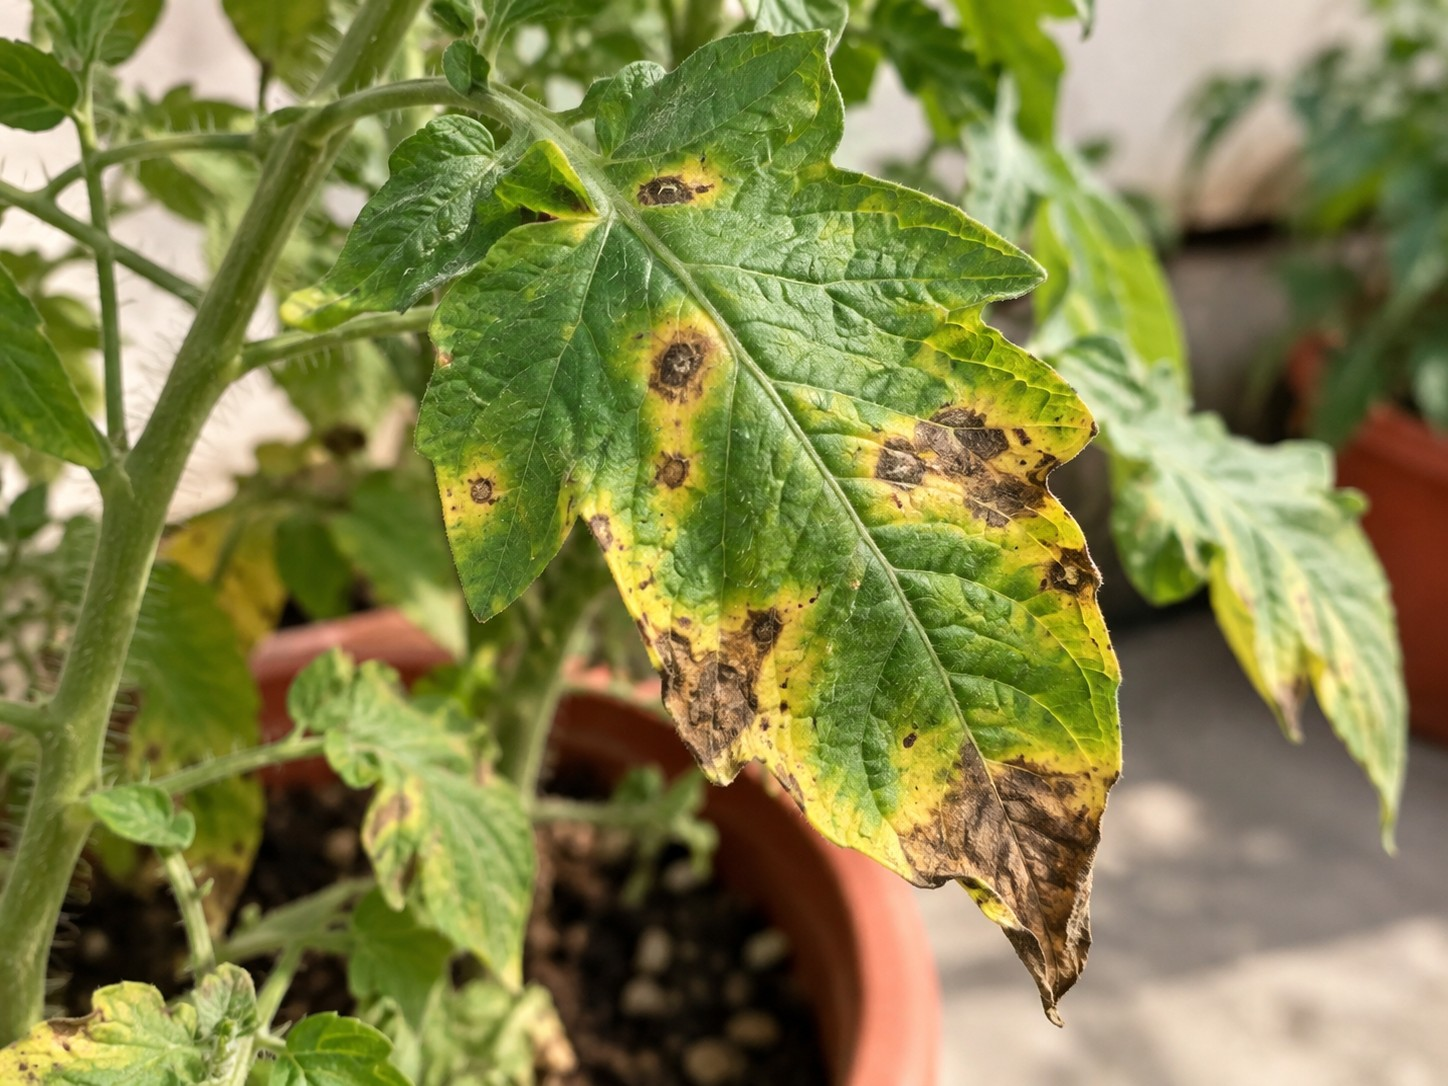

In [196]:
from pathlib import Path
from PIL import Image

test_image_path = Path(r"D:\PlantGuardian\AI\Datasets\plant_test.jpg")

assert test_image_path.exists(), (
    f"Test image not found: {test_image_path}"
)

with Image.open(test_image_path) as img:
    print("Image path:", test_image_path)
    print("Image format:", img.format)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)
    display(img.copy())

In [197]:
import inspect
import plant_pipeline

print("Pipeline functions:")
for name, obj in inspect.getmembers(plant_pipeline, inspect.isfunction):
    if not name.startswith("_"):
        print(f"\n{name}{inspect.signature(obj)}")

Pipeline functions:

analyze_plant_image(image_path, api_key, model_id, prompt)

match_plant_evidence(evidence_db, symptom_terms, observed_crop=None)

rank_plant_evidence(matches, symptom_terms)


In [198]:
import inspect

print(inspect.getsource(plant_pipeline.analyze_plant_image))

def analyze_plant_image(image_path, api_key, model_id, prompt):
    """Analyze a plant image through the OpenRouter Vision API."""
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not api_key:
        raise ValueError("API key is missing.")

    image_data = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    payload = {
        "model": model_id,
        "messages": [{
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{image_data}"
                    }
                }
            ]
        }],
        "max_tokens": 800
    }

    response = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {

In [199]:
print("API key variable exists:", "api_key" in globals())
print("Model ID variable exists:", "model_id" in globals())
print("Prompt variable exists:", "prompt" in globals())

API key variable exists: True
Model ID variable exists: False
Prompt variable exists: False


In [200]:
from pathlib import Path

project_root = Path(r"D:\PlantGuardian")

for file_path in [
    project_root / "AI" / "plant_pipeline.py",
    project_root / "AI" / "Notebooks" / "Plant.ipynb",
    project_root / "Frontend" / ".env",
]:
    print(f"\n--- {file_path.name} ---")
    print("Exists:", file_path.exists())


--- plant_pipeline.py ---
Exists: True

--- Plant.ipynb ---
Exists: True

--- .env ---
Exists: False


In [201]:
import json
from pathlib import Path

notebook_path = Path(
    r"D:\PlantGuardian\AI\Notebooks\Plant.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = ("openrouter", "model_id", "api_key", "prompt")

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(word in source.lower() for word in keywords):
        print(f"\n--- Notebook cell {i + 1} ---")

        # Avoid displaying secrets.
        for line in source.splitlines():
            if any(
                secret in line.lower()
                for secret in ("api_key", "authorization", "sk-or-")
            ):
                print("[API key-related line hidden]")
            else:
                print(line)


--- Notebook cell 26 ---
# Step 4.1 — Check API dependency

import requests

print("Requests version:", requests.__version__)
print("OpenRouter API endpoint configured:",
      "https://openrouter.ai/api/v1/chat/completions")

--- Notebook cell 27 ---
# Step 4.2 — Load OpenRouter API key securely

from pathlib import Path
from dotenv import load_dotenv
import os

current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if p.name == "PlantGuardian"),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "PlantGuardian folder not found from the notebook's working directory."
    )

env_file = project_root / ".env"

if not env_file.is_file():
    raise FileNotFoundError(f".env file not found: {env_file}")

load_dotenv(env_file, override=True)

[API key-related line hidden]

[API key-related line hidden]
    raise ValueError(
[API key-related line hidden]
    )

print("Project root found:", project_root)
print(".env file found:", 

In [202]:
import requests
import plant_pipeline

test_image_path = r"D:\PlantGuardian\AI\Datasets\plant_test.jpg"

assert "api_key" in globals() and api_key, "API key is missing."
assert "MODEL_ID" in globals() and MODEL_ID, "MODEL_ID is missing."
assert (
    "PLANT_ANALYSIS_PROMPT" in globals()
    and PLANT_ANALYSIS_PROMPT.strip()
), "PLANT_ANALYSIS_PROMPT is missing."

try:
    image_analysis = plant_pipeline.analyze_plant_image(
        image_path=test_image_path,
        api_key=api_key,
        model_id=MODEL_ID,
        prompt=PLANT_ANALYSIS_PROMPT,
    )

    assert isinstance(image_analysis, str) and image_analysis.strip(), (
        "Image analysis returned empty text."
    )

    print("Step 4.2 — Image analysis: PASS")
    print("Model:", MODEL_ID)
    print("\nImage analysis result:\n")
    print(image_analysis)

except Exception as error:
    print("Step 4.2 — Image analysis: FAIL")
    print("Error type:", type(error).__name__)
    print("Error:", error)

Step 4.2 — Image analysis: PASS
Model: moondream/moondream3-preview

Image analysis result:

{
  "Likely plant or crop": {
    "crop_name": "Tomato",
    "visible_signs": "Leaf discoloration (yellowing, brown spots), leaf curling/wilting, possible leaf damage/spots."
  },
  "Visible symptoms": {
    "leaf_color_changes": "Green with yellow/brown patches, brown spots, irregular leaf edges.",
    "spots_markings": "Multiple small, dark brown/black spots scattered across the leaf.",
    "curling_deformation": "Some leaves show curling or wilting, particularly at the edges."
  },
  "Possible causes": {
    "disease": "Early signs of bacterial leaf spot or similar fungal/bacterial infection.",
    "pest": "Possible aphids or small insects causing leaf discoloration and damage.",
    "nutrient_deficiency": "Yellowing leaf edges could indicate nutrient deficiency (e.g., iron, magnesium)."
  },
  "Confidence_and_limitations": {
    "uncertainty": "Uncertain due to limited view and partial leaf

In [203]:
# Step 4.3 — Verify image analysis and evidence ranking

assert isinstance(image_analysis, str) and image_analysis.strip(), (
    "Image analysis is missing."
)

assert len(evidence_db) > 0, "Evidence database is empty."

print("Image analysis available: PASS")
print("Evidence database available: PASS")
print("Image analysis mentions tomato:",
      "tomato" in image_analysis.lower())
print("Image analysis mentions yellowing:",
      "yellow" in image_analysis.lower())
print("Image analysis mentions brown spots:",
      "brown" in image_analysis.lower() and "spot" in image_analysis.lower())

print("\nPrevious evidence retrieval:")
print("Matched records:", len(matches))

print("\nPrevious disease ranking:")
print("Ranked records:", len(ranked_matches))

if not ranked_matches.empty:
    print("Top diagnosis:", ranked_matches.iloc[0]["diagnosis"])
    print("Top relevance score:",
          ranked_matches.iloc[0]["relevance_score"])

Image analysis available: PASS
Evidence database available: PASS
Image analysis mentions tomato: True
Image analysis mentions yellowing: True
Image analysis mentions brown spots: True

Previous evidence retrieval:
Matched records: 1

Previous disease ranking:
Ranked records: 1
Top diagnosis: Bacterial Wilt
Top relevance score: 0.6499999999999999


In [204]:
from pathlib import Path

project_root = Path(r"D:\PlantGuardian")
test_image_path = project_root / "AI" / "Datasets" / "plant_test.jpg"
pipeline_path = project_root / "AI" / "plant_pipeline.py"

checks = {
    "API key available": bool(globals().get("api_key")),
    "Vision model configured": bool(globals().get("MODEL_ID")),
    "Analysis prompt available": bool(
        globals().get("PLANT_ANALYSIS_PROMPT", "").strip()
    ),
    "Test image exists": test_image_path.is_file(),
    "Pipeline module exists": pipeline_path.is_file(),
    "Evidence database available": (
        "evidence_db" in globals()
        and not evidence_db.empty
    ),
    "Image analysis available": (
        "image_analysis" in globals()
        and isinstance(image_analysis, str)
        and bool(image_analysis.strip())
    ),
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print(
    f"\nStep 5.1 result: "
    f"{'PASS' if all(checks.values()) else 'REVIEW REQUIRED'}"
)

PASS: API key available
PASS: Vision model configured
PASS: Analysis prompt available
PASS: Test image exists
PASS: Pipeline module exists
PASS: Evidence database available
PASS: Image analysis available

Step 5.1 result: PASS


In [205]:
# Step 5.2 — Test image-analysis error handling

from pathlib import Path
import plant_pipeline

error_checks = {}

# Test 1: Missing image
try:
    plant_pipeline.analyze_plant_image(
        image_path=r"D:\PlantGuardian\AI\Datasets\missing_test_image.jpg",
        api_key=api_key,
        model_id=MODEL_ID,
        prompt=PLANT_ANALYSIS_PROMPT,
    )
except FileNotFoundError:
    error_checks["Missing image handled correctly"] = True
except Exception as error:
    error_checks["Missing image handled correctly"] = False
    print("Unexpected missing-image error:", type(error).__name__)
else:
    error_checks["Missing image handled correctly"] = False

# Test 2: Missing API key
try:
    plant_pipeline.analyze_plant_image(
        image_path=r"D:\PlantGuardian\AI\Datasets\plant_test.jpg",
        api_key="",
        model_id=MODEL_ID,
        prompt=PLANT_ANALYSIS_PROMPT,
    )
except ValueError as error:
    error_checks["Missing API key handled correctly"] = (
        str(error) == "API key is missing."
    )
except Exception as error:
    error_checks["Missing API key handled correctly"] = False
    print("Unexpected missing-key error:", type(error).__name__)
else:
    error_checks["Missing API key handled correctly"] = False

for name, passed in error_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print(
    "\nStep 5.2 result:",
    "PASS" if all(error_checks.values()) else "REVIEW REQUIRED"
)

PASS: Missing image handled correctly
PASS: Missing API key handled correctly

Step 5.2 result: PASS


In [206]:
# Step 5.3 — Final validation summary

final_checks = {
    "Image analysis succeeded": (
        isinstance(image_analysis, str)
        and bool(image_analysis.strip())
    ),
    "Evidence database available": (
        "evidence_db" in globals()
        and not evidence_db.empty
    ),
    "Disease ranking available": (
        "ranked_matches" in globals()
        and not ranked_matches.empty
    ),
    "Ranking scores valid": (
        "ranked_matches" in globals()
        and not ranked_matches.empty
        and ranked_matches["relevance_score"].between(0, 1).all()
    ),
    "Missing-image handling passed": (
        error_checks.get("Missing image handled correctly", False)
    ),
    "Missing-API-key handling passed": (
        error_checks.get("Missing API key handled correctly", False)
    ),
}

for name, passed in final_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

passed_count = sum(final_checks.values())
total_count = len(final_checks)

print(f"\nFinal checks passed: {passed_count}/{total_count}")
print(
    "Final validation:",
    "PASS" if all(final_checks.values()) else "REVIEW REQUIRED"
)

PASS: Image analysis succeeded
PASS: Evidence database available
PASS: Disease ranking available
PASS: Ranking scores valid
PASS: Missing-image handling passed
PASS: Missing-API-key handling passed

Final checks passed: 6/6
Final validation: PASS
